In [57]:

# EDA - SETUP, DATA LOADING AND VALIDATION

# Objectives:
# 1. Import libraries and configure the analysis environment.
# 2. Locate the project directory.
# 3. Load the cleaned master and modelling datasets.
# 4. Convert datetime columns using a consistent format.
# 5. Validate dataset sizes and appointment identifiers.
# 6. Validate the binary target and booking chronology.
# 7. Validate dynamic prediction timestamps.
# 8. Review attendance outcomes, data types and missing values.
# 9. Confirm readiness for exploratory data analysis.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configure pandas display options.

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 120)

# Configure chart appearance.

sns.set_theme(style="whitegrid")

print("CELL 1: EDA SETUP, DATA LOADING AND VALIDATION")

# 1. Locate the project directory.
# The notebook may run from the project root or notebooks folder.

CURRENT_DIR = Path.cwd()

if CURRENT_DIR.name.lower() == "notebooks":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
EDA_REPORT_DIR = PROJECT_ROOT / "reports" / "eda"

EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\n1. PROJECT DIRECTORIES")

print(f"Project root: {PROJECT_ROOT}")
print(f"Processed data: {PROCESSED_DATA_DIR}")
print(f"EDA reports: {EDA_REPORT_DIR}")

# 2. Define the updated dataset paths.
# These files were exported from 02_data_cleaning.ipynb.

MASTER_PATH = (
    PROCESSED_DATA_DIR / "outpatient_appointments_cleaned.csv"
)

MODEL_PATH = (
    PROCESSED_DATA_DIR / "outpatient_dna_modelling.csv"
)

assert MASTER_PATH.is_file(), (
    f"Cleaned master dataset not found: {MASTER_PATH}"
)

assert MODEL_PATH.is_file(), (
    f"Modelling dataset not found: {MODEL_PATH}"
)

print("\n2. DATASET FILES")

print(f"Master: {MASTER_PATH.name}")
print(f"Modelling: {MODEL_PATH.name}")

# 3. Load both datasets.
# The master contains all unique appointments.
# The modelling dataset contains eligible Attended and DNA records.

df_eda = pd.read_csv(MASTER_PATH)
df_binary = pd.read_csv(MODEL_PATH)

print("\n3. DATASET DIMENSIONS")

print(f"Cleaned master: {df_eda.shape}")
print(f"Binary modelling: {df_binary.shape}")

assert df_eda.shape == (40000, 23), (
    "Unexpected cleaned master dimensions."
)

assert df_binary.shape == (36264, 24), (
    "Unexpected modelling dataset dimensions."
)

# 4. Convert datetime columns.
# The cleaning notebook exported timestamps using:
# YYYY-MM-DD HH:MM:SS
#
# Explicitly specifying the format avoids datetime
# parsing warnings and ensures consistent conversion.
#
# Missing clinic check-in timestamps are expected.
# They remain NaT and are not filled.

datetime_columns = [
    "booked_datetime",
    "appointment_datetime",
    "clinic_checkin_time",
    "prediction_cutoff_datetime"
]

for dataset in [df_eda, df_binary]:
    for column in datetime_columns:
        if column in dataset.columns:
            dataset[column] = pd.to_datetime(
                dataset[column],
                format="%Y-%m-%d %H:%M:%S",
                errors="coerce"
            )

print("\n4. DATETIME VALIDATION")

required_dates = [
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime"
]

assert df_binary[required_dates].notna().all().all(), (
    "Missing or invalid modelling datetime values."
)

assert df_eda[
    ["booked_datetime", "appointment_datetime"]
].notna().all().all(), (
    "Missing or invalid master appointment dates."
)

print("Essential datetime fields validated.")

# 5. Validate appointment identifiers.
# Appointment IDs must be unique.
# A patient may legitimately have multiple appointments.

print("\n5. IDENTIFIER VALIDATION")

for dataset_name, dataset in [
    ("Master", df_eda),
    ("Modelling", df_binary)
]:
    assert dataset["appointment_id"].notna().all(), (
        f"Missing appointment IDs in {dataset_name}."
    )

    assert dataset["appointment_id"].is_unique, (
        f"Duplicate appointment IDs in {dataset_name}."
    )

assert df_binary["appointment_id"].isin(
    df_eda["appointment_id"]
).all(), (
    "Some modelling appointments are missing from the master."
)

print("Appointment IDs validated.")

# 6. Validate the binary target.
# DNA is the positive class (1).
# Attended is the negative class (0).

print("\n6. BINARY TARGET VALIDATION")

assert df_binary["dna_target"].isin([0, 1]).all(), (
    "Invalid binary target values."
)

assert set(
    df_binary["attendance_status"].unique()
) == {"Attended", "DNA"}, (
    "Unexpected attendance outcomes in modelling data."
)

assert (
    df_binary.loc[
        df_binary["attendance_status"] == "DNA",
        "dna_target"
    ] == 1
).all(), (
    "DNA appointments have incorrect target values."
)

assert (
    df_binary.loc[
        df_binary["attendance_status"] == "Attended",
        "dna_target"
    ] == 0
).all(), (
    "Attended appointments have incorrect target values."
)

target_counts = (
    df_binary["dna_target"]
    .value_counts()
    .sort_index()
)

attended_count = int(target_counts.get(0, 0))
dna_count = int(target_counts.get(1, 0))

dna_rate = df_binary["dna_target"].mean() * 100

print(f"Attended: {attended_count:,}")
print(f"DNA: {dna_count:,}")
print(f"DNA rate: {dna_rate:.2f}%")

assert attended_count == 32958, (
    "Unexpected Attended appointment count."
)

assert dna_count == 3306, (
    "Unexpected DNA appointment count."
)

# 7. Validate booking lead times.
# Eligible appointments must have a lead time
# between 0 and 301 days.

print("\n7. BOOKING CHRONOLOGY")

assert df_binary["booking_lead_days"].notna().all(), (
    "Missing booking lead times."
)

assert df_binary["booking_lead_days"].between(
    0, 301
).all(), (
    "Invalid booking lead times."
)

minimum_lead = df_binary["booking_lead_days"].min()
maximum_lead = df_binary["booking_lead_days"].max()

print(f"Minimum booking lead time: {minimum_lead:.3f} days")
print(f"Maximum booking lead time: {maximum_lead:.3f} days")

# 8. Validate the dynamic prediction strategy.
# Short-notice appointments are predicted at booking.
# Longer-notice appointments are predicted seven days
# before their scheduled appointment.

print("\n8. DYNAMIC PREDICTION VALIDATION")

short_notice_mask = df_binary["booking_lead_days"] < 7
long_notice_mask = df_binary["booking_lead_days"] >= 7

short_notice_count = int(short_notice_mask.sum())
long_notice_count = int(long_notice_mask.sum())

assert short_notice_count == 2697, (
    "Unexpected short-notice appointment count."
)

assert (
    short_notice_count + long_notice_count
    == len(df_binary)
), (
    "Short-notice and long-notice totals do not reconcile."
)

# Prediction timestamps must fall between booking
# and the scheduled appointment.

assert (
    df_binary["prediction_cutoff_datetime"]
    >= df_binary["booked_datetime"]
).all(), (
    "Prediction occurs before booking for some records."
)

assert (
    df_binary["prediction_cutoff_datetime"]
    <= df_binary["appointment_datetime"]
).all(), (
    "Prediction occurs after the appointment for some records."
)

# Short-notice appointments must be predicted at booking.

assert (
    df_binary.loc[
        short_notice_mask,
        "prediction_cutoff_datetime"
    ]
    == df_binary.loc[
        short_notice_mask,
        "booked_datetime"
    ]
).all(), (
    "Short-notice prediction timestamps are incorrect."
)

# Long-notice appointments must be predicted
# exactly seven days before their appointment.

assert np.allclose(
    df_binary.loc[
        long_notice_mask,
        "days_until_appointment_at_prediction"
    ],
    7.0
), (
    "Long-notice prediction intervals are incorrect."
)

print(f"Short-notice appointments: {short_notice_count:,}")
print(f"Long-notice appointments: {long_notice_count:,}")
print("Dynamic prediction timestamps validated.")

# 9. Review attendance outcomes in the master dataset.
# Cancellations remain available for descriptive analysis,
# although they are excluded from binary modelling.

print("\n9. MASTER ATTENDANCE OUTCOMES")

master_outcomes = (
    df_eda["attendance_status"]
    .value_counts(dropna=False)
    .rename_axis("attendance_status")
    .reset_index(name="appointments")
)

display(master_outcomes)

# 10. Review modelling dataset structure.
# Use reset_index() without the names argument
# for compatibility with older pandas versions.

print("\n10. MODELLING DATASET STRUCTURE")

print("\nColumn names:")
print(df_binary.columns.tolist())

print("\nData types:")

data_types = df_binary.dtypes.reset_index()

data_types.columns = ["column", "dtype"]

display(data_types)

# 11. Review missing values.
# This is descriptive analysis only.

print("\n11. MISSING VALUES")

missing_summary = pd.DataFrame({
    "missing_count": df_binary.isna().sum(),
    "missing_percent": (
        df_binary.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.loc[
    missing_summary["missing_count"] > 0
].sort_values(
    "missing_count",
    ascending=False
)

display(missing_summary)

print(
    "\nMissing values will be handled during feature "
    "engineering and model training using training-only "
    "preprocessing."
)

# 12. Confirm readiness for subsequent EDA cells.
# No rows or columns are removed in this cell.

print("\n12. FINAL VALIDATION SUMMARY")

print("Master dataset: PASSED")
print("Modelling dataset: PASSED")
print("Appointment identifiers: PASSED")
print("Binary target: PASSED")
print("Booking chronology: PASSED")
print("Dynamic prediction timestamps: PASSED")
print("Short-notice appointments: INCLUDED")
print("Missing values: REVIEWED")

print("\nCELL 1 COMPLETED SUCCESSFULLY")
print("Ready for updated Cell 2: DNA target distribution.")


CELL 1: EDA SETUP, DATA LOADING AND VALIDATION

1. PROJECT DIRECTORIES
Project root: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction
Processed data: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\data\processed
EDA reports: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda

2. DATASET FILES
Master: outpatient_appointments_cleaned.csv
Modelling: outpatient_dna_modelling.csv

3. DATASET DIMENSIONS
Cleaned master: (40000, 23)
Binary modelling: (36264, 24)

4. DATETIME VALIDATION
Essential datetime fields validated.

5. IDENTIFIER VALIDATION
Appointment IDs validated.

6. BINARY TARGET VALIDATION
Attended: 32,958
DNA: 3,306
DNA rate: 9.12%

7. BOOKING CHRONOLOGY
Minimum booking lead time: 0.021 days
Maximum booking lead time: 300.275 days

8. DYNAMIC PREDICTION VALIDATION
Short-notice appointments: 2,697
Long-notice appointments: 33,567
Dynamic prediction timestamps validated.

9. MASTER ATTENDANCE OUTCOMES


,attendance_status,appointments
0,Attended,33048
1,DNA,3316
2,Cancelled by patient,2421
3,Cancelled by hospital,1215



10. MODELLING DATASET STRUCTURE

Column names:
['appointment_id', 'patient_id', 'age', 'sex', 'imd_decile', 'ethnic_group', 'distance_km', 'interpreter_required', 'long_term_conditions', 'specialty', 'appointment_type', 'consultation_mode', 'referral_source', 'appointment_datetime', 'booked_datetime', 'rescheduled_count', 'sms_reminder_sent', 'previous_dnas_12m', 'attendance_status', 'clinic_checkin_time', 'booking_lead_days', 'prediction_cutoff_datetime', 'days_until_appointment_at_prediction', 'dna_target']

Data types:


,column,dtype
0,appointment_id,str
1,patient_id,str
2,age,float64
3,sex,str
4,imd_decile,float64
5,ethnic_group,str
6,distance_km,float64
7,interpreter_required,str
8,long_term_conditions,int64
9,specialty,str



11. MISSING VALUES


,missing_count,missing_percent
clinic_checkin_time,36264,100.00
imd_decile,1265,3.49
distance_km,362,1.00
age,48,0.13



Missing values will be handled during feature engineering and model training using training-only preprocessing.

12. FINAL VALIDATION SUMMARY
Master dataset: PASSED
Modelling dataset: PASSED
Appointment identifiers: PASSED
Binary target: PASSED
Booking chronology: PASSED
Dynamic prediction timestamps: PASSED
Short-notice appointments: INCLUDED
Missing values: REVIEWED

CELL 1 COMPLETED SUCCESSFULLY
Ready for updated Cell 2: DNA target distribution.


ATTENDANCE OUTCOME DISTRIBUTION AND DNA RATES

1. ELIGIBLE APPOINTMENTS
Total eligible appointments: 36,264

2. ATTENDANCE OUTCOME DISTRIBUTION


,attendance_outcome,dna_target,appointments,percentage
0,Attended,0,32958,90.88
1,DNA,1,3306,9.12



3. OVERALL DNA RATE
Attended appointments: 32,958
DNA appointments: 3,306
Attended rate: 90.88%
DNA rate: 9.12%

4. ATTENDANCE OUTCOME CHART


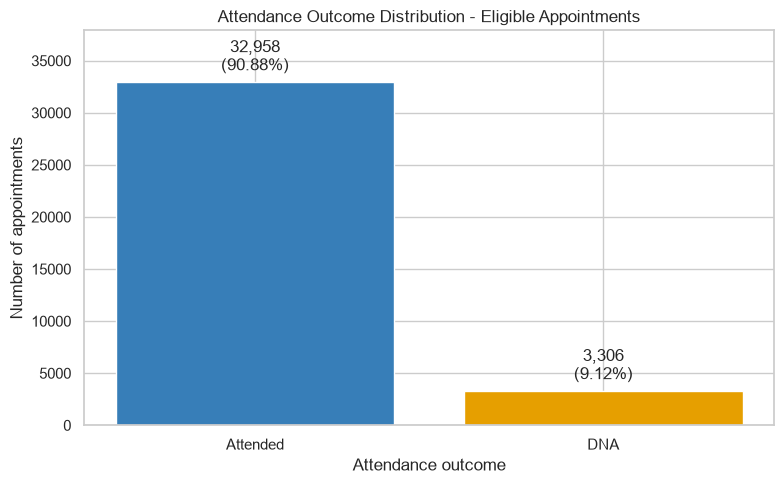

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\attendance_outcome_distribution.png

5. BOOKING NOTICE GROUPS
booking_notice_group
Short notice (<7 days)     2697
Long notice (7+ days)     33567
Name: count, dtype: int64

6. DNA RATE BY BOOKING NOTICE


,booking_notice_group,appointments,attended_count,dna_count,dna_rate_percent
0,Short notice (<7 days),2697,2502,195,7.23
1,Long notice (7+ days),33567,30456,3111,9.27



7. DNA RATE BY BOOKING NOTICE CHART


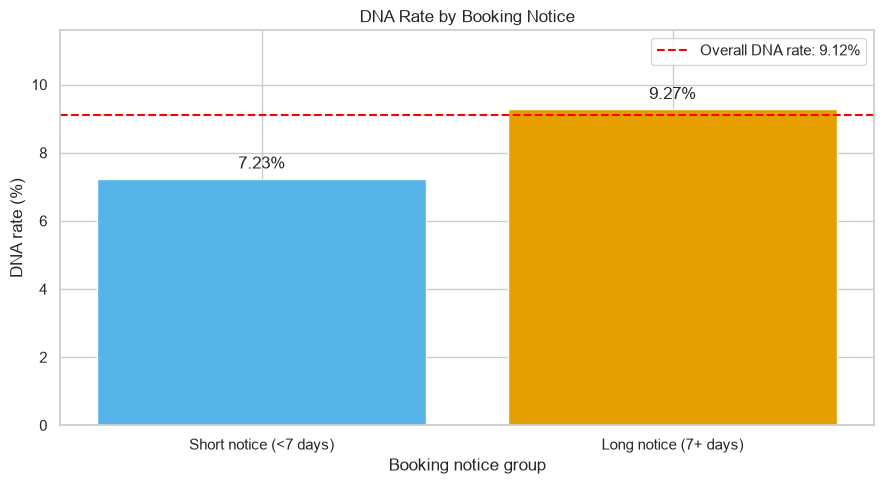

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_booking_notice.png

8. BOOKING NOTICE COMPARISON
Short-notice DNA rate: 7.23%
Long-notice DNA rate: 9.27%
Difference (short minus long): -2.04 percentage points
Observed DNA rates are higher among long-notice appointments.
These results describe an association, not a causal relationship.

9. SAVE EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\attendance_outcome_distribution.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_booking_notice.csv

10. KEY EDA FINDINGS
The eligible dataset contains 36,264 appointments.
Of these, 32,958 were attended and 3,306 were missed.
The overall DNA rate is 9.12%.
The analysis includes 2,697 short-notice appointments and 33,567 long-notice appointments.
The observed difference in DNA rates between booking groups is 2.04 percentage points.
Further EDA will examine a

In [58]:

# ATTENDANCE OUTCOME DISTRIBUTION AND DNA RATES


# Objectives:
# 1. Examine the distribution of Attended and DNA appointments.
# 2. Calculate the overall DNA rate.
# 3. Visualise attendance outcomes.
# 4. Compare DNA rates by booking notice.
# 5. Visualise differences between booking notice groups.
# 6. Save descriptive results and charts.
# 7. Summarise the main EDA findings.

print("ATTENDANCE OUTCOME DISTRIBUTION AND DNA RATES")

# 1. Confirm that the updated modelling dataset is available.
# This dataset was loaded and validated in Cell 1.
# It contains only eligible Attended and DNA appointments.

total_appointments = len(df_binary)

assert total_appointments == 36264, (
    "Unexpected number of eligible appointments."
)

assert df_binary["dna_target"].isin([0, 1]).all(), (
    "Unexpected target values."
)

print("\n1. ELIGIBLE APPOINTMENTS")
print(f"Total eligible appointments: {total_appointments:,}")

# 2. Calculate attendance outcome counts and percentages.
# DNA = 1 means the appointment was missed.
# Attended = 0 means the patient attended.

attendance_summary = (
    df_binary["dna_target"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("dna_target")
    .reset_index(name="appointments")
)

attendance_summary["attendance_outcome"] = (
    attendance_summary["dna_target"].map({
        0: "Attended",
        1: "DNA"
    })
)

attendance_summary["percentage"] = (
    attendance_summary["appointments"]
    / total_appointments
    * 100
).round(2)

attendance_summary = attendance_summary[
    [
        "attendance_outcome",
        "dna_target",
        "appointments",
        "percentage"
    ]
]

print("\n2. ATTENDANCE OUTCOME DISTRIBUTION")
display(attendance_summary)

# 3. Calculate the overall DNA rate.
# This describes how common missed appointments are
# in the eligible modelling population.

attended_count = int(
    (df_binary["dna_target"] == 0).sum()
)

dna_count = int(
    (df_binary["dna_target"] == 1).sum()
)

attended_rate = (
    attended_count / total_appointments * 100
)

dna_rate = (
    dna_count / total_appointments * 100
)

print("\n3. OVERALL DNA RATE")

print(f"Attended appointments: {attended_count:,}")
print(f"DNA appointments: {dna_count:,}")
print(f"Attended rate: {attended_rate:.2f}%")
print(f"DNA rate: {dna_rate:.2f}%")

assert attended_count == 32958
assert dna_count == 3306
assert attended_count + dna_count == total_appointments

# 4. Visualise the attendance outcome distribution.
# Counts and percentages are shown above each bar.

print("\n4. ATTENDANCE OUTCOME CHART")

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    attendance_summary["attendance_outcome"],
    attendance_summary["appointments"],
    color=["#377eb8", "#e69f00"]
)

for bar, count, percentage in zip(
    bars,
    attendance_summary["appointments"],
    attendance_summary["percentage"]
):
    ax.annotate(
        f"{count:,}\n({percentage:.2f}%)",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_title(
    "Attendance Outcome Distribution - Eligible Appointments"
)

ax.set_xlabel("Attendance outcome")
ax.set_ylabel("Number of appointments")
ax.set_ylim(0, attended_count * 1.15)

plt.tight_layout()

attendance_chart_path = (
    EDA_REPORT_DIR / "attendance_outcome_distribution.png"
)

plt.savefig(
    attendance_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {attendance_chart_path}")

# 5. Create booking notice groups.
# Short notice: appointment booked less than 7 days ahead.
# Long notice: appointment booked 7 or more days ahead.
#
# Use a separate EDA column for descriptive analysis.
# This does not alter the original exported CSV.

df_binary["booking_notice_group"] = np.where(
    df_binary["booking_lead_days"] < 7,
    "Short notice (<7 days)",
    "Long notice (7+ days)"
)

notice_order = [
    "Short notice (<7 days)",
    "Long notice (7+ days)"
]

print("\n5. BOOKING NOTICE GROUPS")

print(
    df_binary["booking_notice_group"]
    .value_counts()
    .reindex(notice_order, fill_value=0)
)

# 6. Calculate DNA rates by booking notice.
# DNA rate = number of missed appointments
# divided by total appointments within each group.

notice_summary = (
    df_binary
    .groupby("booking_notice_group")["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reindex(notice_order)
    .reset_index()
)

notice_summary["attended_count"] = (
    notice_summary["appointments"]
    - notice_summary["dna_count"]
)

notice_summary["dna_rate_percent"] = (
    notice_summary["dna_rate"] * 100
).round(2)

notice_summary = notice_summary[
    [
        "booking_notice_group",
        "appointments",
        "attended_count",
        "dna_count",
        "dna_rate_percent"
    ]
]

print("\n6. DNA RATE BY BOOKING NOTICE")
display(notice_summary)

assert notice_summary["appointments"].sum() == total_appointments

short_notice_count = int(
    notice_summary.loc[
        notice_summary["booking_notice_group"]
        == "Short notice (<7 days)",
        "appointments"
    ].iloc[0]
)

long_notice_count = int(
    notice_summary.loc[
        notice_summary["booking_notice_group"]
        == "Long notice (7+ days)",
        "appointments"
    ].iloc[0]
)

assert short_notice_count == 2697
assert long_notice_count == 33567

# 7. Visualise DNA rates by booking notice.
# Compare percentages rather than only raw DNA counts,
# because the two groups have different population sizes.

print("\n7. DNA RATE BY BOOKING NOTICE CHART")

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    notice_summary["booking_notice_group"],
    notice_summary["dna_rate_percent"],
    color=["#56b4e9", "#e69f00"]
)

for bar, rate in zip(
    bars,
    notice_summary["dna_rate_percent"]
):
    ax.annotate(
        f"{rate:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.axhline(
    y=dna_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall DNA rate: {dna_rate:.2f}%"
)

ax.set_title("DNA Rate by Booking Notice")
ax.set_xlabel("Booking notice group")
ax.set_ylabel("DNA rate (%)")

ax.set_ylim(
    0,
    max(
        notice_summary["dna_rate_percent"].max(),
        dna_rate
    ) * 1.25
)

ax.legend()

plt.tight_layout()

notice_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_booking_notice.png"
)

plt.savefig(
    notice_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {notice_chart_path}")

# 8. Calculate the difference in DNA rates.
# This is an observed association.
# It does not demonstrate that booking notice
# directly causes missed appointments.

short_notice_rate = float(
    notice_summary.loc[
        notice_summary["booking_notice_group"]
        == "Short notice (<7 days)",
        "dna_rate_percent"
    ].iloc[0]
)

long_notice_rate = float(
    notice_summary.loc[
        notice_summary["booking_notice_group"]
        == "Long notice (7+ days)",
        "dna_rate_percent"
    ].iloc[0]
)

rate_difference = short_notice_rate - long_notice_rate

print("\n8. BOOKING NOTICE COMPARISON")

print(f"Short-notice DNA rate: {short_notice_rate:.2f}%")
print(f"Long-notice DNA rate: {long_notice_rate:.2f}%")

print(
    f"Difference (short minus long): "
    f"{rate_difference:+.2f} percentage points"
)

if rate_difference > 0:
    print(
        "Observed DNA rates are higher among "
        "short-notice appointments."
    )
elif rate_difference < 0:
    print(
        "Observed DNA rates are higher among "
        "long-notice appointments."
    )
else:
    print(
        "Both booking notice groups have "
        "the same rounded DNA rate."
    )

print(
    "These results describe an association, "
    "not a causal relationship."
)

# 9. Save descriptive EDA results.
# These tables and figures can be reused in the report.

print("\n9. SAVE EDA RESULTS")

attendance_summary_path = (
    EDA_REPORT_DIR / "attendance_outcome_distribution.csv"
)

notice_summary_path = (
    EDA_REPORT_DIR / "dna_rate_by_booking_notice.csv"
)

attendance_summary.to_csv(
    attendance_summary_path,
    index=False
)

notice_summary.to_csv(
    notice_summary_path,
    index=False
)

print(f"Saved: {attendance_summary_path}")
print(f"Saved: {notice_summary_path}")

# 10. Summarise the main EDA findings.

print("\n10. KEY EDA FINDINGS")

print(
    f"The eligible dataset contains "
    f"{total_appointments:,} appointments."
)

print(
    f"Of these, {attended_count:,} were attended "
    f"and {dna_count:,} were missed."
)

print(
    f"The overall DNA rate is {dna_rate:.2f}%."
)

print(
    f"The analysis includes {short_notice_count:,} "
    "short-notice appointments and "
    f"{long_notice_count:,} long-notice appointments."
)

print(
    f"The observed difference in DNA rates "
    f"between booking groups is "
    f"{abs(rate_difference):.2f} percentage points."
)

print(
    "Further EDA will examine appointment timing, "
    "patient characteristics and attendance history."
)

print("\nCELL 2 COMPLETED SUCCESSFULLY")
print("Ready for updated Cell 3: Appointment timing and booking patterns.")


CELL 3: APPOINTMENT TIMING AND BOOKING PATTERNS

1. BOOKING LEAD-TIME SUMMARY


,attendance_status,appointments,mean_days,median_days,minimum_days,maximum_days
0,Attended,32958,45.21,35.89,0.02,299.79
1,DNA,3306,53.88,42.84,0.15,300.27



2. BOOKING LEAD-TIME DISTRIBUTION


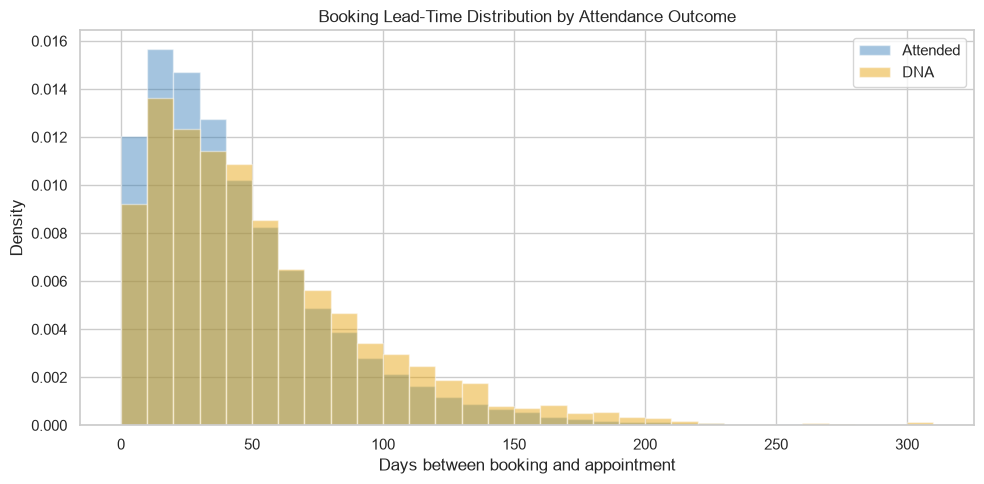


3. BOOKING LEAD-TIME BANDS


,booking_lead_band,appointments,attended_count,dna_count,dna_rate_percent
0,0–<1 day,182,166,16,8.79
1,1–<7 days,2515,2336,179,7.12
2,7–<14 days,3788,3478,310,8.18
3,14–<30 days,8643,7986,657,7.60
4,30–<60 days,11308,10288,1020,9.02
5,60–<90 days,5568,5012,556,9.99
6,90–<180 days,3950,3442,508,12.86
7,180–301 days,310,250,60,19.35



4. DNA RATE BY BOOKING LEAD TIME


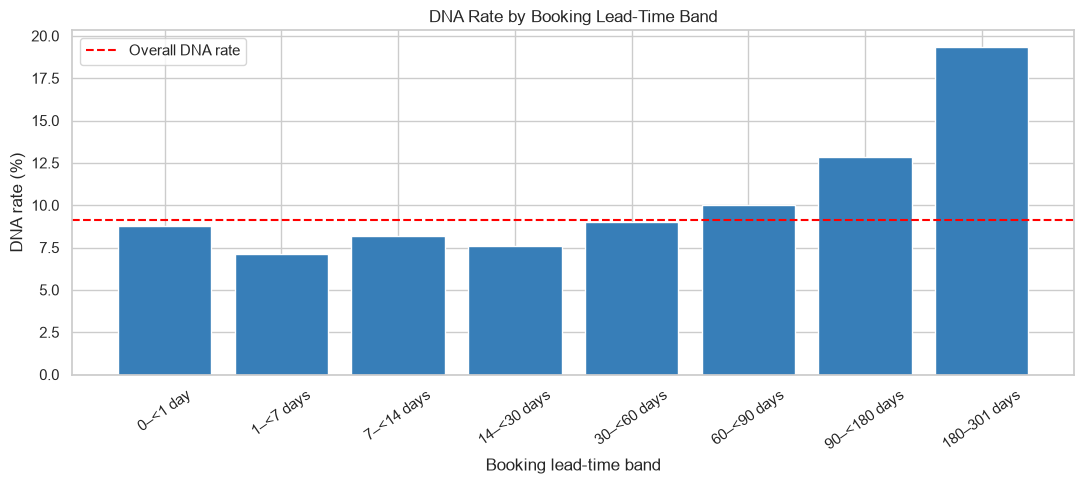


5. DNA RATE BY APPOINTMENT WEEKDAY


,appointment_weekday,appointments,dna_count,dna_rate,dna_rate_percent
0,Monday,15566.0,1518.0,0.097520,9.75
1,Tuesday,5137.0,428.0,0.083317,8.33
2,Wednesday,5207.0,420.0,0.080661,8.07
3,Thursday,5149.0,466.0,0.090503,9.05
4,Friday,5205.0,474.0,0.091066,9.11
5,Saturday,NaN,NaN,NaN,NaN
6,Sunday,NaN,NaN,NaN,NaN


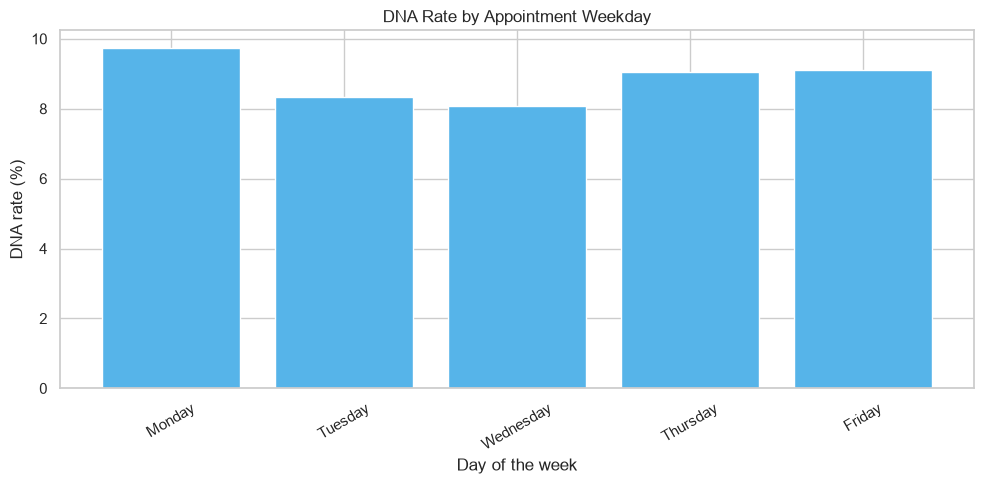


6. MONTHLY APPOINTMENT PATTERNS


,appointment_month,appointments,dna_count,dna_rate,dna_rate_percent
0,2025-04,2941,298,0.101326,10.13
1,2025-05,2994,269,0.089846,8.98
2,2025-06,3069,312,0.101662,10.17
3,2025-07,3106,263,0.084675,8.47
4,2025-08,2890,275,0.095156,9.52
5,2025-09,3168,271,0.085543,8.55
6,2025-10,2997,267,0.089089,8.91
7,2025-11,2749,207,0.075300,7.53
8,2025-12,3307,306,0.092531,9.25
9,2026-01,3056,280,0.091623,9.16


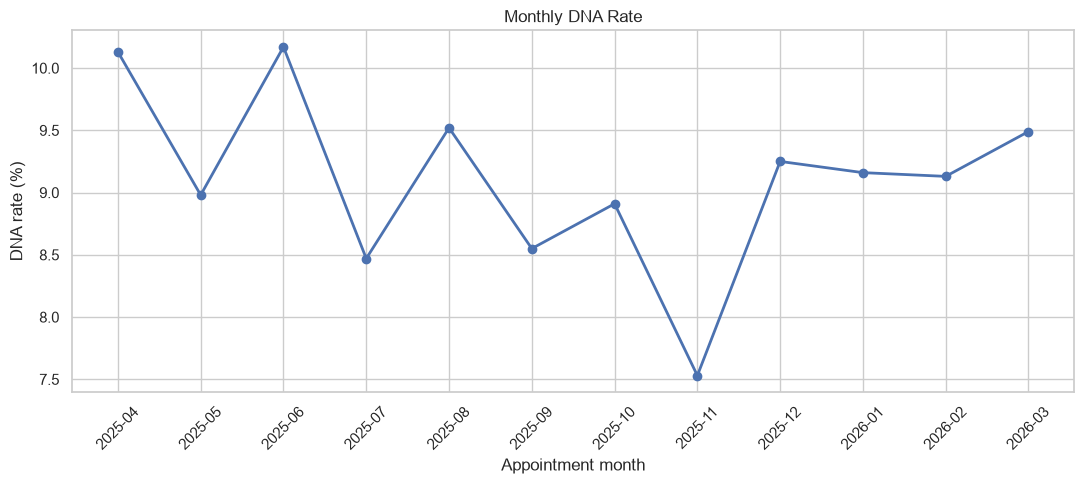


7. PREDICTION TIMING SUMMARY


,prediction_group,appointments,dna_count,dna_rate,dna_rate_percent
0,7 days before appointment,33567,3111,0.092680,9.27
1,At booking (<7 days notice),2697,195,0.072303,7.23



8. SAVE EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\booking_lead_time_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_booking_lead_band.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_appointment_weekday.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\monthly_dna_rate.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\prediction_timing_summary.csv

9. KEY EDA FINDINGS
Booking lead times range from 0.02 to 300.27 days.
The highest observed DNA rate by booking band is 19.35% in the 180–301 days group (310 appointments).
Booking timing and appointment calendar patterns are descriptive associations, not causal findings.
Feature availability at prediction time will be reviewed before modelling.

CELL 3 COMPLETED SUCCESSFULLY
Ready for updated Cell 4: Age and DNA patte

In [59]:

# APPOINTMENT TIMING AND BOOKING PATTERNS


# Objectives:
# 1. Explore booking lead-time distributions.
# 2. Compare lead times for Attended and DNA appointments.
# 3. Calculate DNA rates across booking lead-time bands.
# 4. Examine appointment weekday and monthly patterns.
# 5. Check the dynamic prediction timing strategy.
# 6. Save EDA tables and charts.

print("CELL 3: APPOINTMENT TIMING AND BOOKING PATTERNS")

# Work on a separate copy to preserve df_binary.
df_timing = df_binary.copy()

assert len(df_timing) == 36264
assert df_timing["booking_lead_days"].between(0, 301).all()

# 1. Summarise booking lead times.

print("\n1. BOOKING LEAD-TIME SUMMARY")

lead_summary = (
    df_timing.groupby("attendance_status")["booking_lead_days"]
    .agg(
        appointments="count",
        mean_days="mean",
        median_days="median",
        minimum_days="min",
        maximum_days="max"
    )
    .round(2)
    .reset_index()
)

display(lead_summary)

# 2. Visualise booking lead-time distributions.
# Compare the shapes of the distributions by outcome.
# Density normalisation accounts for different group sizes.

print("\n2. BOOKING LEAD-TIME DISTRIBUTION")

fig, ax = plt.subplots(figsize=(10, 5))

for outcome, color in [
    ("Attended", "#377eb8"),
    ("DNA", "#e69f00")
]:
    values = df_timing.loc[
        df_timing["attendance_status"] == outcome,
        "booking_lead_days"
    ].dropna()

    ax.hist(
        values,
        bins=np.arange(0, 311, 10),
        density=True,
        alpha=0.45,
        label=outcome,
        color=color
    )

ax.set_title("Booking Lead-Time Distribution by Attendance Outcome")
ax.set_xlabel("Days between booking and appointment")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()

lead_distribution_path = (
    EDA_REPORT_DIR / "booking_lead_time_distribution.png"
)

plt.savefig(lead_distribution_path, dpi=300, bbox_inches="tight")
plt.show()

# 3. Create booking lead-time bands.
# Include all eligible bookings from 0 to 301 days.
# The bands are descriptive and do not exclude records.

print("\n3. BOOKING LEAD-TIME BANDS")

lead_bins = [0, 1, 7, 14, 30, 60, 90, 180, 301]

lead_labels = [
    "0–<1 day",
    "1–<7 days",
    "7–<14 days",
    "14–<30 days",
    "30–<60 days",
    "60–<90 days",
    "90–<180 days",
    "180–301 days"
]

df_timing["booking_lead_band"] = pd.cut(
    df_timing["booking_lead_days"],
    bins=lead_bins,
    labels=lead_labels,
    right=False,
    include_lowest=True
)

assert df_timing["booking_lead_band"].notna().all()

lead_band_summary = (
    df_timing.groupby(
        "booking_lead_band",
        observed=True
    )["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reindex(lead_labels)
    .reset_index()
)

lead_band_summary["attended_count"] = (
    lead_band_summary["appointments"]
    - lead_band_summary["dna_count"]
)

lead_band_summary["dna_rate_percent"] = (
    lead_band_summary["dna_rate"] * 100
).round(2)

display(
    lead_band_summary[
        [
            "booking_lead_band",
            "appointments",
            "attended_count",
            "dna_count",
            "dna_rate_percent"
        ]
    ]
)

assert lead_band_summary["appointments"].sum() == len(df_timing)

# 4. Plot DNA rates by booking lead-time band.

print("\n4. DNA RATE BY BOOKING LEAD TIME")

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    lead_band_summary["booking_lead_band"].astype(str),
    lead_band_summary["dna_rate_percent"],
    color="#377eb8"
)

ax.axhline(
    df_timing["dna_target"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall DNA rate"
)

ax.set_title("DNA Rate by Booking Lead-Time Band")
ax.set_xlabel("Booking lead-time band")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=35)
ax.legend()

plt.tight_layout()

lead_rate_path = (
    EDA_REPORT_DIR / "dna_rate_by_booking_lead_band.png"
)

plt.savefig(lead_rate_path, dpi=300, bbox_inches="tight")
plt.show()

# 5. Explore appointment day of the week.
# Derive weekday from the scheduled appointment date.

print("\n5. DNA RATE BY APPOINTMENT WEEKDAY")

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

df_timing["appointment_weekday"] = (
    df_timing["appointment_datetime"].dt.day_name()
)

weekday_summary = (
    df_timing.groupby("appointment_weekday")["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reindex(weekday_order)
    .reset_index()
)

weekday_summary["dna_rate_percent"] = (
    weekday_summary["dna_rate"] * 100
).round(2)

display(weekday_summary)

assert weekday_summary["appointments"].sum() == len(df_timing)

fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    weekday_summary["appointment_weekday"],
    weekday_summary["dna_rate_percent"],
    color="#56b4e9"
)

ax.set_title("DNA Rate by Appointment Weekday")
ax.set_xlabel("Day of the week")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=30)

plt.tight_layout()

weekday_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_appointment_weekday.png"
)

plt.savefig(weekday_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Explore appointment month.
# Keep year and month together so different years
# are not accidentally combined.

print("\n6. MONTHLY APPOINTMENT PATTERNS")

df_timing["appointment_month"] = (
    df_timing["appointment_datetime"]
    .dt.to_period("M")
    .astype(str)
)

monthly_summary = (
    df_timing.groupby("appointment_month")["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reset_index()
    .sort_values("appointment_month")
)

monthly_summary["dna_rate_percent"] = (
    monthly_summary["dna_rate"] * 100
).round(2)

display(monthly_summary)

assert monthly_summary["appointments"].sum() == len(df_timing)

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    monthly_summary["appointment_month"],
    monthly_summary["dna_rate_percent"],
    marker="o",
    linewidth=2
)

ax.set_title("Monthly DNA Rate")
ax.set_xlabel("Appointment month")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()

monthly_chart_path = (
    EDA_REPORT_DIR / "monthly_dna_rate.png"
)

plt.savefig(monthly_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 7. Review dynamic prediction timing.
# This is a descriptive check of the prediction strategy.


print("\n7. PREDICTION TIMING SUMMARY")

df_timing["prediction_group"] = np.where(
    df_timing["booking_lead_days"] < 7,
    "At booking (<7 days notice)",
    "7 days before appointment"
)

prediction_summary = (
    df_timing.groupby("prediction_group")["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reset_index()
)

prediction_summary["dna_rate_percent"] = (
    prediction_summary["dna_rate"] * 100
).round(2)

display(prediction_summary)

assert prediction_summary["appointments"].sum() == 36264

# 8. Save EDA results.

print("\n8. SAVE EDA RESULTS")

eda_tables = {
    "booking_lead_time_summary.csv": lead_summary,
    "dna_rate_by_booking_lead_band.csv": lead_band_summary,
    "dna_rate_by_appointment_weekday.csv": weekday_summary,
    "monthly_dna_rate.csv": monthly_summary,
    "prediction_timing_summary.csv": prediction_summary
}

for filename, table in eda_tables.items():
    output_path = EDA_REPORT_DIR / filename
    table.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

# 9. Summarise findings without assuming their direction.

print("\n9. KEY EDA FINDINGS")

print(
    f"Booking lead times range from "
    f"{df_timing['booking_lead_days'].min():.2f} to "
    f"{df_timing['booking_lead_days'].max():.2f} days."
)

highest_band = lead_band_summary.loc[
    lead_band_summary["dna_rate_percent"].idxmax()
]

print(
    f"The highest observed DNA rate by booking band "
    f"is {highest_band['dna_rate_percent']:.2f}% "
    f"in the {highest_band['booking_lead_band']} group "
    f"({int(highest_band['appointments']):,} appointments)."
)

print(
    "Booking timing and appointment calendar patterns "
    "are descriptive associations, not causal findings."
)

print(
    "Feature availability at prediction time will "
    "be reviewed before modelling."
)

print("\nCELL 3 COMPLETED SUCCESSFULLY")
print("Ready for updated Cell 4: Age and DNA patterns.")


PATIENT AGE AND DNA PATTERNS

1. AGE DATA QUALITY
Total appointments: 36,264
Valid ages: 36,216
Missing ages: 48
Missing percentage: 0.13%

Missing ages are retained in the dataset. Age-based summaries exclude missing ages only where necessary.

2. OVERALL AGE DISTRIBUTION


,age
count,36216.00
mean,52.33
std,25.38
min,0.00
25%,31.00
50%,58.00
75%,74.00
max,118.00



3. AGE BY ATTENDANCE OUTCOME


,attendance_status,valid_ages,mean_age,median_age,minimum_age,maximum_age,standard_deviation
0,Attended,32913,52.69,59.0,0.0,118.0,25.28
1,DNA,3303,48.70,49.0,0.0,99.0,26.12



4. AGE DISTRIBUTION CHART


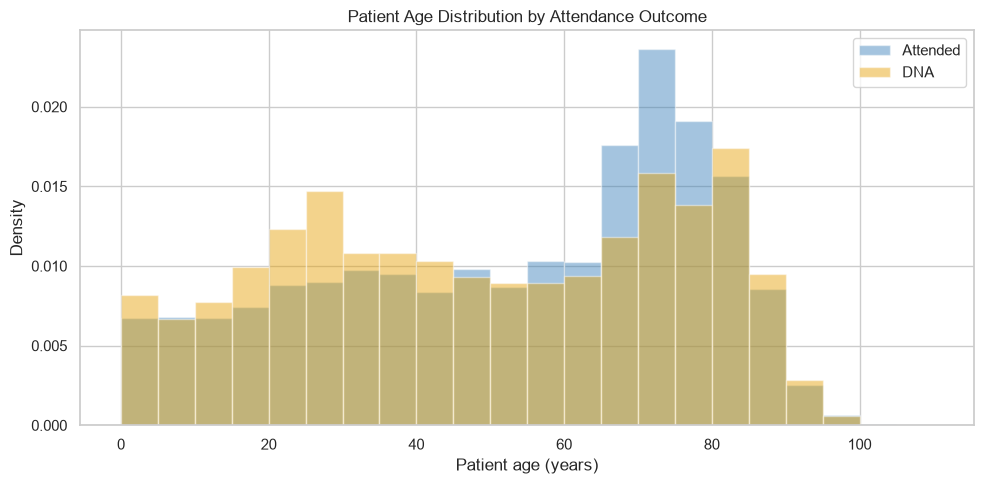

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\age_distribution_by_attendance.png

5. CREATE AGE GROUPS

6. DNA RATE BY AGE GROUP


,age_group,appointments,attended_count,dna_count,dna_rate_percent
0,Under 18,4416,3958,458,10.37
1,18–29,4067,3541,526,12.93
2,30–44,5067,4539,528,10.42
3,45–59,5192,4743,449,8.65
4,60–74,9075,8463,612,6.74
5,75–89,7802,7129,673,8.63
6,90+,597,540,57,9.55
7,Missing age,48,45,3,6.25



7. DNA RATE BY AGE GROUP CHART


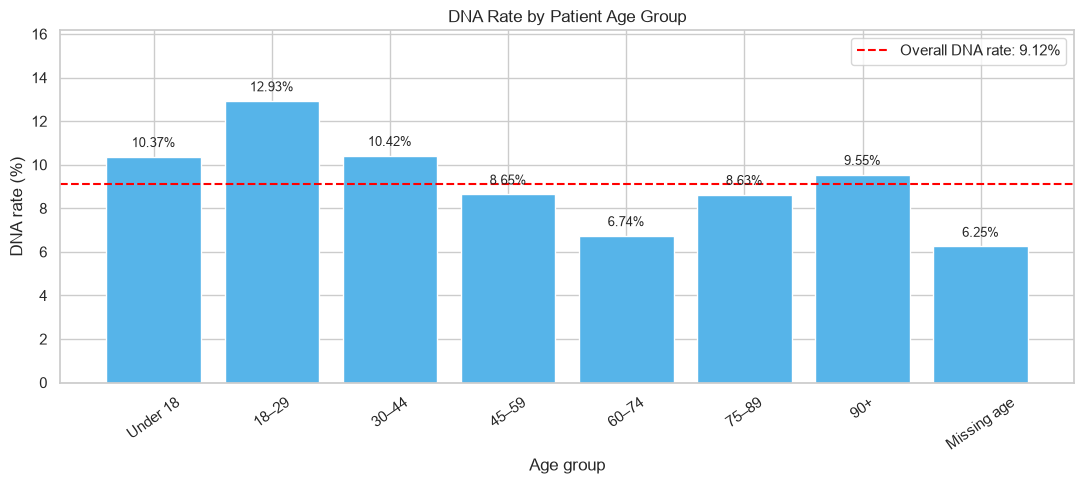

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_age_group.png

8. MISSING AGE BY ATTENDANCE OUTCOME


,attendance_status,appointments,missing_age_count,missing_age_rate,missing_age_percent
0,Attended,32958,45,0.001365,0.14
1,DNA,3306,3,0.000907,0.09



9. SAVE AGE ANALYSIS RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\age_summary_by_attendance.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_age_group.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\missing_age_by_attendance.csv

10. KEY AGE FINDINGS
Highest observed DNA rate: 18–29 (12.93%, 4,067 appointments).
Lowest observed DNA rate: Missing age (6.25%, 48 appointments).
Missing age values: 48 (0.13%).

Age-related differences are descriptive associations and do not establish causation.
Age is a potential predictive feature, but its use must be evaluated for model performance and fairness.
Missing ages will not be imputed during EDA. Any imputation will be fitted on training data only.

CELL 4 COMPLETED SUCCESSFULLY
Ready for updated: Sex, ethnicity and deprivation.


In [60]:

# PATIENT AGE AND DNA PATTERNS


# Objectives:
# 1. Examine patient age distribution.
# 2. Review missing age values after cleaning.
# 3. Compare ages for Attended and DNA appointments.
# 4. Calculate DNA rates across age groups.
# 5. Visualise age-related attendance patterns.
# 6. Save descriptive tables and charts.
# 7. Summarise findings without assuming causation.

print("PATIENT AGE AND DNA PATTERNS")

# 1. Create a separate dataframe for age analysis.
# This preserves the original EDA and modelling datasets.

df_age = df_binary.copy()

assert len(df_age) == 36264

# Ensure age is numeric.
# Invalid ages were converted to missing values
# during data cleaning.

df_age["age"] = pd.to_numeric(
    df_age["age"],
    errors="coerce"
)

# 2. Review age completeness and validity.


print("\n1. AGE DATA QUALITY")

total_records = len(df_age)

missing_age_count = int(
    df_age["age"].isna().sum()
)

valid_age_count = int(
    df_age["age"].notna().sum()
)

missing_age_percent = (
    missing_age_count / total_records * 100
)

print(f"Total appointments: {total_records:,}")
print(f"Valid ages: {valid_age_count:,}")
print(f"Missing ages: {missing_age_count:,}")
print(f"Missing percentage: {missing_age_percent:.2f}%")

print(
    "\nMissing ages are retained in the dataset. "
    "Age-based summaries exclude missing ages only "
    "where necessary."
)

# 3. Summarise the age distribution.

print("\n2. OVERALL AGE DISTRIBUTION")

age_summary = (
    df_age["age"]
    .describe()
    .round(2)
)

display(age_summary.to_frame(name="age"))

# 4. Compare age distributions by attendance outcome.

print("\n3. AGE BY ATTENDANCE OUTCOME")

age_outcome_summary = (
    df_age.groupby("attendance_status")["age"]
    .agg(
        valid_ages="count",
        mean_age="mean",
        median_age="median",
        minimum_age="min",
        maximum_age="max",
        standard_deviation="std"
    )
    .round(2)
    .reset_index()
)

display(age_outcome_summary)

# 5. Visualise age distributions.
# Density normalisation makes the two outcome
# groups comparable despite different sample sizes.

print("\n4. AGE DISTRIBUTION CHART")

fig, ax = plt.subplots(figsize=(10, 5))

for outcome, color in [
    ("Attended", "#377eb8"),
    ("DNA", "#e69f00")
]:
    ages = df_age.loc[
        df_age["attendance_status"] == outcome,
        "age"
    ].dropna()

    ax.hist(
        ages,
        bins=np.arange(0, 111, 5),
        density=True,
        alpha=0.45,
        label=outcome,
        color=color
    )

ax.set_title("Patient Age Distribution by Attendance Outcome")
ax.set_xlabel("Patient age (years)")
ax.set_ylabel("Density")
ax.legend()

plt.tight_layout()

age_distribution_path = (
    EDA_REPORT_DIR / "age_distribution_by_attendance.png"
)

plt.savefig(
    age_distribution_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {age_distribution_path}")

# 6. Create clinically interpretable age bands.
# Missing ages are kept as a separate category.
# These bands are used for descriptive analysis only.

print("\n5. CREATE AGE GROUPS")

age_bins = [0, 18, 30, 45, 60, 75, 90, np.inf]

age_labels = [
    "Under 18",
    "18–29",
    "30–44",
    "45–59",
    "60–74",
    "75–89",
    "90+"
]

df_age["age_group"] = pd.cut(
    df_age["age"],
    bins=age_bins,
    labels=age_labels,
    right=False,
    include_lowest=True
)

df_age["age_group"] = (
    df_age["age_group"]
    .cat.add_categories(["Missing age"])
    .fillna("Missing age")
)

age_order = age_labels + ["Missing age"]

# Confirm every appointment has an age-group label.

assert df_age["age_group"].notna().all()

# 7. Calculate DNA rates by age group.

print("\n6. DNA RATE BY AGE GROUP")

age_group_summary = (
    df_age.groupby(
        "age_group",
        observed=True
    )["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reindex(age_order, fill_value=0)
    .reset_index()
)

age_group_summary["attended_count"] = (
    age_group_summary["appointments"]
    - age_group_summary["dna_count"]
)

age_group_summary["dna_rate_percent"] = (
    age_group_summary["dna_rate"] * 100
).round(2)

display(
    age_group_summary[
        [
            "age_group",
            "appointments",
            "attended_count",
            "dna_count",
            "dna_rate_percent"
        ]
    ]
)

assert (
    age_group_summary["appointments"].sum()
    == len(df_age)
)

# 8. Visualise DNA rates across age groups.
# Exclude empty groups from the chart.
# Include missing ages to check their observed DNA rate.

print("\n7. DNA RATE BY AGE GROUP CHART")

age_plot = age_group_summary.loc[
    age_group_summary["appointments"] > 0
].copy()

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    age_plot["age_group"].astype(str),
    age_plot["dna_rate_percent"],
    color="#56b4e9"
)

overall_dna_rate = df_age["dna_target"].mean() * 100

ax.axhline(
    overall_dna_rate,
    color="red",
    linestyle="--",
    label=f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

for bar, rate in zip(
    bars,
    age_plot["dna_rate_percent"]
):
    ax.annotate(
        f"{rate:.2f}%",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_title("DNA Rate by Patient Age Group")
ax.set_xlabel("Age group")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=35)

ax.set_ylim(
    0,
    max(
        age_plot["dna_rate_percent"].max(),
        overall_dna_rate
    ) * 1.25
)

ax.legend()

plt.tight_layout()

age_rate_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_age_group.png"
)

plt.savefig(
    age_rate_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {age_rate_chart_path}")

# 9. Examine missing ages by attendance outcome.
# This checks whether missing age values are
# distributed differently between outcome groups.

print("\n8. MISSING AGE BY ATTENDANCE OUTCOME")

df_age["age_missing"] = df_age["age"].isna()

missing_age_summary = (
    df_age.groupby("attendance_status")["age_missing"]
    .agg(
        appointments="count",
        missing_age_count="sum",
        missing_age_rate="mean"
    )
    .reset_index()
)

missing_age_summary["missing_age_percent"] = (
    missing_age_summary["missing_age_rate"] * 100
).round(2)

display(missing_age_summary)

# 10. Save EDA results.

print("\n9. SAVE AGE ANALYSIS RESULTS")

age_tables = {
    "age_summary_by_attendance.csv": age_outcome_summary,
    "dna_rate_by_age_group.csv": age_group_summary,
    "missing_age_by_attendance.csv": missing_age_summary
}

for filename, table in age_tables.items():
    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")

# 11. Identify the highest and lowest observed DNA rates.
# Only consider non-empty age groups.
# Interpret small groups cautiously.

print("\n10. KEY AGE FINDINGS")

non_empty_age_groups = age_group_summary.loc[
    age_group_summary["appointments"] > 0
].copy()

highest_age_group = non_empty_age_groups.loc[
    non_empty_age_groups["dna_rate_percent"].idxmax()
]

lowest_age_group = non_empty_age_groups.loc[
    non_empty_age_groups["dna_rate_percent"].idxmin()
]

print(
    f"Highest observed DNA rate: "
    f"{highest_age_group['age_group']} "
    f"({highest_age_group['dna_rate_percent']:.2f}%, "
    f"{int(highest_age_group['appointments']):,} appointments)."
)

print(
    f"Lowest observed DNA rate: "
    f"{lowest_age_group['age_group']} "
    f"({lowest_age_group['dna_rate_percent']:.2f}%, "
    f"{int(lowest_age_group['appointments']):,} appointments)."
)

print(
    f"Missing age values: {missing_age_count:,} "
    f"({missing_age_percent:.2f}%)."
)

print(
    "\nAge-related differences are descriptive associations "
    "and do not establish causation."
)

print(
    "Age is a potential predictive feature, but its use "
    "must be evaluated for model performance and fairness."
)

print(
    "Missing ages will not be imputed during EDA. "
    "Any imputation will be fitted on training data only."
)

print("\nCELL 4 COMPLETED SUCCESSFULLY")
print("Ready for updated: Sex, ethnicity and deprivation.")


CELL 5: SEX, ETHNICITY AND DEPRIVATION

1. SEX DISTRIBUTION AND DNA RATES


,sex_eda,appointments,attended_count,dna_count,dna_rate_percent
0,Female,19157,17368,1789,9.34
1,Male,17019,15511,1508,8.86
2,Unknown,88,79,9,10.23



2. DNA RATE BY SEX


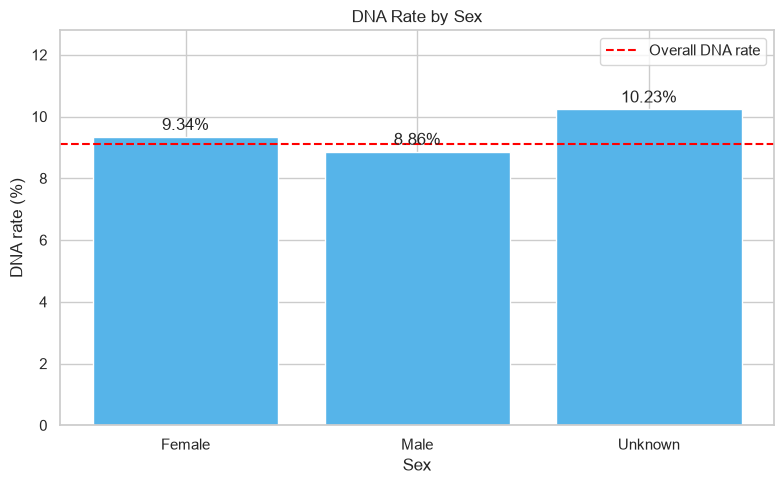


3. ETHNICITY DISTRIBUTION AND DNA RATES


,ethnicity_eda,appointments,attended_count,dna_count,dna_rate_percent
0,White,26488,24146,2342,8.84
1,Asian or Asian British,4474,4046,428,9.57
2,Black or Black British,1931,1708,223,11.55
3,Not Stated,1304,1182,122,9.36
4,Mixed,1184,1087,97,8.19
5,Other ethnic group,883,789,94,10.65



4. DNA RATE BY ETHNICITY


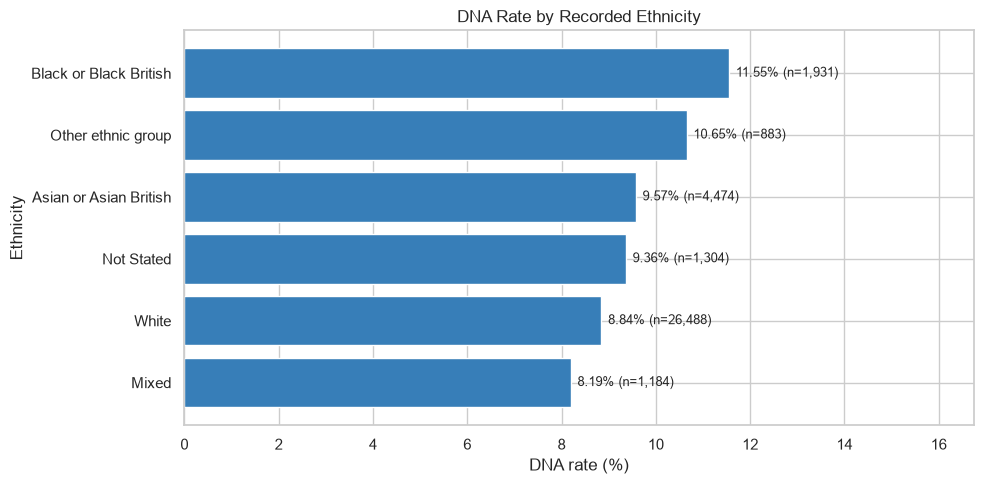


5. IMD DATA QUALITY
Missing IMD values: 1,265
Missing IMD percentage: 3.49%

6. DNA RATE BY IMD DECILE


,imd_group,appointments,attended_count,dna_count,dna_rate_percent
0,1,4935,4328,607,12.30
1,2,4462,4012,450,10.09
2,3,4070,3617,453,11.13
3,4,3760,3391,369,9.81
4,5,3586,3282,304,8.48
5,6,3410,3126,284,8.33
6,7,3291,3030,261,7.93
7,8,2739,2559,180,6.57
8,9,2332,2167,165,7.08
9,10,2414,2286,128,5.30



7. DNA RATE BY IMD DECILE


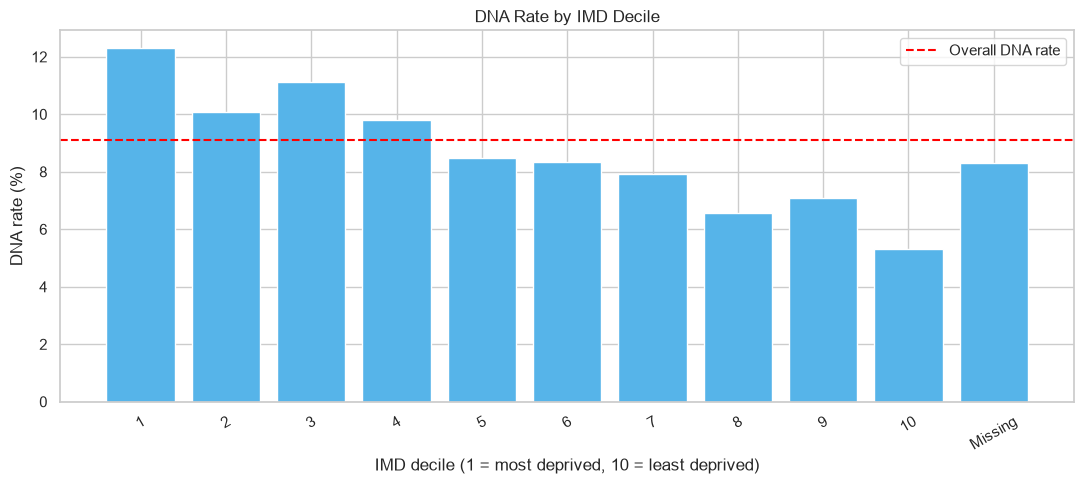


8. DNA RATE BY BROADER DEPRIVATION GROUP


,imd_band,appointments,attended_count,dna_count,dna_rate_percent
0,1–2 (most deprived),9397,8340,1057,11.25
1,3–4,7830,7008,822,10.50
2,5–6,6996,6408,588,8.40
3,7–8,6030,5589,441,7.31
4,9–10 (least deprived),4746,4453,293,6.17
5,Missing IMD,1265,1160,105,8.30



9. DNA RATE BY DEPRIVATION BAND


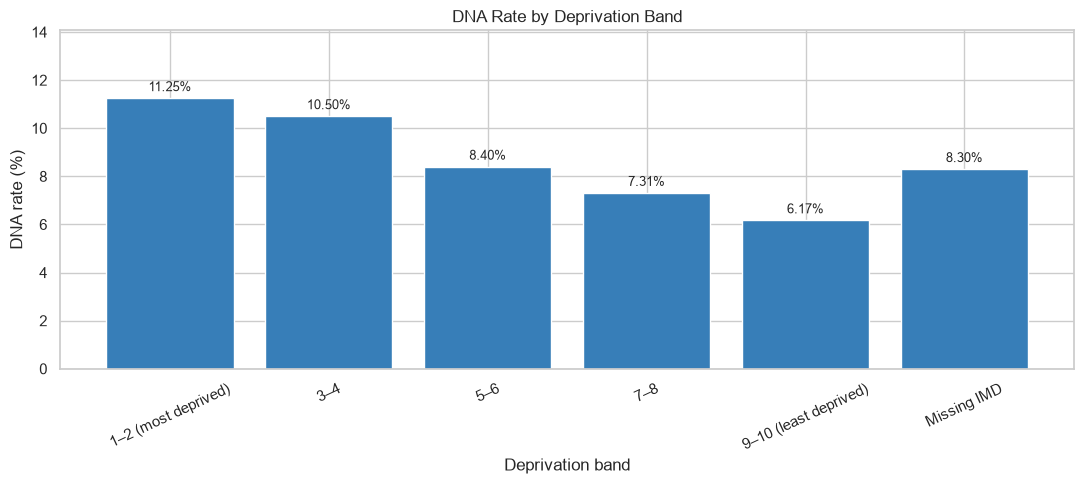


10. DEMOGRAPHIC DATA COMPLETENESS


,feature,missing_or_unknown,percentage
0,sex,88,0.24
1,ethnic_group,0,0.00
2,imd_decile,1265,3.49



11. SAVE DEMOGRAPHIC EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_sex.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_ethnicity.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_imd_decile.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_imd_band.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\demographic_missingness.csv

12. KEY DEMOGRAPHIC EDA FINDINGS
Overall DNA rate: 9.12%

Sex:
Female: 9.34% DNA (19,157 appointments)
Male: 8.86% DNA (17,019 appointments)
Unknown: 10.23% DNA (88 appointments)

Deprivation bands:
1–2 (most deprived): 11.25% DNA (9,397 appointments)
3–4: 10.50% DNA (7,830 appointments)
5–6: 8.40% DNA (6,996 appointments)
7–8: 7.31% DNA (6,030 appointments)
9–10 (least deprived): 6.17% DNA (4,746 appointments)
Missing IMD: 8.30% 

In [61]:

# SEX, ETHNICITY AND DEPRIVATION


# Objectives:
# 1. Examine sex distribution and DNA rates.
# 2. Examine ethnicity distribution and DNA rates.
# 3. Explore deprivation using IMD deciles.
# 4. Investigate missing demographic information.
# 5. Identify descriptive differences relevant to fairness.
# 6. Save tables and charts for reporting.

print("CELL 5: SEX, ETHNICITY AND DEPRIVATION")

# Use a separate dataframe for demographic EDA.
# No changes are made to the exported modelling dataset.

df_demo = df_binary.copy()

assert len(df_demo) == 36264

required_columns = [
    "sex",
    "ethnic_group",
    "imd_decile",
    "dna_target"
]

assert all(
    column in df_demo.columns
    for column in required_columns
), "One or more demographic columns are missing."

# 1. Create a reusable descriptive summary function.
# Each group is reported with appointment count,
# attended count, DNA count and DNA percentage.

def demographic_summary(data, column, order=None):

    summary = (
        data.groupby(column, dropna=False)["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    summary["attended_count"] = (
        summary["appointments"] - summary["dna_count"]
    )

    summary["dna_rate_percent"] = (
        summary["dna_rate"] * 100
    ).round(2)

    if order is not None:
        summary[column] = pd.Categorical(
            summary[column],
            categories=order,
            ordered=True
        )

        summary = summary.sort_values(column)

    return summary[
        [
            column,
            "appointments",
            "attended_count",
            "dna_count",
            "dna_rate_percent"
        ]
    ].reset_index(drop=True)


# 2. Examine sex distribution.
# Sex categories were standardised during cleaning.
# Unknown is retained rather than discarded.

print("\n1. SEX DISTRIBUTION AND DNA RATES")

df_demo["sex_eda"] = (
    df_demo["sex"]
    .fillna("Unknown")
    .astype(str)
    .str.strip()
)

sex_order = ["Female", "Male", "Unknown"]

sex_summary = demographic_summary(
    df_demo,
    "sex_eda",
    sex_order
)

display(sex_summary)

assert sex_summary["appointments"].sum() == len(df_demo)

# 3. Visualise DNA rates by sex.

print("\n2. DNA RATE BY SEX")

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    sex_summary["sex_eda"].astype(str),
    sex_summary["dna_rate_percent"],
    color="#56b4e9"
)

for bar, rate in zip(
    bars,
    sex_summary["dna_rate_percent"]
):
    ax.annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.axhline(
    df_demo["dna_target"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall DNA rate"
)

ax.set_title("DNA Rate by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("DNA rate (%)")
ax.set_ylim(
    0,
    max(
        sex_summary["dna_rate_percent"].max(),
        df_demo["dna_target"].mean() * 100
    ) * 1.25
)
ax.legend()

plt.tight_layout()

sex_chart_path = EDA_REPORT_DIR / "dna_rate_by_sex.png"

plt.savefig(sex_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 4. Examine ethnicity.
# Preserve the recorded categories.
# Missing or blank entries are labelled separately.

print("\n3. ETHNICITY DISTRIBUTION AND DNA RATES")

df_demo["ethnicity_eda"] = (
    df_demo["ethnic_group"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
)

df_demo.loc[
    df_demo["ethnicity_eda"] == "",
    "ethnicity_eda"
] = "Missing"

ethnicity_summary = demographic_summary(
    df_demo,
    "ethnicity_eda"
)

ethnicity_summary = ethnicity_summary.sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

display(ethnicity_summary)

assert ethnicity_summary["appointments"].sum() == len(df_demo)

# 5. Visualise ethnicity DNA rates.
# Display group sizes to support careful interpretation.
# Small groups may have unstable observed rates.

print("\n4. DNA RATE BY ETHNICITY")

ethnicity_plot = ethnicity_summary.sort_values(
    "dna_rate_percent"
)

fig, ax = plt.subplots(
    figsize=(10, max(5, len(ethnicity_plot) * 0.55))
)

bars = ax.barh(
    ethnicity_plot["ethnicity_eda"],
    ethnicity_plot["dna_rate_percent"],
    color="#377eb8"
)

for bar, rate, count in zip(
    bars,
    ethnicity_plot["dna_rate_percent"],
    ethnicity_plot["appointments"]
):
    ax.annotate(
        f"{rate:.2f}% (n={count:,})",
        (
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    max(
        ethnicity_plot["dna_rate_percent"].max() * 1.45,
        1
    )
)

ax.set_title("DNA Rate by Recorded Ethnicity")
ax.set_xlabel("DNA rate (%)")
ax.set_ylabel("Ethnicity")

plt.tight_layout()

ethnicity_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_ethnicity.png"
)

plt.savefig(
    ethnicity_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 6. Examine deprivation.
# IMD decile 1 represents the most deprived areas.
# IMD decile 10 represents the least deprived areas.
# IMD is area-level deprivation, not individual income.

print("\n5. IMD DATA QUALITY")

df_demo["imd_numeric"] = pd.to_numeric(
    df_demo["imd_decile"],
    errors="coerce"
)

valid_imd = (
    df_demo["imd_numeric"].isna()
    | df_demo["imd_numeric"].isin(range(1, 11))
)

assert valid_imd.all(), (
    "Unexpected IMD decile values detected."
)

missing_imd = int(
    df_demo["imd_numeric"].isna().sum()
)

print(f"Missing IMD values: {missing_imd:,}")
print(
    f"Missing IMD percentage: "
    f"{missing_imd / len(df_demo) * 100:.2f}%"
)

# 7. Calculate DNA rates by individual IMD decile.
# Keep missing IMD as a separate descriptive category.

print("\n6. DNA RATE BY IMD DECILE")

df_demo["imd_group"] = (
    df_demo["imd_numeric"]
    .apply(
        lambda value: (
            str(int(value))
            if pd.notna(value)
            else "Missing"
        )
    )
)

imd_order = [str(i) for i in range(1, 11)] + ["Missing"]

imd_summary = demographic_summary(
    df_demo,
    "imd_group",
    imd_order
)

display(imd_summary)

assert imd_summary["appointments"].sum() == len(df_demo)

# 8. Visualise DNA rates by IMD decile.

print("\n7. DNA RATE BY IMD DECILE")

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    imd_summary["imd_group"].astype(str),
    imd_summary["dna_rate_percent"],
    color="#56b4e9"
)

ax.axhline(
    df_demo["dna_target"].mean() * 100,
    color="red",
    linestyle="--",
    label="Overall DNA rate"
)

ax.set_title("DNA Rate by IMD Decile")
ax.set_xlabel("IMD decile (1 = most deprived, 10 = least deprived)")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=30)
ax.legend()

plt.tight_layout()

imd_chart_path = EDA_REPORT_DIR / "dna_rate_by_imd_decile.png"

plt.savefig(imd_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 9. Create broader deprivation groups.
# This makes differences easier to interpret.
# Missing IMD remains a separate group.

print("\n8. DNA RATE BY BROADER DEPRIVATION GROUP")

def assign_imd_band(value):

    if pd.isna(value):
        return "Missing IMD"

    if value <= 2:
        return "1–2 (most deprived)"

    if value <= 4:
        return "3–4"

    if value <= 6:
        return "5–6"

    if value <= 8:
        return "7–8"

    return "9–10 (least deprived)"


df_demo["imd_band"] = (
    df_demo["imd_numeric"].apply(assign_imd_band)
)

imd_band_order = [
    "1–2 (most deprived)",
    "3–4",
    "5–6",
    "7–8",
    "9–10 (least deprived)",
    "Missing IMD"
]

imd_band_summary = demographic_summary(
    df_demo,
    "imd_band",
    imd_band_order
)

display(imd_band_summary)

assert imd_band_summary["appointments"].sum() == len(df_demo)

# 10. Visualise broader deprivation groups.

print("\n9. DNA RATE BY DEPRIVATION BAND")

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.bar(
    imd_band_summary["imd_band"].astype(str),
    imd_band_summary["dna_rate_percent"],
    color="#377eb8"
)

for bar, rate in zip(
    bars,
    imd_band_summary["dna_rate_percent"]
):
    ax.annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        fontsize=9
    )

ax.set_title("DNA Rate by Deprivation Band")
ax.set_xlabel("Deprivation band")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=25)

ax.set_ylim(
    0,
    max(imd_band_summary["dna_rate_percent"].max(), 1) * 1.25
)

plt.tight_layout()

imd_band_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_imd_band.png"
)

plt.savefig(
    imd_band_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 11. Review demographic missingness.
# Unknown sex is reported separately from missing values.


print("\n10. DEMOGRAPHIC DATA COMPLETENESS")

demographic_missingness = pd.DataFrame([
    {
        "feature": "sex",
        "missing_or_unknown": int(
            (
                df_demo["sex_eda"].str.lower() == "unknown"
            ).sum()
        )
    },
    {
        "feature": "ethnic_group",
        "missing_or_unknown": int(
            (
                df_demo["ethnicity_eda"].str.lower() == "missing"
            ).sum()
        )
    },
    {
        "feature": "imd_decile",
        "missing_or_unknown": missing_imd
    }
])

demographic_missingness["percentage"] = (
    demographic_missingness["missing_or_unknown"]
    / len(df_demo)
    * 100
).round(2)

display(demographic_missingness)

# 12. Save all demographic EDA tables.

print("\n11. SAVE DEMOGRAPHIC EDA RESULTS")

demographic_tables = {
    "dna_rate_by_sex.csv": sex_summary,
    "dna_rate_by_ethnicity.csv": ethnicity_summary,
    "dna_rate_by_imd_decile.csv": imd_summary,
    "dna_rate_by_imd_band.csv": imd_band_summary,
    "demographic_missingness.csv": demographic_missingness
}

for filename, table in demographic_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")

# 13. Summarise the descriptive findings.
# We do not conclude that demographic characteristics
# directly cause missed appointments.

print("\n12. KEY DEMOGRAPHIC EDA FINDINGS")

print(
    f"Overall DNA rate: "
    f"{df_demo['dna_target'].mean() * 100:.2f}%"
)

print("\nSex:")
for _, row in sex_summary.iterrows():
    print(
        f"{row['sex_eda']}: "
        f"{row['dna_rate_percent']:.2f}% DNA "
        f"({int(row['appointments']):,} appointments)"
    )

print("\nDeprivation bands:")
for _, row in imd_band_summary.iterrows():
    print(
        f"{row['imd_band']}: "
        f"{row['dna_rate_percent']:.2f}% DNA "
        f"({int(row['appointments']):,} appointments)"
    )

print(
    "\nDifferences across demographic groups are "
    "descriptive associations, not causal findings."
)

print(
    "Small groups and missing demographic information "
    "must be considered when interpreting differences."
)

print(
    "A later fairness assessment will evaluate "
    "model performance across demographic groups, "
    "not just their observed DNA rates."
)

print("\nCOMPLETED SUCCESSFULLY")
print("Ready for updated: Clinical specialties.")


CLINICAL SPECIALTIES AND DNA PATTERNS

1. SPECIALTY DATA QUALITY


,specialty,appointments,percentage
0,Trauma and Orthopaedics,8020,22.12
1,Ophthalmology,4254,11.73
2,Physiotherapy,4040,11.14
3,Dermatology,3918,10.80
4,Cardiology,3685,10.16
5,Gastroenterology,3314,9.14
6,Paediatrics,3067,8.46
7,Diabetes and Endocrinology,3004,8.28
8,Respiratory Medicine,2962,8.17


Number of recorded specialty categories: 9
Missing specialty records: 0

2. DNA RATES BY CLINICAL SPECIALTY


,specialty_eda,appointments,attended_count,dna_count,dna_rate_percent,appointment_share_percent
0,Trauma and Orthopaedics,8020,7333,687,8.57,22.12
1,Ophthalmology,4254,3922,332,7.80,11.73
2,Physiotherapy,4040,3594,446,11.04,11.14
3,Dermatology,3918,3560,358,9.14,10.80
4,Cardiology,3685,3421,264,7.16,10.16
5,Gastroenterology,3314,3019,295,8.90,9.14
6,Paediatrics,3067,2753,314,10.24,8.46
7,Diabetes and Endocrinology,3004,2680,324,10.79,8.28
8,Respiratory Medicine,2962,2676,286,9.66,8.17



3. APPOINTMENT VOLUME BY SPECIALTY


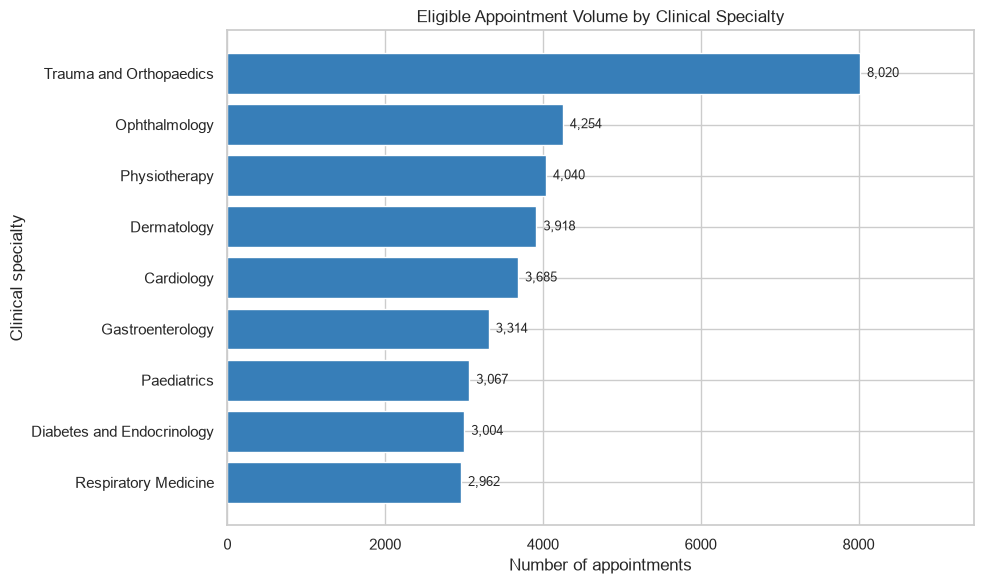

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\appointment_volume_by_specialty.png

4. DNA RATE BY CLINICAL SPECIALTY


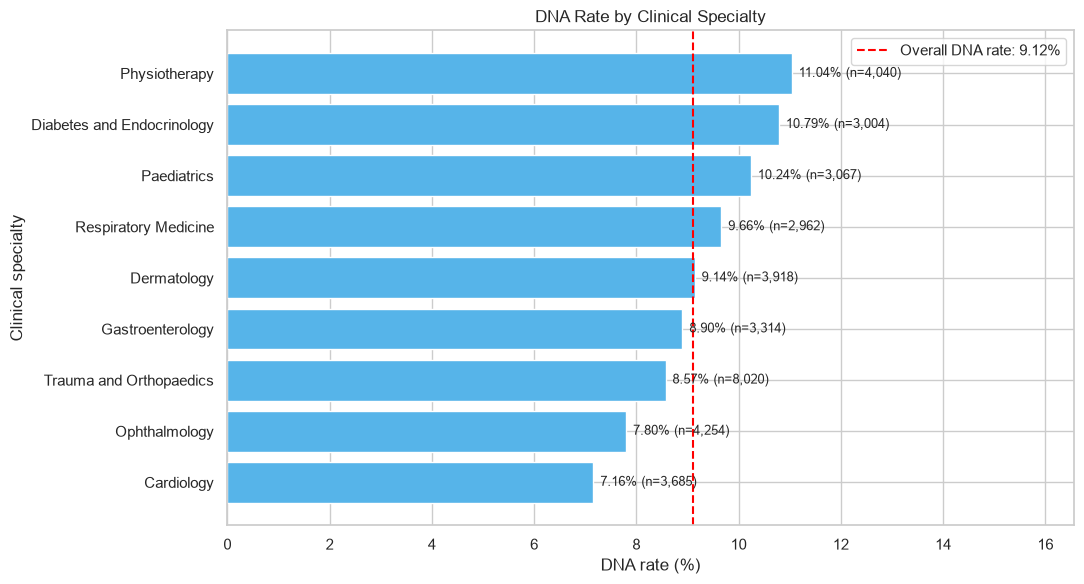

Chart saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_specialty.png

5. BOOKING LEAD TIME BY SPECIALTY


,specialty_eda,appointments,mean_lead_days,median_lead_days,minimum_lead_days,maximum_lead_days
6,Physiotherapy,4040,47.14,37.01,0.07,294.92
8,Trauma and Orthopaedics,8020,46.79,37.23,0.03,294.89
2,Diabetes and Endocrinology,3004,46.39,37.13,0.02,299.79
3,Gastroenterology,3314,46.36,35.80,0.03,300.13
5,Paediatrics,3067,45.94,36.04,0.03,300.27
7,Respiratory Medicine,2962,45.84,36.06,0.03,300.03
1,Dermatology,3918,45.29,35.93,0.04,280.97
0,Cardiology,3685,45.24,35.80,0.04,300.20
4,Ophthalmology,4254,44.34,35.09,0.03,265.88



6. SPECIALTY AND BOOKING NOTICE


,specialty_eda,booking_notice_group,appointments,dna_count,dna_rate_percent
0,Cardiology,Long notice (7+ days),3419,252,7.37
1,Cardiology,Short notice (<7 days),266,12,4.51
2,Dermatology,Long notice (7+ days),3640,334,9.18
3,Dermatology,Short notice (<7 days),278,24,8.63
4,Diabetes and Endocrinology,Long notice (7+ days),2789,313,11.22
5,Diabetes and Endocrinology,Short notice (<7 days),215,11,5.12
6,Gastroenterology,Long notice (7+ days),3041,270,8.88
7,Gastroenterology,Short notice (<7 days),273,25,9.16
8,Ophthalmology,Long notice (7+ days),3920,314,8.01
9,Ophthalmology,Short notice (<7 days),334,18,5.39



7. SPECIALTY SAMPLE-SIZE REVIEW


,specialty_eda,appointments,dna_count,dna_rate_percent,small_sample_flag
0,Trauma and Orthopaedics,8020,687,8.57,False
1,Ophthalmology,4254,332,7.80,False
2,Physiotherapy,4040,446,11.04,False
3,Dermatology,3918,358,9.14,False
4,Cardiology,3685,264,7.16,False
5,Gastroenterology,3314,295,8.90,False
6,Paediatrics,3067,314,10.24,False
7,Diabetes and Endocrinology,3004,324,10.79,False
8,Respiratory Medicine,2962,286,9.66,False



8. SAVE SPECIALTY EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\specialty_appointment_distribution.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_specialty.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\booking_lead_time_by_specialty.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_specialty_and_booking_notice.csv

9. KEY CLINICAL SPECIALTY FINDINGS
Largest specialty: Trauma and Orthopaedics (8,020 appointments).
Highest observed DNA rate: Physiotherapy (11.04%, n=4,040).
Lowest observed DNA rate: Cardiology (7.16%, n=3,685).

Differences between specialties may reflect booking lead time, patient characteristics, appointment type and other factors.
These are unadjusted descriptive associations, not evidence that a specialty causes DNA.
Specialty may be considered for modelling if it is reliably available 

In [62]:

# CLINICAL SPECIALTIES AND DNA PATTERNS


# Objectives:
# 1. Examine the distribution of clinical specialties.
# 2. Calculate Attended and DNA counts by specialty.
# 3. Compare DNA rates across specialties.
# 4. Visualise specialty appointment volumes and DNA rates.
# 5. Explore booking lead times by specialty.
# 6. Identify groups requiring careful interpretation.
# 7. Save descriptive EDA tables and charts.

print("CLINICAL SPECIALTIES AND DNA PATTERNS")

# 1. Create a separate dataframe for specialty analysis.
# No records are removed or modified in df_binary.

df_specialty = df_binary.copy()

assert len(df_specialty) == 36264

required_columns = [
    "specialty",
    "attendance_status",
    "dna_target",
    "booking_lead_days"
]

assert all(
    column in df_specialty.columns
    for column in required_columns
), "One or more required columns are missing."

# 2. Review specialty data quality.
# Spelling errors were corrected during data cleaning.
# Missing and blank values are shown separately.

print("\n1. SPECIALTY DATA QUALITY")

df_specialty["specialty_eda"] = (
    df_specialty["specialty"]
    .fillna("Missing")
    .astype(str)
    .str.strip()
)

df_specialty.loc[
    df_specialty["specialty_eda"] == "",
    "specialty_eda"
] = "Missing"

specialty_counts = (
    df_specialty["specialty_eda"]
    .value_counts(dropna=False)
    .rename_axis("specialty")
    .reset_index(name="appointments")
)

specialty_counts["percentage"] = (
    specialty_counts["appointments"]
    / len(df_specialty)
    * 100
).round(2)

display(specialty_counts)

print(
    f"Number of recorded specialty categories: "
    f"{df_specialty['specialty_eda'].nunique()}"
)

print(
    f"Missing specialty records: "
    f"{(df_specialty['specialty_eda'] == 'Missing').sum():,}"
)

assert specialty_counts["appointments"].sum() == len(
    df_specialty
)

# 3. Calculate attendance outcomes by specialty.
# DNA rate is calculated within each specialty,
# rather than using the entire dataset as denominator.

print("\n2. DNA RATES BY CLINICAL SPECIALTY")

specialty_summary = (
    df_specialty
    .groupby("specialty_eda")["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reset_index()
)

specialty_summary["attended_count"] = (
    specialty_summary["appointments"]
    - specialty_summary["dna_count"]
)

specialty_summary["dna_rate_percent"] = (
    specialty_summary["dna_rate"] * 100
).round(2)

specialty_summary["appointment_share_percent"] = (
    specialty_summary["appointments"]
    / len(df_specialty)
    * 100
).round(2)

specialty_summary = specialty_summary.sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

display(
    specialty_summary[
        [
            "specialty_eda",
            "appointments",
            "attended_count",
            "dna_count",
            "dna_rate_percent",
            "appointment_share_percent"
        ]
    ]
)

assert specialty_summary["appointments"].sum() == len(
    df_specialty
)

assert specialty_summary["dna_count"].sum() == 3306

# 4. Visualise appointment volumes by specialty.
# This shows which specialties contribute the most
# appointments to the eligible modelling cohort.

print("\n3. APPOINTMENT VOLUME BY SPECIALTY")

volume_plot = specialty_summary.sort_values(
    "appointments",
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    volume_plot["specialty_eda"],
    volume_plot["appointments"],
    color="#377eb8"
)

for bar, count in zip(
    bars,
    volume_plot["appointments"]
):
    ax.annotate(
        f"{count:,}",
        (
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    volume_plot["appointments"].max() * 1.18
)

ax.set_title("Eligible Appointment Volume by Clinical Specialty")
ax.set_xlabel("Number of appointments")
ax.set_ylabel("Clinical specialty")

plt.tight_layout()

specialty_volume_path = (
    EDA_REPORT_DIR / "appointment_volume_by_specialty.png"
)

plt.savefig(
    specialty_volume_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {specialty_volume_path}")

# 5. Visualise DNA rates by specialty.
# Sorting by DNA rate helps identify descriptive differences.
# Include group sizes because small samples can be unstable.

print("\n4. DNA RATE BY CLINICAL SPECIALTY")

rate_plot = specialty_summary.sort_values(
    "dna_rate_percent",
    ascending=True
)

overall_dna_rate = df_specialty["dna_target"].mean() * 100

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    rate_plot["specialty_eda"],
    rate_plot["dna_rate_percent"],
    color="#56b4e9"
)

ax.axvline(
    overall_dna_rate,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

for bar, rate, count in zip(
    bars,
    rate_plot["dna_rate_percent"],
    rate_plot["appointments"]
):
    ax.annotate(
        f"{rate:.2f}% (n={count:,})",
        (
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    max(
        rate_plot["dna_rate_percent"].max(),
        overall_dna_rate
    ) * 1.5
)

ax.set_title("DNA Rate by Clinical Specialty")
ax.set_xlabel("DNA rate (%)")
ax.set_ylabel("Clinical specialty")
ax.legend()

plt.tight_layout()

specialty_rate_path = (
    EDA_REPORT_DIR / "dna_rate_by_specialty.png"
)

plt.savefig(
    specialty_rate_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Chart saved: {specialty_rate_path}")

# 6. Examine booking lead times by specialty.
# This is useful because earlier EDA showed that
# appointments booked further ahead tend to have
# higher observed DNA rates.

print("\n5. BOOKING LEAD TIME BY SPECIALTY")

specialty_lead_summary = (
    df_specialty
    .groupby("specialty_eda")["booking_lead_days"]
    .agg(
        appointments="count",
        mean_lead_days="mean",
        median_lead_days="median",
        minimum_lead_days="min",
        maximum_lead_days="max"
    )
    .round(2)
    .reset_index()
    .sort_values(
        "mean_lead_days",
        ascending=False
    )
)

display(specialty_lead_summary)

# 7. Compare short-notice and long-notice DNA rates
# within each specialty.
# This is descriptive subgroup analysis.
# It does not adjust for all other patient differences.

print("\n6. SPECIALTY AND BOOKING NOTICE")

df_specialty["booking_notice_group"] = np.where(
    df_specialty["booking_lead_days"] < 7,
    "Short notice (<7 days)",
    "Long notice (7+ days)"
)

specialty_notice_summary = (
    df_specialty
    .groupby(
        ["specialty_eda", "booking_notice_group"]
    )["dna_target"]
    .agg(
        appointments="count",
        dna_count="sum",
        dna_rate="mean"
    )
    .reset_index()
)

specialty_notice_summary["dna_rate_percent"] = (
    specialty_notice_summary["dna_rate"] * 100
).round(2)

display(
    specialty_notice_summary[
        [
            "specialty_eda",
            "booking_notice_group",
            "appointments",
            "dna_count",
            "dna_rate_percent"
        ]
    ]
)

assert specialty_notice_summary["appointments"].sum() == len(
    df_specialty
)

# 8. Review specialty sample sizes.
# The 100-appointment threshold is a descriptive
# reporting flag, not a statistical significance test.

print("\n7. SPECIALTY SAMPLE-SIZE REVIEW")

specialty_summary["small_sample_flag"] = (
    specialty_summary["appointments"] < 100
)

display(
    specialty_summary[
        [
            "specialty_eda",
            "appointments",
            "dna_count",
            "dna_rate_percent",
            "small_sample_flag"
        ]
    ]
)

# 9. Save descriptive EDA tables.

print("\n8. SAVE SPECIALTY EDA RESULTS")

specialty_tables = {
    "specialty_appointment_distribution.csv": specialty_counts,
    "dna_rate_by_specialty.csv": specialty_summary,
    "booking_lead_time_by_specialty.csv": specialty_lead_summary,
    "dna_rate_by_specialty_and_booking_notice.csv": specialty_notice_summary
}

for filename, table in specialty_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")

# 10. Summarise the key findings.
# Conclusions are calculated from the actual data.

print("\n9. KEY CLINICAL SPECIALTY FINDINGS")

highest_specialty = specialty_summary.loc[
    specialty_summary["dna_rate_percent"].idxmax()
]

lowest_specialty = specialty_summary.loc[
    specialty_summary["dna_rate_percent"].idxmin()
]

largest_specialty = specialty_summary.loc[
    specialty_summary["appointments"].idxmax()
]

print(
    f"Largest specialty: "
    f"{largest_specialty['specialty_eda']} "
    f"({int(largest_specialty['appointments']):,} appointments)."
)

print(
    f"Highest observed DNA rate: "
    f"{highest_specialty['specialty_eda']} "
    f"({highest_specialty['dna_rate_percent']:.2f}%, "
    f"n={int(highest_specialty['appointments']):,})."
)

print(
    f"Lowest observed DNA rate: "
    f"{lowest_specialty['specialty_eda']} "
    f"({lowest_specialty['dna_rate_percent']:.2f}%, "
    f"n={int(lowest_specialty['appointments']):,})."
)

print(
    "\nDifferences between specialties may reflect "
    "booking lead time, patient characteristics, "
    "appointment type and other factors."
)

print(
    "These are unadjusted descriptive associations, "
    "not evidence that a specialty causes DNA."
)

print(
    "Specialty may be considered for modelling if "
    "it is reliably available at prediction time."
)

print("COMPLETED SUCCESSFULLY")
print("Ready: Appointment types and consultation modes.")


 APPOINTMENT TYPES AND CONSULTATION MODES

1. APPOINTMENT TYPES


,appointment_type,appointments,dna_count,attended_count,dna_rate_percent,appointment_share_percent
0,Follow-up,22539,1877,20662,8.33,62.15
1,New,13725,1429,12296,10.41,37.85



2. DNA RATE BY APPOINTMENT TYPE


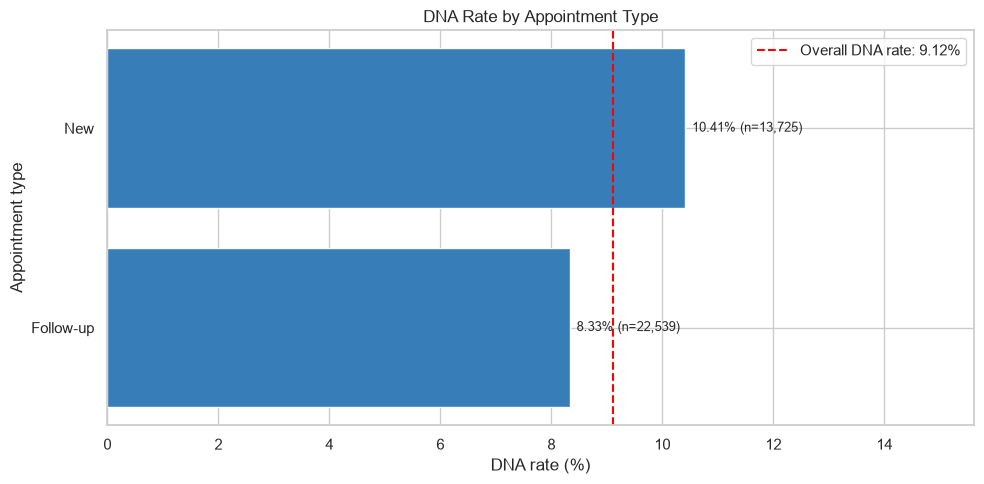


3. CONSULTATION MODES


,consultation_mode,appointments,dna_count,attended_count,dna_rate_percent,appointment_share_percent
0,Face-to-face,29060,2782,26278,9.57,80.13
1,Telephone,5708,401,5307,7.03,15.74
2,Video,1496,123,1373,8.22,4.13



4. DNA RATE BY CONSULTATION MODE


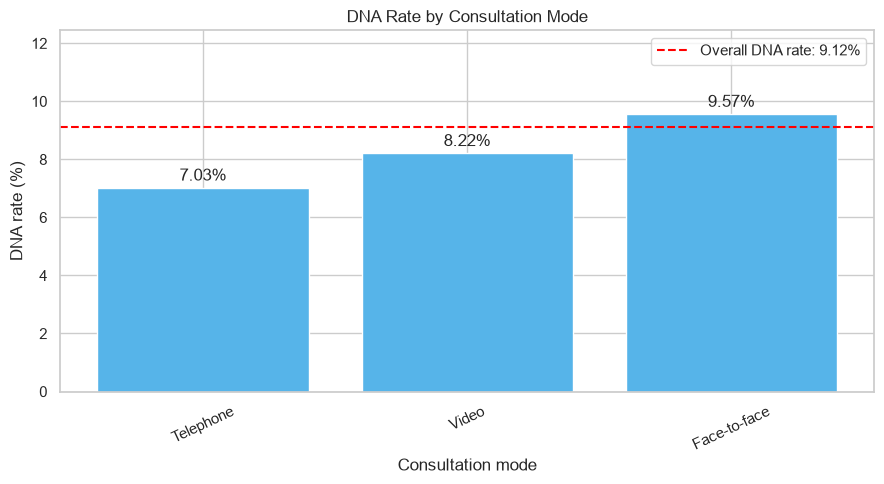


5. APPOINTMENT TYPE AND CONSULTATION MODE


,appointment_type,consultation_mode,appointments,dna_count,attended_count,dna_rate_percent
0,Follow-up,Face-to-face,18078,1592,16486,8.81
1,Follow-up,Telephone,3561,220,3341,6.18
2,Follow-up,Video,900,65,835,7.22
3,New,Face-to-face,10982,1190,9792,10.84
4,New,Telephone,2147,181,1966,8.43
5,New,Video,596,58,538,9.73



6. DNA RATE HEATMAP


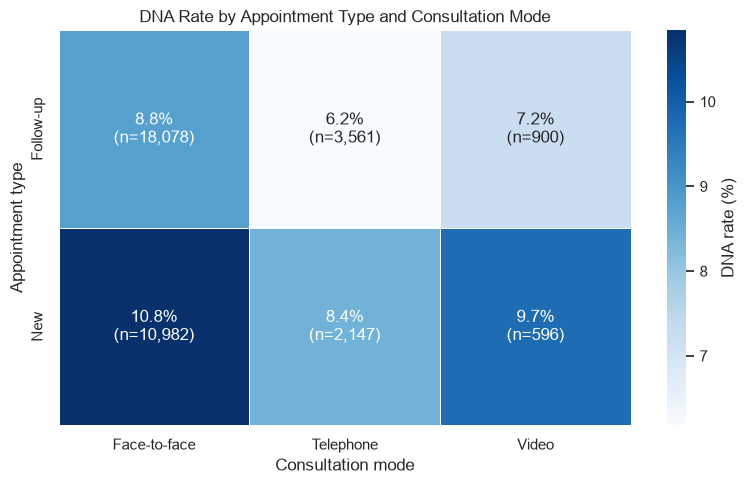


7. CONSULTATION MODE AND BOOKING NOTICE


,consultation_mode,booking_notice_group,appointments,dna_count,attended_count,dna_rate_percent
0,Face-to-face,Long notice (7+ days),26907,2628,24279,9.77
1,Face-to-face,Short notice (<7 days),2153,154,1999,7.15
2,Telephone,Long notice (7+ days),5261,368,4893,6.99
3,Telephone,Short notice (<7 days),447,33,414,7.38
4,Video,Long notice (7+ days),1399,115,1284,8.22
5,Video,Short notice (<7 days),97,8,89,8.25



8. BOOKING LEAD TIME BY CONSULTATION MODE


,consultation_mode,appointments,mean_lead_days,median_lead_days,minimum_lead_days,maximum_lead_days
0,Face-to-face,29060,46.06,36.10,0.03,300.27
1,Telephone,5708,45.66,36.93,0.03,299.76
2,Video,1496,46.08,36.83,0.02,280.97



9. SMALL SUBGROUP REVIEW


,appointment_type,consultation_mode,appointments,dna_count,dna_rate_percent,small_sample_flag
0,Follow-up,Face-to-face,18078,1592,8.81,False
1,Follow-up,Telephone,3561,220,6.18,False
2,Follow-up,Video,900,65,7.22,False
3,New,Face-to-face,10982,1190,10.84,False
4,New,Telephone,2147,181,8.43,False
5,New,Video,596,58,9.73,False



10. SAVE APPOINTMENT SERVICE EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_appointment_type.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_consultation_mode.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_type_and_mode.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_mode_and_booking_notice.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\booking_lead_time_by_consultation_mode.csv

11. KEY APPOINTMENT SERVICE FINDINGS
Highest appointment-type DNA rate: New (10.41%, n=13,725).
Lowest appointment-type DNA rate: Follow-up (8.33%, n=22,539).
Highest consultation-mode DNA rate: Face-to-face (9.57%, n=29,060).
Lowest consultation-mode DNA rate: Telephone (7.03%, n=5,708).

Appointment type and consultation mode are potential predictive features if relia

In [63]:

# APPOINTMENT TYPES AND CONSULTATION MODES


# Objectives:
# 1. Examine appointment type distributions.
# 2. Compare DNA rates by appointment type.
# 3. Examine consultation modes and DNA rates.
# 4. Compare appointment types and consultation modes.
# 5. Investigate booking notice within consultation modes.
# 6. Save descriptive tables and charts.

print(" APPOINTMENT TYPES AND CONSULTATION MODES")

# 1. Create a separate dataframe for analysis.
# This preserves the original modelling dataset.

df_service = df_binary.copy()

required_columns = [
    "appointment_type",
    "consultation_mode",
    "booking_lead_days",
    "dna_target"
]

assert all(
    column in df_service.columns
    for column in required_columns
), "Required columns are missing."

assert len(df_service) == 36264

# 2. Standardise missing or blank labels for EDA.


for column in ["appointment_type", "consultation_mode"]:

    df_service[column] = (
        df_service[column]
        .fillna("Missing")
        .astype(str)
        .str.strip()
    )

    df_service.loc[
        df_service[column] == "",
        column
    ] = "Missing"

# 3. Create a descriptive summary function.

def service_dna_summary(data, group_columns):

    summary = (
        data.groupby(group_columns, dropna=False)["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    summary["attended_count"] = (
        summary["appointments"] - summary["dna_count"]
    )

    summary["dna_rate_percent"] = (
        summary["dna_rate"] * 100
    ).round(2)

    return summary.drop(columns="dna_rate")

# 4. Examine appointment types.

print("\n1. APPOINTMENT TYPES")

type_summary = service_dna_summary(
    df_service,
    ["appointment_type"]
).sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

type_summary["appointment_share_percent"] = (
    type_summary["appointments"]
    / len(df_service) * 100
).round(2)

display(type_summary)

assert type_summary["appointments"].sum() == 36264
assert type_summary["dna_count"].sum() == 3306

# 5. Visualise DNA rates by appointment type.

print("\n2. DNA RATE BY APPOINTMENT TYPE")

type_plot = type_summary.sort_values("dna_rate_percent")

fig, ax = plt.subplots(
    figsize=(10, max(5, len(type_plot) * 0.65))
)

bars = ax.barh(
    type_plot["appointment_type"],
    type_plot["dna_rate_percent"],
    color="#377eb8"
)

overall_rate = df_service["dna_target"].mean() * 100

ax.axvline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall DNA rate: {overall_rate:.2f}%"
)

for bar, rate, count in zip(
    bars,
    type_plot["dna_rate_percent"],
    type_plot["appointments"]
):
    ax.annotate(
        f"{rate:.2f}% (n={count:,})",
        (
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    max(type_plot["dna_rate_percent"].max(), overall_rate) * 1.5
)

ax.set_title("DNA Rate by Appointment Type")
ax.set_xlabel("DNA rate (%)")
ax.set_ylabel("Appointment type")
ax.legend()

plt.tight_layout()

type_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_appointment_type.png"
)

plt.savefig(type_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 6. Examine consultation modes.

print("\n3. CONSULTATION MODES")

mode_summary = service_dna_summary(
    df_service,
    ["consultation_mode"]
).sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

mode_summary["appointment_share_percent"] = (
    mode_summary["appointments"]
    / len(df_service) * 100
).round(2)

display(mode_summary)

assert mode_summary["appointments"].sum() == 36264
assert mode_summary["dna_count"].sum() == 3306

# 7. Visualise DNA rates by consultation mode.

print("\n4. DNA RATE BY CONSULTATION MODE")

mode_plot = mode_summary.sort_values("dna_rate_percent")

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    mode_plot["consultation_mode"],
    mode_plot["dna_rate_percent"],
    color="#56b4e9"
)

for bar, rate in zip(
    bars,
    mode_plot["dna_rate_percent"]
):
    ax.annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.axhline(
    overall_rate,
    color="red",
    linestyle="--",
    label=f"Overall DNA rate: {overall_rate:.2f}%"
)

ax.set_title("DNA Rate by Consultation Mode")
ax.set_xlabel("Consultation mode")
ax.set_ylabel("DNA rate (%)")

ax.set_ylim(
    0,
    max(mode_plot["dna_rate_percent"].max(), overall_rate) * 1.3
)

ax.tick_params(axis="x", rotation=25)
ax.legend()

plt.tight_layout()

mode_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_consultation_mode.png"
)

plt.savefig(mode_chart_path, dpi=300, bbox_inches="tight")
plt.show()

# 8. Compare appointment type and consultation mode.
# This helps identify whether particular combinations
# have different observed DNA rates.

print("\n5. APPOINTMENT TYPE AND CONSULTATION MODE")

type_mode_summary = service_dna_summary(
    df_service,
    ["appointment_type", "consultation_mode"]
).sort_values(
    ["appointment_type", "consultation_mode"]
).reset_index(drop=True)

display(type_mode_summary)

assert type_mode_summary["appointments"].sum() == 36264

# 9. Create a heatmap of DNA rates.
# Only observed combinations are displayed.
# Missing combinations remain blank.

print("\n6. DNA RATE HEATMAP")

heatmap_rates = type_mode_summary.pivot(
    index="appointment_type",
    columns="consultation_mode",
    values="dna_rate_percent"
)

heatmap_counts = type_mode_summary.pivot(
    index="appointment_type",
    columns="consultation_mode",
    values="appointments"
)

heatmap_labels = heatmap_rates.copy().astype(object)

for row in heatmap_rates.index:
    for column in heatmap_rates.columns:

        rate = heatmap_rates.loc[row, column]
        count = heatmap_counts.loc[row, column]

        if pd.notna(rate):
            heatmap_labels.loc[row, column] = (
                f"{rate:.1f}%\n(n={int(count):,})"
            )
        else:
            heatmap_labels.loc[row, column] = ""

fig, ax = plt.subplots(
    figsize=(
        max(8, len(heatmap_rates.columns) * 2),
        max(5, len(heatmap_rates.index) * 0.8)
    )
)

sns.heatmap(
    heatmap_rates,
    annot=heatmap_labels,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "DNA rate (%)"},
    ax=ax
)

ax.set_title("DNA Rate by Appointment Type and Consultation Mode")
ax.set_xlabel("Consultation mode")
ax.set_ylabel("Appointment type")

plt.tight_layout()

heatmap_path = (
    EDA_REPORT_DIR / "dna_rate_type_mode_heatmap.png"
)

plt.savefig(heatmap_path, dpi=300, bbox_inches="tight")
plt.show()

# 10. Compare booking notice within consultation modes.
# Earlier EDA found a relationship between booking
# lead time and observed DNA rates.

print("\n7. CONSULTATION MODE AND BOOKING NOTICE")

df_service["booking_notice_group"] = np.where(
    df_service["booking_lead_days"] < 7,
    "Short notice (<7 days)",
    "Long notice (7+ days)"
)

mode_notice_summary = service_dna_summary(
    df_service,
    ["consultation_mode", "booking_notice_group"]
).sort_values(
    ["consultation_mode", "booking_notice_group"]
).reset_index(drop=True)

display(mode_notice_summary)

assert mode_notice_summary["appointments"].sum() == 36264

# 11. Examine booking lead times by consultation mode.

print("\n8. BOOKING LEAD TIME BY CONSULTATION MODE")

mode_lead_summary = (
    df_service.groupby("consultation_mode")["booking_lead_days"]
    .agg(
        appointments="count",
        mean_lead_days="mean",
        median_lead_days="median",
        minimum_lead_days="min",
        maximum_lead_days="max"
    )
    .round(2)
    .reset_index()
)

display(mode_lead_summary)

# 12. Identify small subgroups.
# Small groups may produce unstable descriptive rates.
# The threshold is only a reporting flag.

print("\n9. SMALL SUBGROUP REVIEW")

type_mode_summary["small_sample_flag"] = (
    type_mode_summary["appointments"] < 100
)

display(
    type_mode_summary[
        [
            "appointment_type",
            "consultation_mode",
            "appointments",
            "dna_count",
            "dna_rate_percent",
            "small_sample_flag"
        ]
    ]
)

# 13. Save EDA results.

print("\n10. SAVE APPOINTMENT SERVICE EDA RESULTS")

service_tables = {
    "dna_rate_by_appointment_type.csv": type_summary,
    "dna_rate_by_consultation_mode.csv": mode_summary,
    "dna_rate_by_type_and_mode.csv": type_mode_summary,
    "dna_rate_by_mode_and_booking_notice.csv": mode_notice_summary,
    "booking_lead_time_by_consultation_mode.csv": mode_lead_summary
}

for filename, table in service_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(output_path, index=False)

    print(f"Saved: {output_path}")

# 14. Summarise descriptive findings.

print("\n11. KEY APPOINTMENT SERVICE FINDINGS")

highest_type = type_summary.loc[
    type_summary["dna_rate_percent"].idxmax()
]

lowest_type = type_summary.loc[
    type_summary["dna_rate_percent"].idxmin()
]

highest_mode = mode_summary.loc[
    mode_summary["dna_rate_percent"].idxmax()
]

lowest_mode = mode_summary.loc[
    mode_summary["dna_rate_percent"].idxmin()
]

print(
    f"Highest appointment-type DNA rate: "
    f"{highest_type['appointment_type']} "
    f"({highest_type['dna_rate_percent']:.2f}%, "
    f"n={int(highest_type['appointments']):,})."
)

print(
    f"Lowest appointment-type DNA rate: "
    f"{lowest_type['appointment_type']} "
    f"({lowest_type['dna_rate_percent']:.2f}%, "
    f"n={int(lowest_type['appointments']):,})."
)

print(
    f"Highest consultation-mode DNA rate: "
    f"{highest_mode['consultation_mode']} "
    f"({highest_mode['dna_rate_percent']:.2f}%, "
    f"n={int(highest_mode['appointments']):,})."
)

print(
    f"Lowest consultation-mode DNA rate: "
    f"{lowest_mode['consultation_mode']} "
    f"({lowest_mode['dna_rate_percent']:.2f}%, "
    f"n={int(lowest_mode['appointments']):,})."
)

print(
    "\nAppointment type and consultation mode are "
    "potential predictive features if reliably "
    "known at the prediction cutoff."
)

print(
    "Observed differences are descriptive, "
    "not evidence of causation."
)

print(
    "Subgroup sample sizes and other patient "
    "characteristics should be considered "
    "before drawing conclusions."
)

print("COMPLETED SUCCESSFULLY")


PREVIOUS DNAs AND RESCHEDULING HISTORY

1. HISTORICAL FEATURE DATA QUALITY

Feature: previous_dnas_12m
Missing values: 0
Minimum: 0
Maximum: 8


count    36264.000000
mean         0.267262
std          0.561662
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max          8.000000
Name: previous_dnas_12m, dtype: float64


Feature: rescheduled_count
Missing values: 0
Minimum: 0
Maximum: 3


count    36264.000000
mean         0.361185
std          0.682170
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          3.000000
Name: rescheduled_count, dtype: float64


2. PREVIOUS DNA HISTORY


,previous_dnas_12m,appointments,dna_count,attended_count,dna_rate_percent
0,0,28318,2083,26235,7.36
1,1,6524,841,5683,12.89
2,2,1167,272,895,23.31
3,3,203,78,125,38.42
4,4,42,25,17,59.52
5,5,7,5,2,71.43
6,6,1,0,1,0.00
7,8,2,2,0,100.00



3. PREVIOUS DNA HISTORY GROUPS


,previous_dna_group,appointments,dna_count,attended_count,dna_rate_percent
0,0 previous DNAs,28318,2083,26235,7.36
1,1 previous DNA,6524,841,5683,12.89
2,2 previous DNAs,1167,272,895,23.31
3,3+ previous DNAs,255,110,145,43.14



4. DNA RATE BY PREVIOUS DNA HISTORY


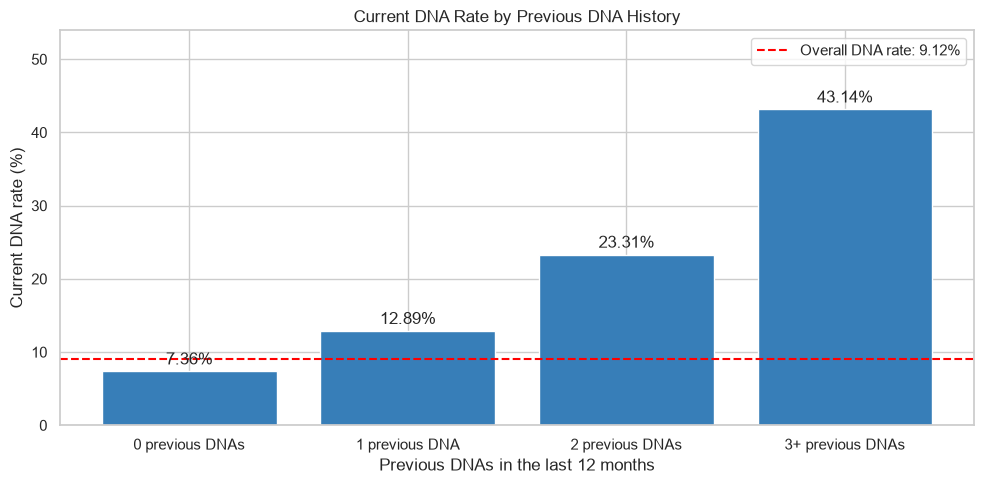


5. RESCHEDULING HISTORY


,rescheduled_count,appointments,dna_count,attended_count,dna_rate_percent
0,0,26732,2302,24430,8.61
1,1,6654,667,5987,10.02
2,2,2190,247,1943,11.28
3,3,688,90,598,13.08



6. RESCHEDULING GROUPS


,reschedule_group,appointments,dna_count,attended_count,dna_rate_percent
0,Never rescheduled,26732,2302,24430,8.61
1,Rescheduled once,6654,667,5987,10.02
2,Rescheduled twice,2190,247,1943,11.28
3,Rescheduled 3+ times,688,90,598,13.08



7. DNA RATE BY RESCHEDULING HISTORY


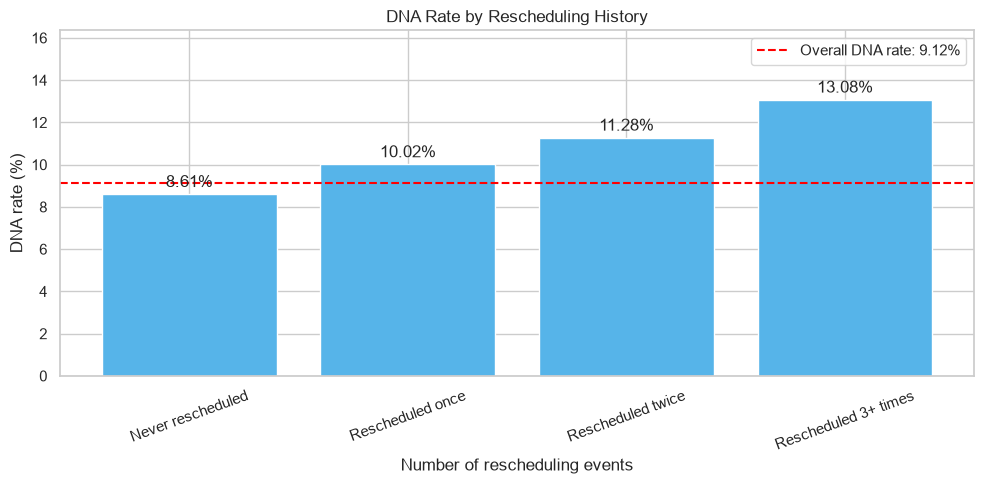


8. PREVIOUS DNAs AND RESCHEDULING COMBINED


,previous_dna_group,reschedule_group,appointments,dna_count,attended_count,dna_rate_percent
0,0 previous DNAs,Never rescheduled,20913,1437,19476,6.87
1,0 previous DNAs,Rescheduled 3+ times,542,63,479,11.62
2,0 previous DNAs,Rescheduled once,5185,437,4748,8.43
3,0 previous DNAs,Rescheduled twice,1678,146,1532,8.70
4,1 previous DNA,Never rescheduled,4793,601,4192,12.54
5,1 previous DNA,Rescheduled 3+ times,118,17,101,14.41
6,1 previous DNA,Rescheduled once,1187,151,1036,12.72
7,1 previous DNA,Rescheduled twice,426,72,354,16.90
8,2 previous DNAs,Never rescheduled,845,188,657,22.25
9,2 previous DNAs,Rescheduled 3+ times,24,9,15,37.50



9. COMBINED HISTORY HEATMAP


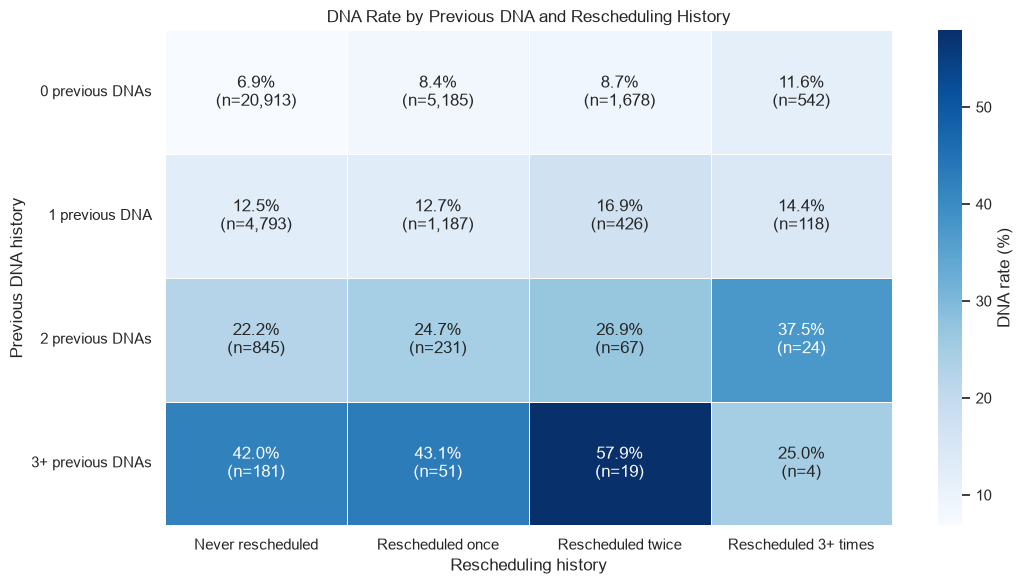


10. POINT-IN-TIME FEATURE AVAILABILITY


,feature,availability_status,required_check,modelling_decision
0,previous_dnas_12m,Not yet verified,Reconstruct prior DNAs from appointments with ...,Use only after point-in-time validation.
1,rescheduled_count,Not yet verified,Confirm rescheduling events occurred on or bef...,Use only after point-in-time validation.



11. SAVE HISTORICAL EDA RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_previous_dna_count.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_previous_dna_group.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_rescheduled_count.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_rescheduling_group.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_history_and_rescheduling.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\history_feature_availability_audit.csv

12. KEY HISTORICAL EDA FINDINGS
Total appointments: 36,264
Overall DNA rate: 9.12%

Previous DNA history and rescheduling may be associated with current attendance.
The descriptive tables show the direction and magnitude of these relationships.

Important model

In [64]:

# PREVIOUS DNAs AND RESCHEDULING HISTORY

# Objectives:
# 1. Examine previous DNA history.
# 2. Calculate current DNA rates by previous DNA count.
# 3. Examine appointment rescheduling.
# 4. Calculate DNA rates by rescheduling count.
# 5. Explore the combination of history and rescheduling.
# 6. Document potential point-in-time leakage risks.
# 7. Save descriptive tables and charts.

print("PREVIOUS DNAs AND RESCHEDULING HISTORY")

# 1. Prepare a separate dataframe for EDA.


df_history = df_binary.copy()

required_columns = [
    "previous_dnas_12m",
    "rescheduled_count",
    "dna_target",
    "booking_lead_days",
    "prediction_cutoff_datetime"
]

assert all(
    column in df_history.columns
    for column in required_columns
), "Required history columns are missing."

assert len(df_history) == 36264

# 2. Check the quality of historical variables.
# Missing or negative counts should be investigated,
# rather than silently corrected.

print("\n1. HISTORICAL FEATURE DATA QUALITY")

history_columns = [
    "previous_dnas_12m",
    "rescheduled_count"
]

for column in history_columns:

    df_history[column] = pd.to_numeric(
        df_history[column],
        errors="coerce"
    )

    print(f"\nFeature: {column}")

    print(
        f"Missing values: "
        f"{df_history[column].isna().sum():,}"
    )

    print(
        f"Minimum: {df_history[column].min()}"
    )

    print(
        f"Maximum: {df_history[column].max()}"
    )

    display(df_history[column].describe())

    assert df_history[column].notna().all(), (
        f"Missing values found in {column}."
    )

    assert (df_history[column] >= 0).all(), (
        f"Negative values found in {column}."
    )

    assert (
        df_history[column] % 1 == 0
    ).all(), (
        f"Non-integer counts found in {column}."
    )

# 3. Create a reusable DNA summary function.

def history_dna_summary(data, group_columns):

    summary = (
        data.groupby(
            group_columns,
            dropna=False
        )["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    summary["attended_count"] = (
        summary["appointments"]
        - summary["dna_count"]
    )

    summary["dna_rate_percent"] = (
        summary["dna_rate"] * 100
    ).round(2)

    return summary.drop(columns="dna_rate")

# 4. Examine previous DNAs in the last 12 months.
# These are historical counts recorded in the dataset.

print("\n2. PREVIOUS DNA HISTORY")

previous_dna_summary = history_dna_summary(
    df_history,
    ["previous_dnas_12m"]
).sort_values("previous_dnas_12m")

display(previous_dna_summary)

assert previous_dna_summary["appointments"].sum() == 36264
assert previous_dna_summary["dna_count"].sum() == 3306

# 5. Group previous DNA counts for easier interpretation.
# Counts of 3 or more are grouped together.
# This is for descriptive analysis only.

print("\n3. PREVIOUS DNA HISTORY GROUPS")

df_history["previous_dna_group"] = (
    df_history["previous_dnas_12m"]
    .apply(
        lambda value: (
            "0 previous DNAs" if value == 0
            else "1 previous DNA" if value == 1
            else "2 previous DNAs" if value == 2
            else "3+ previous DNAs"
        )
    )
)

previous_dna_order = [
    "0 previous DNAs",
    "1 previous DNA",
    "2 previous DNAs",
    "3+ previous DNAs"
]

previous_dna_group_summary = history_dna_summary(
    df_history,
    ["previous_dna_group"]
)

previous_dna_group_summary["previous_dna_group"] = (
    pd.Categorical(
        previous_dna_group_summary["previous_dna_group"],
        categories=previous_dna_order,
        ordered=True
    )
)

previous_dna_group_summary = (
    previous_dna_group_summary
    .sort_values("previous_dna_group")
    .reset_index(drop=True)
)

display(previous_dna_group_summary)

# 6. Visualise DNA rates by previous DNA history.

print("\n4. DNA RATE BY PREVIOUS DNA HISTORY")

overall_dna_rate = df_history["dna_target"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    previous_dna_group_summary[
        "previous_dna_group"
    ].astype(str),
    previous_dna_group_summary["dna_rate_percent"],
    color="#377eb8"
)

ax.axhline(
    overall_dna_rate,
    color="red",
    linestyle="--",
    label=f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

for bar, rate in zip(
    bars,
    previous_dna_group_summary["dna_rate_percent"]
):

    ax.annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("Current DNA Rate by Previous DNA History")
ax.set_xlabel("Previous DNAs in the last 12 months")
ax.set_ylabel("Current DNA rate (%)")

ax.set_ylim(
    0,
    max(
        previous_dna_group_summary["dna_rate_percent"].max(),
        overall_dna_rate
    ) * 1.25
)

ax.legend()

plt.tight_layout()

previous_dna_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_previous_dnas.png"
)

plt.savefig(
    previous_dna_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 7. Examine appointment rescheduling history.


print("\n5. RESCHEDULING HISTORY")

reschedule_summary = history_dna_summary(
    df_history,
    ["rescheduled_count"]
).sort_values("rescheduled_count")

display(reschedule_summary)

assert reschedule_summary["appointments"].sum() == 36264

# 8. Create rescheduling groups.

print("\n6. RESCHEDULING GROUPS")

df_history["reschedule_group"] = (
    df_history["rescheduled_count"]
    .apply(
        lambda value: (
            "Never rescheduled" if value == 0
            else "Rescheduled once" if value == 1
            else "Rescheduled twice" if value == 2
            else "Rescheduled 3+ times"
        )
    )
)

reschedule_order = [
    "Never rescheduled",
    "Rescheduled once",
    "Rescheduled twice",
    "Rescheduled 3+ times"
]

reschedule_group_summary = history_dna_summary(
    df_history,
    ["reschedule_group"]
)

reschedule_group_summary["reschedule_group"] = (
    pd.Categorical(
        reschedule_group_summary["reschedule_group"],
        categories=reschedule_order,
        ordered=True
    )
)

reschedule_group_summary = (
    reschedule_group_summary
    .sort_values("reschedule_group")
    .reset_index(drop=True)
)

display(reschedule_group_summary)

# 9. Visualise DNA rates by rescheduling group.

print("\n7. DNA RATE BY RESCHEDULING HISTORY")

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    reschedule_group_summary[
        "reschedule_group"
    ].astype(str),
    reschedule_group_summary["dna_rate_percent"],
    color="#56b4e9"
)

ax.axhline(
    overall_dna_rate,
    color="red",
    linestyle="--",
    label=f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

for bar, rate in zip(
    bars,
    reschedule_group_summary["dna_rate_percent"]
):

    ax.annotate(
        f"{rate:.2f}%",
        (
            bar.get_x() + bar.get_width() / 2,
            bar.get_height()
        ),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center"
    )

ax.set_title("DNA Rate by Rescheduling History")
ax.set_xlabel("Number of rescheduling events")
ax.set_ylabel("DNA rate (%)")
ax.tick_params(axis="x", rotation=20)

ax.set_ylim(
    0,
    max(
        reschedule_group_summary["dna_rate_percent"].max(),
        overall_dna_rate
    ) * 1.25
)

ax.legend()

plt.tight_layout()

reschedule_chart_path = (
    EDA_REPORT_DIR / "dna_rate_by_rescheduling.png"
)

plt.savefig(
    reschedule_chart_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 10. Examine the combination of previous DNAs
# and rescheduling history.
# This is descriptive analysis, not model training.

print("\n8. PREVIOUS DNAs AND RESCHEDULING COMBINED")

history_combined_summary = history_dna_summary(
    df_history,
    [
        "previous_dna_group",
        "reschedule_group"
    ]
)

display(history_combined_summary)

assert history_combined_summary["appointments"].sum() == 36264

# 11. Create a heatmap for the combined groups.
# Unobserved combinations remain blank.

print("\n9. COMBINED HISTORY HEATMAP")

history_heatmap = history_combined_summary.pivot(
    index="previous_dna_group",
    columns="reschedule_group",
    values="dna_rate_percent"
)

history_heatmap = history_heatmap.reindex(
    index=previous_dna_order,
    columns=reschedule_order
)

history_counts = history_combined_summary.pivot(
    index="previous_dna_group",
    columns="reschedule_group",
    values="appointments"
).reindex(
    index=previous_dna_order,
    columns=reschedule_order
)

heatmap_labels = history_heatmap.copy().astype(object)

for row in history_heatmap.index:
    for column in history_heatmap.columns:

        rate = history_heatmap.loc[row, column]
        count = history_counts.loc[row, column]

        if pd.notna(rate):
            heatmap_labels.loc[row, column] = (
                f"{rate:.1f}%\n(n={int(count):,})"
            )
        else:
            heatmap_labels.loc[row, column] = ""

fig, ax = plt.subplots(figsize=(11, 6))

sns.heatmap(
    history_heatmap,
    annot=heatmap_labels,
    fmt="",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "DNA rate (%)"},
    ax=ax
)

ax.set_title(
    "DNA Rate by Previous DNA and Rescheduling History"
)

ax.set_xlabel("Rescheduling history")
ax.set_ylabel("Previous DNA history")

plt.tight_layout()

history_heatmap_path = (
    EDA_REPORT_DIR / "dna_rate_history_rescheduling_heatmap.png"
)

plt.savefig(
    history_heatmap_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 12. Review point-in-time feature availability.
# The dataset contains the counts but does not include
# timestamps for each historical DNA or rescheduling event.

#
# This is a leakage audit flag, not a finding of leakage.

print("\n10. POINT-IN-TIME FEATURE AVAILABILITY")

feature_availability = pd.DataFrame([
    {
        "feature": "previous_dnas_12m",
        "availability_status": "Not yet verified",
        "required_check": (
            "Reconstruct prior DNAs from appointments "
            "with outcomes known before prediction cutoff."
        ),
        "modelling_decision": (
            "Use only after point-in-time validation."
        )
    },
    {
        "feature": "rescheduled_count",
        "availability_status": "Not yet verified",
        "required_check": (
            "Confirm rescheduling events occurred "
            "on or before prediction cutoff."
        ),
        "modelling_decision": (
            "Use only after point-in-time validation."
        )
    }
])

display(feature_availability)

# 13. Save descriptive EDA results.

print("\n11. SAVE HISTORICAL EDA RESULTS")

history_tables = {
    "dna_rate_by_previous_dna_count.csv": previous_dna_summary,
    "dna_rate_by_previous_dna_group.csv": previous_dna_group_summary,
    "dna_rate_by_rescheduled_count.csv": reschedule_summary,
    "dna_rate_by_rescheduling_group.csv": reschedule_group_summary,
    "dna_rate_by_history_and_rescheduling.csv": history_combined_summary,
    "history_feature_availability_audit.csv": feature_availability
}

for filename, table in history_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")

# 14. Summarise key findings.

print("\n12. KEY HISTORICAL EDA FINDINGS")

print(f"Total appointments: {len(df_history):,}")

print(f"Overall DNA rate: {overall_dna_rate:.2f}%")

print(
    "\nPrevious DNA history and rescheduling "
    "may be associated with current attendance."
)

print(
    "The descriptive tables show the direction "
    "and magnitude of these relationships."
)

print(
    "\nImportant modelling limitation:"
)

print(
    "Historical counts must be reconstructed or "
    "verified at each prediction cutoff to avoid "
    "using information from the future."
)

print(
    "No records have been removed, and no models "
    "have been trained in this cell."
)

print("COMPLETED SUCCESSFULLY")


CELL 9: REMINDERS AND OTHER PATIENT CHARACTERISTICS
Eligible appointments: 36,264
DNA appointments: 3,306
Overall DNA rate: 9.12%

1. SMS REMINDER STATUS


,sms_reminder_eda,appointments,dna_count,attended_count,dna_rate_percent
0,Y,27571,2320,25251,8.41
1,N,8693,986,7707,11.34



2. DNA RATE BY SMS REMINDER STATUS


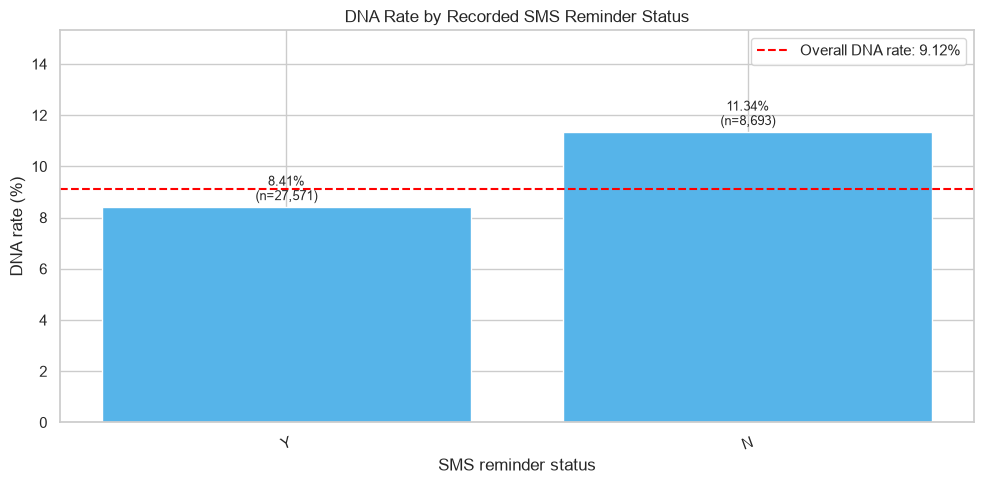

Saved chart: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_sms_reminder.png

3. TRAVEL DISTANCE DATA QUALITY
Missing distances: 362
Negative distances: 0


count    35902.00
mean         8.34
std          5.67
min          0.30
25%          4.20
50%          7.00
75%         11.10
max         47.40
Name: distance_numeric, dtype: float64


4. DNA RATE BY TRAVEL DISTANCE


,distance_band,appointments,dna_count,attended_count,dna_rate_percent
0,0–<5 km,11607,968,10639,8.34
1,5–<10 km,13372,1221,12151,9.13
2,10–<20 km,9331,922,8409,9.88
3,20–<40 km,1580,166,1414,10.51
4,40+ km,12,1,11,8.33
5,Missing distance,362,28,334,7.73



5. TRAVEL DISTANCE CHART


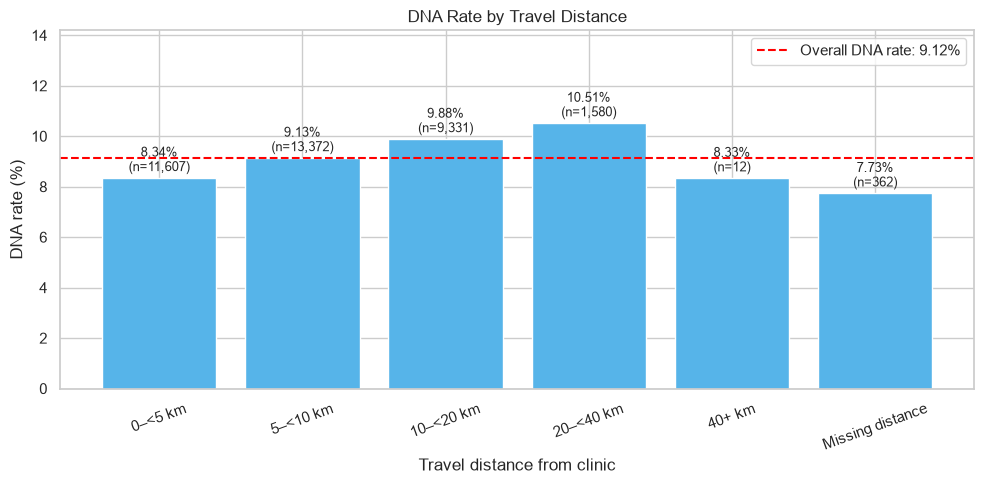

Saved chart: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_travel_distance.png

6. INTERPRETER REQUIREMENTS


,interpreter_eda,appointments,dna_count,attended_count,dna_rate_percent
0,N,34775,3113,31662,8.95
1,Y,1489,193,1296,12.96


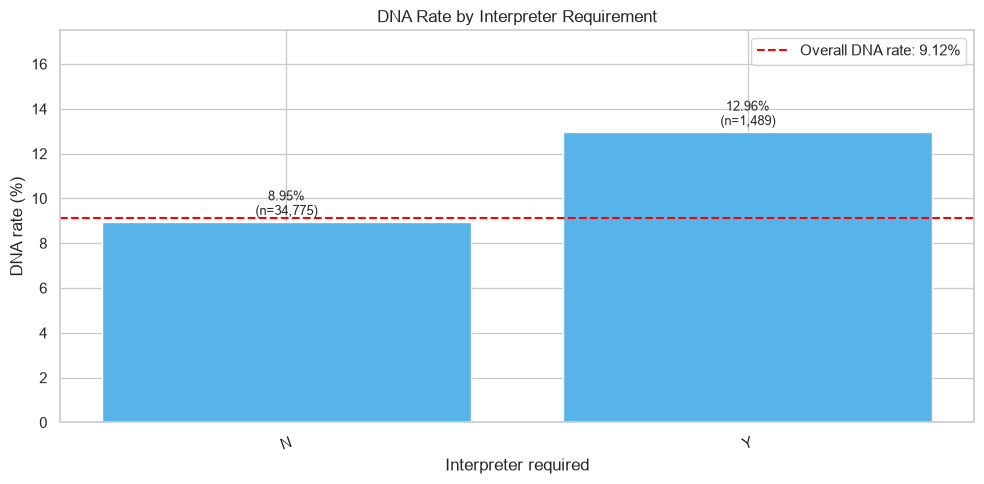

Saved chart: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_interpreter_requirement.png

7. LONG-TERM CONDITIONS
Missing counts: 0
Negative counts: 0
Non-integer counts: 0


count    36264.00
mean         1.28
std          1.40
min          0.00
25%          0.00
50%          1.00
75%          2.00
max          8.00
Name: ltc_numeric, dtype: float64

,ltc_numeric,appointments,dna_count,attended_count,dna_rate_percent
0,0,13771,1398,12373,10.15
1,1,9712,913,8799,9.40
2,2,6286,508,5778,8.08
3,3,3550,286,3264,8.06
4,4,1749,136,1613,7.78
5,5,837,42,795,5.02
6,6,258,15,243,5.81
7,7,68,6,62,8.82
8,8,33,2,31,6.06



8. LONG-TERM CONDITION GROUPS


,ltc_group,appointments,dna_count,attended_count,dna_rate_percent
0,0 conditions,13771,1398,12373,10.15
1,1 condition,9712,913,8799,9.40
2,2 conditions,6286,508,5778,8.08
3,3+ conditions,6495,487,6008,7.50



9. DNA RATE BY LONG-TERM CONDITIONS


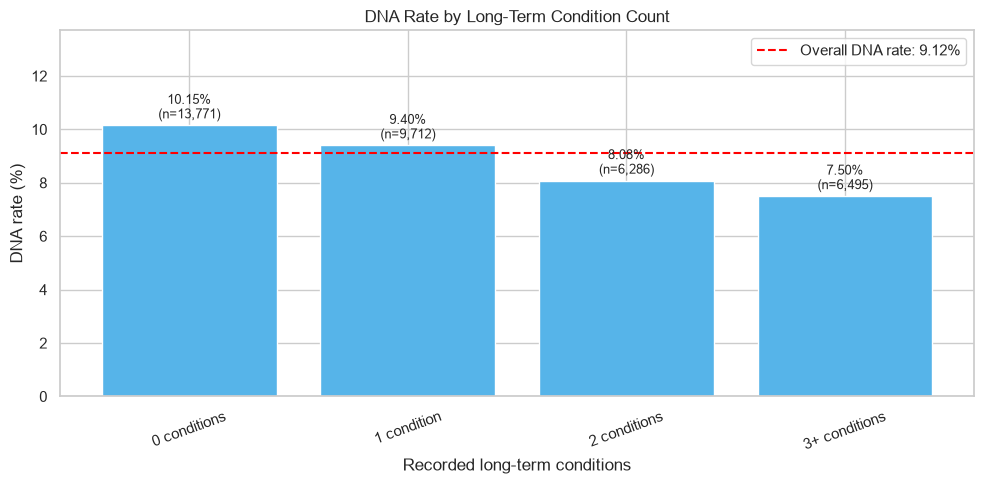

Saved chart: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_long_term_conditions.png

10. REFERRAL SOURCES


,referral_eda,appointments,dna_count,attended_count,dna_rate_percent
0,Consultant,24511,2079,22432,8.48
1,GP,9274,990,8284,10.68
2,A&E,1351,107,1244,7.92
3,Other,1128,130,998,11.52



11. DNA RATE BY REFERRAL SOURCE


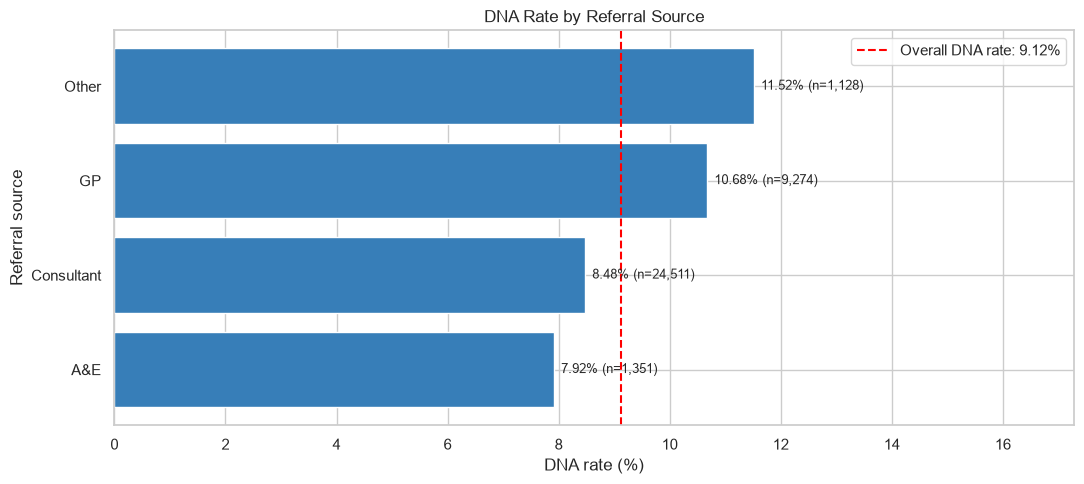

Saved chart: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_referral_source.png

12. MISSING VALUE SUMMARY


,feature,missing_count,missing_percent
0,sms_reminder_sent,0,0.0
1,distance_km,362,1.0
2,interpreter_required,0,0.0
3,long_term_conditions,0,0.0
4,referral_source,0,0.0



13. FEATURE AVAILABILITY REVIEW


,feature,availability_status,required_check,modelling_decision
0,sms_reminder_sent,Not verified,Confirm SMS reminder timestamp is on or before...,Exclude until timing is verified.
1,distance_km,Requires verification,Confirm distance was derived from patient and ...,Potentially usable after validation.
2,interpreter_required,Requires verification,Confirm interpreter requirement was recorded b...,Potentially usable after validation.
3,long_term_conditions,Requires verification,Confirm the condition count reflects only diag...,Potentially usable after validation.
4,referral_source,Requires verification,Confirm referral source was known before the p...,Potentially usable after validation.



Important: These are feature availability assessments, not proof that leakage has occurred.

14. SAVE CELL 9 RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_sms_reminder.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_travel_distance.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_interpreter_requirement.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_long_term_conditions.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_long_term_condition_group.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\dna_rate_by_referral_source.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell9_missingness_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\repo

,sms_reminder_eda,appointments,dna_count,dna_rate_percent
0,Y,27571,2320,8.41
1,N,8693,986,11.34



Observed DNA rates by travel distance:


,distance_band,appointments,dna_count,dna_rate_percent
0,0–<5 km,11607,968,8.34
1,5–<10 km,13372,1221,9.13
2,10–<20 km,9331,922,9.88
3,20–<40 km,1580,166,10.51
4,40+ km,12,1,8.33
5,Missing distance,362,28,7.73



The results are descriptive associations. They do not demonstrate causation.
Reminder timing and other feature availability must be verified before modelling.
No appointments were removed, no missing values were imputed, and no models were trained.

CELL 9 COMPLETED SUCCESSFULLY


In [65]:

# REMINDERS AND OTHER PATIENT CHARACTERISTICS


# Objectives:
# 1. Examine SMS reminder status and DNA rates.
# 2. Investigate travel distance and missed appointments.
# 3. Examine interpreter requirements.
# 4. Examine long-term condition counts.
# 5. Compare DNA rates across referral sources.
# 6. Review missing values and feature availability.
# 7. Save descriptive tables and charts.

print("CELL 9: REMINDERS AND OTHER PATIENT CHARACTERISTICS")

# 1. Prepare a separate dataframe.
# This avoids modifying the original modelling dataset.

df_other = df_binary.copy()

required_columns = [
    "sms_reminder_sent",
    "distance_km",
    "interpreter_required",
    "long_term_conditions",
    "referral_source",
    "dna_target",
    "prediction_cutoff_datetime"
]

missing_columns = [
    column for column in required_columns
    if column not in df_other.columns
]

assert not missing_columns, (
    f"Missing required columns: {missing_columns}"
)

assert len(df_other) == 36264, (
    f"Unexpected modelling cohort size: {len(df_other)}"
)

assert df_other["dna_target"].notna().all(), (
    "Missing DNA target values detected."
)

assert df_other["dna_target"].isin([0, 1]).all(), (
    "DNA target must contain only 0 and 1."
)

assert int(df_other["dna_target"].sum()) == 3306, (
    "Unexpected number of DNA outcomes."
)

EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

overall_rate = df_other["dna_target"].mean() * 100

print(f"Eligible appointments: {len(df_other):,}")
print(f"DNA appointments: {int(df_other['dna_target'].sum()):,}")
print(f"Overall DNA rate: {overall_rate:.2f}%")

# 2. Define a reusable descriptive summary function.
# DNA rates are percentages of appointments in each group.

def other_dna_summary(data, column):

    summary = (
        data.groupby(
            column,
            dropna=False,
            observed=True
        )["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    summary["attended_count"] = (
        summary["appointments"] - summary["dna_count"]
    )

    summary["dna_rate_percent"] = (
        summary["dna_rate"] * 100
    ).round(2)

    return summary.drop(columns="dna_rate")


# 3. Define a helper for categorical EDA labels.
# Blank strings and missing values are reported as Missing.
# Original source columns are preserved.

def prepare_category(series):

    cleaned = (
        series.astype("string")
        .str.strip()
    )

    cleaned = cleaned.replace("", pd.NA)

    return cleaned.fillna("Missing").astype(str)


# 4. Define a chart helper.
# This keeps charts consistent across categorical features.

def plot_dna_rates(
    summary,
    category_column,
    title,
    xlabel,
    filename,
    horizontal=False
):

    plot_data = summary.loc[
        summary["appointments"] > 0
    ].copy()

    if plot_data.empty:
        print(f"No observations available for {title}.")
        return

    fig, ax = plt.subplots(
        figsize=(
            11,
            max(5, len(plot_data) * 0.65)
        ) if horizontal else (10, 5)
    )

    if horizontal:

        plot_data = plot_data.sort_values(
            "dna_rate_percent"
        )

        bars = ax.barh(
            plot_data[category_column].astype(str),
            plot_data["dna_rate_percent"],
            color="#377eb8"
        )

        ax.axvline(
            overall_rate,
            color="red",
            linestyle="--",
            label=f"Overall DNA rate: {overall_rate:.2f}%"
        )

        for bar, rate, count in zip(
            bars,
            plot_data["dna_rate_percent"],
            plot_data["appointments"]
        ):

            ax.annotate(
                f"{rate:.2f}% (n={count:,})",
                (
                    bar.get_width(),
                    bar.get_y() + bar.get_height() / 2
                ),
                xytext=(5, 0),
                textcoords="offset points",
                va="center",
                fontsize=9
            )

        ax.set_xlim(
            0,
            max(
                plot_data["dna_rate_percent"].max(),
                overall_rate,
                1
            ) * 1.5
        )

        ax.set_xlabel("DNA rate (%)")
        ax.set_ylabel(xlabel)

    else:

        bars = ax.bar(
            plot_data[category_column].astype(str),
            plot_data["dna_rate_percent"],
            color="#56b4e9"
        )

        ax.axhline(
            overall_rate,
            color="red",
            linestyle="--",
            label=f"Overall DNA rate: {overall_rate:.2f}%"
        )

        for bar, rate, count in zip(
            bars,
            plot_data["dna_rate_percent"],
            plot_data["appointments"]
        ):

            ax.annotate(
                f"{rate:.2f}%\n(n={count:,})",
                (
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height()
                ),
                xytext=(0, 5),
                textcoords="offset points",
                ha="center",
                fontsize=9
            )

        ax.set_ylim(
            0,
            max(
                plot_data["dna_rate_percent"].max(),
                overall_rate,
                1
            ) * 1.35
        )

        ax.set_xlabel(xlabel)
        ax.set_ylabel("DNA rate (%)")
        ax.tick_params(axis="x", rotation=20)

    ax.set_title(title)
    ax.legend()

    plt.tight_layout()

    output_path = EDA_REPORT_DIR / filename

    plt.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved chart: {output_path}")


# 5. Examine SMS reminder status.
# Recorded reminder status is not necessarily the status
# that was known at the prediction cutoff.

print("\n1. SMS REMINDER STATUS")

df_other["sms_reminder_eda"] = prepare_category(
    df_other["sms_reminder_sent"]
)

sms_summary = other_dna_summary(
    df_other,
    "sms_reminder_eda"
).sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

display(sms_summary)

assert sms_summary["appointments"].sum() == 36264
assert sms_summary["dna_count"].sum() == 3306

print("\n2. DNA RATE BY SMS REMINDER STATUS")

plot_dna_rates(
    summary=sms_summary,
    category_column="sms_reminder_eda",
    title="DNA Rate by Recorded SMS Reminder Status",
    xlabel="SMS reminder status",
    filename="dna_rate_by_sms_reminder.png"
)




# 6. Examine travel distance data quality.
# Convert to numeric for descriptive analysis.


print("\n3. TRAVEL DISTANCE DATA QUALITY")

df_other["distance_numeric"] = pd.to_numeric(
    df_other["distance_km"],
    errors="coerce"
)

missing_distance = int(
    df_other["distance_numeric"].isna().sum()
)

negative_distance = int(
    (df_other["distance_numeric"] < 0).sum()
)

print(f"Missing distances: {missing_distance:,}")
print(f"Negative distances: {negative_distance:,}")

display(
    df_other["distance_numeric"]
    .describe()
    .round(2)
)

assert negative_distance == 0, (
    "Negative travel distances require investigation."
)

# 7. Group travel distance into meaningful bands.
# Missing distances remain in a separate category.

print("\n4. DNA RATE BY TRAVEL DISTANCE")

distance_bins = [
    0,
    5,
    10,
    20,
    40,
    np.inf
]

distance_labels = [
    "0–<5 km",
    "5–<10 km",
    "10–<20 km",
    "20–<40 km",
    "40+ km"
]

df_other["distance_band"] = pd.cut(
    df_other["distance_numeric"],
    bins=distance_bins,
    labels=distance_labels,
    right=False,
    include_lowest=True
)

df_other["distance_band"] = (
    df_other["distance_band"]
    .cat.add_categories(["Missing distance"])
    .fillna("Missing distance")
)

distance_order = (
    distance_labels + ["Missing distance"]
)

distance_summary = other_dna_summary(
    df_other,
    "distance_band"
)

distance_summary["distance_band"] = pd.Categorical(
    distance_summary["distance_band"],
    categories=distance_order,
    ordered=True
)

distance_summary = (
    distance_summary
    .sort_values("distance_band")
    .reset_index(drop=True)
)

display(distance_summary)

assert distance_summary["appointments"].sum() == 36264
assert distance_summary["dna_count"].sum() == 3306

print("\n5. TRAVEL DISTANCE CHART")

plot_dna_rates(
    summary=distance_summary,
    category_column="distance_band",
    title="DNA Rate by Travel Distance",
    xlabel="Travel distance from clinic",
    filename="dna_rate_by_travel_distance.png"
)


# 8. Examine interpreter requirements.


print("\n6. INTERPRETER REQUIREMENTS")

df_other["interpreter_eda"] = prepare_category(
    df_other["interpreter_required"]
)

interpreter_summary = other_dna_summary(
    df_other,
    "interpreter_eda"
).sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

display(interpreter_summary)

assert interpreter_summary["appointments"].sum() == 36264
assert interpreter_summary["dna_count"].sum() == 3306

plot_dna_rates(
    summary=interpreter_summary,
    category_column="interpreter_eda",
    title="DNA Rate by Interpreter Requirement",
    xlabel="Interpreter required",
    filename="dna_rate_by_interpreter_requirement.png"
)


# 9. Examine long-term condition counts.


print("\n7. LONG-TERM CONDITIONS")

df_other["ltc_numeric"] = pd.to_numeric(
    df_other["long_term_conditions"],
    errors="coerce"
)

missing_ltc = int(
    df_other["ltc_numeric"].isna().sum()
)

negative_ltc = int(
    (df_other["ltc_numeric"] < 0).sum()
)

non_integer_ltc = int(
    (
        df_other["ltc_numeric"].notna()
        & (df_other["ltc_numeric"] % 1 != 0)
    ).sum()
)

print(f"Missing counts: {missing_ltc:,}")
print(f"Negative counts: {negative_ltc:,}")
print(f"Non-integer counts: {non_integer_ltc:,}")

display(
    df_other["ltc_numeric"]
    .describe()
    .round(2)
)

assert negative_ltc == 0, (
    "Negative long-term condition counts detected."
)

assert non_integer_ltc == 0, (
    "Non-integer long-term condition counts detected."
)

ltc_summary = other_dna_summary(
    df_other,
    "ltc_numeric"
).sort_values("ltc_numeric")

display(ltc_summary)

assert ltc_summary["appointments"].sum() == 36264
assert ltc_summary["dna_count"].sum() == 3306

# 10. Group long-term condition counts for reporting.

print("\n8. LONG-TERM CONDITION GROUPS")

def assign_ltc_group(value):

    if pd.isna(value):
        return "Missing"

    if value == 0:
        return "0 conditions"

    if value == 1:
        return "1 condition"

    if value == 2:
        return "2 conditions"

    return "3+ conditions"


df_other["ltc_group"] = (
    df_other["ltc_numeric"]
    .apply(assign_ltc_group)
)

ltc_order = [
    "0 conditions",
    "1 condition",
    "2 conditions",
    "3+ conditions",
    "Missing"
]

ltc_group_summary = other_dna_summary(
    df_other,
    "ltc_group"
)

ltc_group_summary["ltc_group"] = pd.Categorical(
    ltc_group_summary["ltc_group"],
    categories=ltc_order,
    ordered=True
)

ltc_group_summary = (
    ltc_group_summary
    .sort_values("ltc_group")
    .reset_index(drop=True)
)

display(ltc_group_summary)

assert ltc_group_summary["appointments"].sum() == 36264
assert ltc_group_summary["dna_count"].sum() == 3306

print("\n9. DNA RATE BY LONG-TERM CONDITIONS")

plot_dna_rates(
    summary=ltc_group_summary,
    category_column="ltc_group",
    title="DNA Rate by Long-Term Condition Count",
    xlabel="Recorded long-term conditions",
    filename="dna_rate_by_long_term_conditions.png"
)


# 11. Examine referral sources.
# Missing and blank referral sources remain visible.

print("\n10. REFERRAL SOURCES")

df_other["referral_eda"] = prepare_category(
    df_other["referral_source"]
)

referral_summary = other_dna_summary(
    df_other,
    "referral_eda"
).sort_values(
    "appointments",
    ascending=False
).reset_index(drop=True)

display(referral_summary)

assert referral_summary["appointments"].sum() == 36264
assert referral_summary["dna_count"].sum() == 3306

print("\n11. DNA RATE BY REFERRAL SOURCE")

plot_dna_rates(
    summary=referral_summary,
    category_column="referral_eda",
    title="DNA Rate by Referral Source",
    xlabel="Referral source",
    filename="dna_rate_by_referral_source.png",
    horizontal=True
)


# 12. Summarise missingness for Cell 9 variables.


print("\n12. MISSING VALUE SUMMARY")

missingness_summary = pd.DataFrame({
    "feature": [
        "sms_reminder_sent",
        "distance_km",
        "interpreter_required",
        "long_term_conditions",
        "referral_source"
    ],
    "missing_count": [
        int(df_other["sms_reminder_eda"].eq("Missing").sum()),
        missing_distance,
        int(df_other["interpreter_eda"].eq("Missing").sum()),
        missing_ltc,
        int(df_other["referral_eda"].eq("Missing").sum())
    ]
})

missingness_summary["missing_percent"] = (
    missingness_summary["missing_count"]
    / len(df_other) * 100
).round(2)

display(missingness_summary)


# 13. Document feature availability and leakage risks.


print("\n13. FEATURE AVAILABILITY REVIEW")

feature_availability = pd.DataFrame([
    {
        "feature": "sms_reminder_sent",
        "availability_status": "Not verified",
        "required_check": (
            "Confirm SMS reminder timestamp is on or "
            "before the prediction cutoff."
        ),
        "modelling_decision": (
            "Exclude until timing is verified."
        )
    },
    {
        "feature": "distance_km",
        "availability_status": "Requires verification",
        "required_check": (
            "Confirm distance was derived from patient "
            "and clinic information available at cutoff."
        ),
        "modelling_decision": (
            "Potentially usable after validation."
        )
    },
    {
        "feature": "interpreter_required",
        "availability_status": "Requires verification",
        "required_check": (
            "Confirm interpreter requirement was recorded "
            "before the prediction cutoff."
        ),
        "modelling_decision": (
            "Potentially usable after validation."
        )
    },
    {
        "feature": "long_term_conditions",
        "availability_status": "Requires verification",
        "required_check": (
            "Confirm the condition count reflects only "
            "diagnoses known at the prediction cutoff."
        ),
        "modelling_decision": (
            "Potentially usable after validation."
        )
    },
    {
        "feature": "referral_source",
        "availability_status": "Requires verification",
        "required_check": (
            "Confirm referral source was known before "
            "the prediction cutoff."
        ),
        "modelling_decision": (
            "Potentially usable after validation."
        )
    }
])

display(feature_availability)

print(
    "\nImportant: These are feature availability "
    "assessments, not proof that leakage has occurred."
)


# 14. Save all descriptive EDA results.

print("\n14. SAVE CELL 9 RESULTS")

cell9_tables = {
    "dna_rate_by_sms_reminder.csv": sms_summary,
    "dna_rate_by_travel_distance.csv": distance_summary,
    "dna_rate_by_interpreter_requirement.csv": interpreter_summary,
    "dna_rate_by_long_term_conditions.csv": ltc_summary,
    "dna_rate_by_long_term_condition_group.csv": ltc_group_summary,
    "dna_rate_by_referral_source.csv": referral_summary,
    "cell9_missingness_summary.csv": missingness_summary,
    "cell9_feature_availability_audit.csv": feature_availability
}

for filename, table in cell9_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")


# 15. Summarise key descriptive findings.

print("\n15. KEY CELL 9 FINDINGS")

print(f"Total eligible appointments: {len(df_other):,}")
print(f"Total DNA appointments: {int(df_other['dna_target'].sum()):,}")
print(f"Overall DNA rate: {overall_rate:.2f}%")

print(
    f"Missing travel distances: {missing_distance:,} "
    f"({missing_distance / len(df_other) * 100:.2f}%)."
)

print(
    f"Missing long-term condition counts: {missing_ltc:,}."
)

print("\nObserved DNA rates by SMS reminder status:")
display(
    sms_summary[
        [
            "sms_reminder_eda",
            "appointments",
            "dna_count",
            "dna_rate_percent"
        ]
    ]
)

print("\nObserved DNA rates by travel distance:")
display(
    distance_summary[
        [
            "distance_band",
            "appointments",
            "dna_count",
            "dna_rate_percent"
        ]
    ]
)

print(
    "\nThe results are descriptive associations. "
    "They do not demonstrate causation."
)

print(
    "Reminder timing and other feature availability "
    "must be verified before modelling."
)

print(
    "No appointments were removed, no missing values "
    "were imputed, and no models were trained."
)

print("\nCELL 9 COMPLETED SUCCESSFULLY")



CELL 10: MISSINGNESS AND FEATURE RELATIONSHIPS
Eligible appointments: 36,264
DNA appointments: 3,306
Overall DNA rate: 9.12%

1. MISSING VALUE SUMMARY


,feature,data_type,missing_count,unique_values,missing_percent
0,clinic_checkin_time,datetime64[s],36264,0,100.00
1,imd_decile,float64,1265,10,3.49
2,distance_km,float64,362,348,1.00
3,age,float64,48,102,0.13
4,appointment_datetime,datetime64[us],0,4419,0.00
5,appointment_id,str,0,36264,0.00
6,appointment_type,str,0,2,0.00
7,attendance_status,str,0,2,0.00
8,booked_datetime,datetime64[us],0,33795,0.00
9,booking_lead_days,float64,0,29591,0.00


Columns containing missing values: 4
Total missing cells: 37939

2. MISSINGNESS CHART


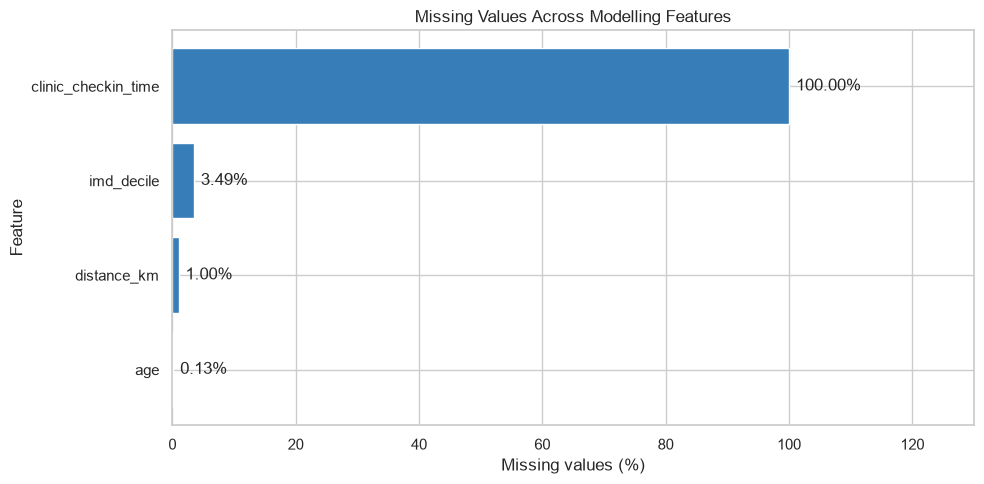


3. MISSINGNESS AND DNA OUTCOMES


,feature,missing_count,observed_count,missing_dna_count,observed_dna_count,missing_dna_rate_percent,observed_dna_rate_percent,rate_difference_pp
0,imd_decile,1265,34999,105,3201,8.30,9.15,-0.85
1,distance_km,362,35902,28,3278,7.73,9.13,-1.40
2,age,48,36216,3,3303,6.25,9.12,-2.87



Differences in observed DNA rates do not prove that missingness causes missed appointments.

4. NUMERICAL FEATURE RELATIONSHIPS
Available numerical candidates:
['age', 'booking_lead_days', 'previous_dnas_12m', 'rescheduled_count', 'distance_km', 'long_term_conditions']


,feature,non_missing_count,missing_count,unique_values
0,age,36216,48,102
1,booking_lead_days,36264,0,29591
2,previous_dnas_12m,36264,0,8
3,rescheduled_count,36264,0,4
4,distance_km,35902,362,348
5,long_term_conditions,36264,0,9



5. SPEARMAN CORRELATION MATRIX


,age,booking_lead_days,previous_dnas_12m,rescheduled_count,distance_km,long_term_conditions
age,1.000,0.008,-0.005,0.004,-0.008,0.591
booking_lead_days,0.008,1.000,0.005,0.007,-0.004,0.001
previous_dnas_12m,-0.005,0.005,1.000,0.007,-0.007,-0.014
rescheduled_count,0.004,0.007,0.007,1.000,-0.012,0.002
distance_km,-0.008,-0.004,-0.007,-0.012,1.000,-0.008
long_term_conditions,0.591,0.001,-0.014,0.002,-0.008,1.000


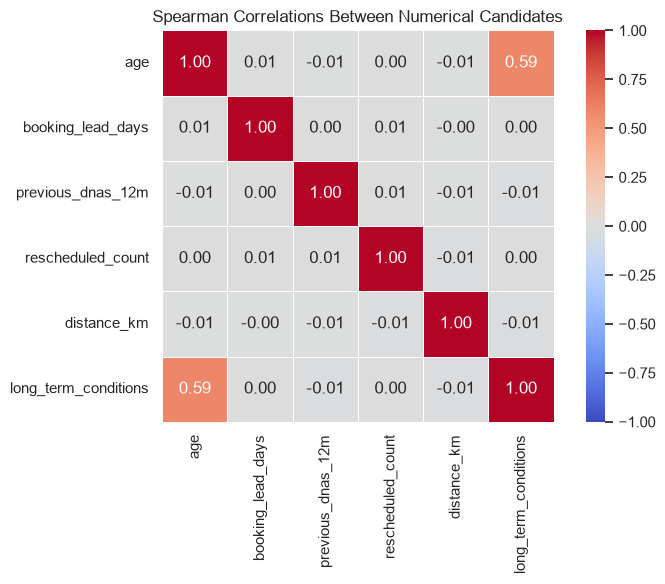


6. NUMERICAL FEATURES AND DNA TARGET


,feature,valid_appointments,spearman_with_dna,absolute_correlation
0,previous_dnas_12m,36264,0.1236,0.1236
1,booking_lead_days,36264,0.0557,0.0557
2,age,36216,-0.0415,0.0415
3,long_term_conditions,36264,-0.0362,0.0362
4,rescheduled_count,36264,0.0312,0.0312
5,distance_km,35902,0.0230,0.0230



A weak individual correlation does not necessarily mean a feature is useless for prediction.

7. CATEGORICAL FEATURE RELATIONSHIPS

Relationship: appointment_type versus consultation_mode


consultation_mode,Face-to-face,Telephone,Video
appointment_type,,,
Follow-up,18078,3561,900
New,10982,2147,596


Row percentages:


consultation_mode,Face-to-face,Telephone,Video
appointment_type,,,
Follow-up,80.21,15.80,3.99
New,80.01,15.64,4.34


... (15 outputs left out)

,feature,missing_count,missing_dna_rate_percent,observed_dna_rate_percent,rate_difference_pp,review_required
0,imd_decile,1265,8.30,9.15,-0.85,Verify missingness was observable at predictio...
1,distance_km,362,7.73,9.13,-1.40,Verify missingness was observable at predictio...
2,age,48,6.25,9.12,-2.87,Verify missingness was observable at predictio...



10. FEATURE AVAILABILITY AND LEAKAGE REVIEW


,feature,concern,action
0,previous_dnas_12m,Historical count may include attendance events...,Reconstruct using only completed appointments ...
1,rescheduled_count,Recorded count may include rescheduling events...,Verify event history and cutoff timing before ...
2,sms_reminder_sent,Reminder may have been sent after the predicti...,Exclude unless reminder timestamp confirms ear...
3,clinic_checkin_time,Check-in information occurs at or after appoin...,Exclude from predictive features.
4,distance_km,Distance may depend on information updated aft...,Verify source information was available at pre...
5,long_term_conditions,Recorded condition count may include later dia...,Use a historical snapshot or verify point-in-t...



11. KEY CELL 10 FINDINGS
Total eligible appointments: 36,264
Overall DNA rate: 9.12%
Features with missing values: 4
Numerical candidates reviewed: 6
Categorical relationships reviewed: 4
Strongest observed absolute numerical association with DNA: previous_dnas_12m (0.124)

Missingness patterns and predictor relationships may inform later feature engineering.
These are exploratory associations, not evidence of causation or model performance.
Historical features, reminders and other time-dependent values require leakage checks.
No missing values were imputed, no appointments were removed, and no models were trained.

CELL 10 COMPLETED SUCCESSFULLY
Ready for Cell 11: Feature suitability and leakage audit.


In [66]:

# MISSINGNESS AND FEATURE RELATIONSHIPS


# Objectives:
# 1. Review missing values across the modelling dataset.
# 2. Compare DNA rates for missing and observed values.
# 3. Examine relationships between numerical features.
# 4. Examine relationships between selected categorical features.
# 5. Identify potential feature engineering opportunities.
# 6. Document limitations and leakage risks.
# 7. Save descriptive tables and charts.

print("CELL 10: MISSINGNESS AND FEATURE RELATIONSHIPS")

# 1. Prepare a separate dataframe.
# Preserve the original modelling dataset.

df_rel = df_binary.copy()

assert len(df_rel) == 36264, (
    f"Unexpected modelling cohort size: {len(df_rel)}"
)

assert "dna_target" in df_rel.columns

assert df_rel["dna_target"].isin([0, 1]).all()

assert int(df_rel["dna_target"].sum()) == 3306

EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

overall_dna_rate = df_rel["dna_target"].mean() * 100

print(f"Eligible appointments: {len(df_rel):,}")
print(f"DNA appointments: {int(df_rel['dna_target'].sum()):,}")
print(f"Overall DNA rate: {overall_dna_rate:.2f}%")


# 2. Examine missing values in every column.


print("\n1. MISSING VALUE SUMMARY")

missing_summary = pd.DataFrame({
    "feature": df_rel.columns,
    "data_type": df_rel.dtypes.astype(str).values,
    "missing_count": df_rel.isna().sum().values,
    "unique_values": df_rel.nunique(dropna=True).values
})

missing_summary["missing_percent"] = (
    missing_summary["missing_count"]
    / len(df_rel) * 100
).round(2)

missing_summary = missing_summary.sort_values(
    ["missing_count", "feature"],
    ascending=[False, True]
).reset_index(drop=True)

display(missing_summary)

print(
    "Columns containing missing values:",
    int((missing_summary["missing_count"] > 0).sum())
)

print(
    "Total missing cells:",
    int(missing_summary["missing_count"].sum())
)

# Save the full missingness summary.

missing_summary.to_csv(
    EDA_REPORT_DIR / "cell10_missingness_summary.csv",
    index=False
)


# 3. Visualise missingness.
# Only features containing missing values are plotted.

print("\n2. MISSINGNESS CHART")

missing_plot = missing_summary.loc[
    missing_summary["missing_count"] > 0
].copy()

if not missing_plot.empty:

    missing_plot = missing_plot.sort_values(
        "missing_percent"
    )

    fig, ax = plt.subplots(
        figsize=(10, max(5, len(missing_plot) * 0.55))
    )

    bars = ax.barh(
        missing_plot["feature"],
        missing_plot["missing_percent"],
        color="#377eb8"
    )

    for bar, rate in zip(
        bars,
        missing_plot["missing_percent"]
    ):

        ax.annotate(
            f"{rate:.2f}%",
            (
                bar.get_width(),
                bar.get_y() + bar.get_height() / 2
            ),
            xytext=(5, 0),
            textcoords="offset points",
            va="center"
        )

    ax.set_title("Missing Values Across Modelling Features")
    ax.set_xlabel("Missing values (%)")
    ax.set_ylabel("Feature")

    ax.set_xlim(
        0,
        max(missing_plot["missing_percent"].max() * 1.3, 1)
    )

    plt.tight_layout()

    plt.savefig(
        EDA_REPORT_DIR / "cell10_missingness_chart.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

else:

    print("No missing values detected.")


# 4. Investigate whether missingness is associated
# with the target outcome.


#
# Exclude target, IDs, timestamps, outcome fields and
# post-appointment administrative fields from this comparison.

print("\n3. MISSINGNESS AND DNA OUTCOMES")

excluded_missingness_features = {
    "dna_target",
    "attendance_status",
    "appointment_id",
    "patient_id",
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime",
    "clinic_checkin_time"
}

missingness_results = []

for column in df_rel.columns:

    if column in excluded_missingness_features:
        continue

    missing_mask = df_rel[column].isna()

    missing_count = int(missing_mask.sum())
    observed_count = int((~missing_mask).sum())

    if missing_count == 0 or observed_count == 0:
        continue

    missing_dna_rate = (
        df_rel.loc[missing_mask, "dna_target"].mean() * 100
    )

    observed_dna_rate = (
        df_rel.loc[~missing_mask, "dna_target"].mean() * 100
    )

    missingness_results.append({
        "feature": column,
        "missing_count": missing_count,
        "observed_count": observed_count,
        "missing_dna_count": int(
            df_rel.loc[missing_mask, "dna_target"].sum()
        ),
        "observed_dna_count": int(
            df_rel.loc[~missing_mask, "dna_target"].sum()
        ),
        "missing_dna_rate_percent": round(
            missing_dna_rate, 2
        ),
        "observed_dna_rate_percent": round(
            observed_dna_rate, 2
        ),
        "rate_difference_pp": round(
            missing_dna_rate - observed_dna_rate, 2
        )
    })

missingness_dna_summary = pd.DataFrame(
    missingness_results,
    columns=[
        "feature",
        "missing_count",
        "observed_count",
        "missing_dna_count",
        "observed_dna_count",
        "missing_dna_rate_percent",
        "observed_dna_rate_percent",
        "rate_difference_pp"
    ]
)

if not missingness_dna_summary.empty:

    missingness_dna_summary = (
        missingness_dna_summary
        .sort_values(
            "missing_count",
            ascending=False
        )
        .reset_index(drop=True)
    )

    display(missingness_dna_summary)

else:

    print(
        "No eligible features have both missing "
        "and observed values."
    )

missingness_dna_summary.to_csv(
    EDA_REPORT_DIR / "cell10_missingness_vs_dna.csv",
    index=False
)

print(
    "\nDifferences in observed DNA rates do not prove "
    "that missingness causes missed appointments."
)


# 5. Review numerical predictor relationships.


print("\n4. NUMERICAL FEATURE RELATIONSHIPS")

numerical_candidates = [
    "age",
    "booking_lead_days",
    "previous_dnas_12m",
    "rescheduled_count",
    "distance_km",
    "long_term_conditions"
]

available_numerical = [
    column for column in numerical_candidates
    if column in df_rel.columns
]

print("Available numerical candidates:")
print(available_numerical)

numeric_data = pd.DataFrame(index=df_rel.index)

for column in available_numerical:

    numeric_data[column] = pd.to_numeric(
        df_rel[column],
        errors="coerce"
    )

numeric_quality = pd.DataFrame({
    "feature": available_numerical,
    "non_missing_count": [
        int(numeric_data[column].notna().sum())
        for column in available_numerical
    ],
    "missing_count": [
        int(numeric_data[column].isna().sum())
        for column in available_numerical
    ],
    "unique_values": [
        int(numeric_data[column].nunique(dropna=True))
        for column in available_numerical
    ]
})

display(numeric_quality)

numeric_quality.to_csv(
    EDA_REPORT_DIR / "cell10_numerical_feature_quality.csv",
    index=False
)


# 6. Calculate Spearman correlations.
# Spearman correlation captures monotonic relationships
# and is less sensitive to extreme values than Pearson.
#
# This is descriptive only.


print("\n5. SPEARMAN CORRELATION MATRIX")

usable_numerical = [
    column for column in available_numerical
    if numeric_data[column].nunique(dropna=True) > 1
]

if len(usable_numerical) >= 2:

    numeric_correlation = (
        numeric_data[usable_numerical]
        .corr(method="spearman")
    )

    display(numeric_correlation.round(3))

    fig, ax = plt.subplots(
        figsize=(
            max(8, len(usable_numerical) * 1.2),
            max(6, len(usable_numerical) * 1.0)
        )
    )

    sns.heatmap(
        numeric_correlation,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        linewidths=0.5,
        square=True,
        ax=ax
    )

    ax.set_title(
        "Spearman Correlations Between Numerical Candidates"
    )

    plt.tight_layout()

    plt.savefig(
        EDA_REPORT_DIR / "cell10_numerical_correlation_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    numeric_correlation.to_csv(
        EDA_REPORT_DIR / "cell10_numerical_correlations.csv"
    )

else:

    print(
        "Insufficient numerical features for a correlation matrix."
    )


# 7. Examine individual numerical associations with DNA.


print("\n6. NUMERICAL FEATURES AND DNA TARGET")

target_associations = []

for column in usable_numerical:

    valid = (
        numeric_data[column].notna()
        & df_rel["dna_target"].notna()
    )

    if valid.sum() < 3:
        continue

    correlation = numeric_data.loc[
        valid, column
    ].corr(
        df_rel.loc[valid, "dna_target"],
        method="spearman"
    )

    target_associations.append({
        "feature": column,
        "valid_appointments": int(valid.sum()),
        "spearman_with_dna": correlation,
        "absolute_correlation": abs(correlation)
    })

target_association_summary = pd.DataFrame(
    target_associations,
    columns=[
        "feature",
        "valid_appointments",
        "spearman_with_dna",
        "absolute_correlation"
    ]
)

if not target_association_summary.empty:

    target_association_summary = (
        target_association_summary
        .sort_values(
            "absolute_correlation",
            ascending=False
        )
        .reset_index(drop=True)
    )

    display(target_association_summary.round(4))

target_association_summary.to_csv(
    EDA_REPORT_DIR / "cell10_numerical_target_associations.csv",
    index=False
)

print(
    "\nA weak individual correlation does not necessarily "
    "mean a feature is useless for prediction."
)


# 8. Examine categorical feature relationships.


print("\n7. CATEGORICAL FEATURE RELATIONSHIPS")

categorical_pairs = [
    ("appointment_type", "consultation_mode"),
    ("appointment_type", "referral_source"),
    ("consultation_mode", "specialty"),
    ("sex", "interpreter_required")
]

categorical_relationship_tables = {}

for first_column, second_column in categorical_pairs:

    if (
        first_column not in df_rel.columns
        or second_column not in df_rel.columns
    ):

        print(
            f"Skipped unavailable pair: "
            f"{first_column} / {second_column}"
        )

        continue

    first_values = (
        df_rel[first_column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Missing")
    )

    second_values = (
        df_rel[second_column]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Missing")
    )

    counts = pd.crosstab(
        first_values,
        second_values,
        dropna=False
    )

    print(
        f"\nRelationship: {first_column} "
        f"versus {second_column}"
    )

    display(counts)

    row_percent = (
        counts.div(
            counts.sum(axis=1).replace(0, np.nan),
            axis=0
        ) * 100
    ).round(2)

    print("Row percentages:")
    display(row_percent)

    assert counts.to_numpy().sum() == len(df_rel)

    filename = (
        f"cell10_crosstab_"
        f"{first_column}_vs_{second_column}.csv"
    )

    counts.to_csv(EDA_REPORT_DIR / filename)

    categorical_relationship_tables[
        f"{first_column}_vs_{second_column}"
    ] = counts


# 9. Examine combined appointment characteristics.
# This checks descriptive differences across appointment
# types and consultation modes.


print("\n8. APPOINTMENT TYPE AND CONSULTATION MODE")

if all(
    column in df_rel.columns
    for column in ["appointment_type", "consultation_mode"]
):

    combined_service_summary = (
        df_rel.groupby(
            ["appointment_type", "consultation_mode"],
            dropna=False
        )["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    combined_service_summary["dna_rate_percent"] = (
        combined_service_summary["dna_rate"] * 100
    ).round(2)

    combined_service_summary["small_sample_flag"] = (
        combined_service_summary["appointments"] < 100
    )

    combined_service_summary = (
        combined_service_summary
        .drop(columns="dna_rate")
        .sort_values(
            ["appointment_type", "consultation_mode"]
        )
        .reset_index(drop=True)
    )

    display(combined_service_summary)

    assert (
        combined_service_summary["appointments"].sum()
        == 36264
    )

    assert (
        combined_service_summary["dna_count"].sum()
        == 3306
    )

    combined_service_summary.to_csv(
        EDA_REPORT_DIR / "cell10_service_feature_interactions.csv",
        index=False
    )

    print(
        "This is a relationship review. "
        "The detailed service analysis was completed in Cell 7."
    )


# 10. Review potential missingness indicators.
# These are candidates only, not engineered features.


print("\n9. POTENTIAL MISSINGNESS INDICATORS")

missing_indicator_candidates = (
    missingness_dna_summary[
        [
            "feature",
            "missing_count",
            "missing_dna_rate_percent",
            "observed_dna_rate_percent",
            "rate_difference_pp"
        ]
    ].copy()
)

if not missing_indicator_candidates.empty:

    missing_indicator_candidates["review_required"] = (
        "Verify missingness was observable at prediction cutoff"
    )

    display(missing_indicator_candidates)

else:

    print("No missingness indicators identified.")

missing_indicator_candidates.to_csv(
    EDA_REPORT_DIR / "cell10_missing_indicator_candidates.csv",
    index=False
)


# - At booking for appointments booked less than 7 days ahead.
# - Seven days before the appointment otherwise.
#
# Historical and administrative features require verification.

print("\n10. FEATURE AVAILABILITY AND LEAKAGE REVIEW")

feature_review = pd.DataFrame([
    {
        "feature": "previous_dnas_12m",
        "concern": (
            "Historical count may include attendance "
            "events occurring after prediction cutoff."
        ),
        "action": (
            "Reconstruct using only completed appointments "
            "before the cutoff, or exclude if unverifiable."
        )
    },
    {
        "feature": "rescheduled_count",
        "concern": (
            "Recorded count may include rescheduling "
            "events after the prediction cutoff."
        ),
        "action": (
            "Verify event history and cutoff timing "
            "before modelling."
        )
    },
    {
        "feature": "sms_reminder_sent",
        "concern": (
            "Reminder may have been sent after "
            "the prediction cutoff."
        ),
        "action": (
            "Exclude unless reminder timestamp "
            "confirms earlier availability."
        )
    },
    {
        "feature": "clinic_checkin_time",
        "concern": (
            "Check-in information occurs at or after "
            "appointment attendance."
        ),
        "action": (
            "Exclude from predictive features."
        )
    },
    {
        "feature": "distance_km",
        "concern": (
            "Distance may depend on information "
            "updated after booking."
        ),
        "action": (
            "Verify source information was available "
            "at prediction cutoff."
        )
    },
    {
        "feature": "long_term_conditions",
        "concern": (
            "Recorded condition count may include "
            "later diagnoses."
        ),
        "action": (
            "Use a historical snapshot or verify "
            "point-in-time availability."
        )
    }
])

display(feature_review)

feature_review.to_csv(
    EDA_REPORT_DIR / "cell10_feature_leakage_review.csv",
    index=False
)


# 12. Summarise findings and implications.

print("\n11. KEY CELL 10 FINDINGS")

print(
    f"Total eligible appointments: {len(df_rel):,}"
)

print(
    f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

print(
    "Features with missing values:",
    int((missing_summary["missing_count"] > 0).sum())
)

print(
    "Numerical candidates reviewed:",
    len(available_numerical)
)

print(
    "Categorical relationships reviewed:",
    len(categorical_relationship_tables)
)

if not target_association_summary.empty:

    highest_association = (
        target_association_summary.iloc[0]
    )

    print(
        "Strongest observed absolute numerical "
        "association with DNA:",
        highest_association["feature"],
        f"({highest_association['spearman_with_dna']:.3f})"
    )

print(
    "\nMissingness patterns and predictor relationships "
    "may inform later feature engineering."
)

print(
    "These are exploratory associations, not "
    "evidence of causation or model performance."
)

print(
    "Historical features, reminders and other "
    "time-dependent values require leakage checks."
)

print(
    "No missing values were imputed, no appointments "
    "were removed, and no models were trained."
)

print("\nCELL 10 COMPLETED SUCCESSFULLY")
print("Ready for Cell 11: Feature suitability and leakage audit.")


In [67]:

# FEATURE SUITABILITY AND DATA LEAKAGE AUDIT


# Objectives:
# 1. Validate prediction cutoffs.
# 2. Audit every original modelling column.
# 3. Identify outcome and temporal leakage risks.
# 4. Classify candidate, conditional and excluded features.
# 5. Review historical information and event timestamps.
# 6. Produce a provisional modelling feature policy.
# 7. Save reproducible audit reports.
#
# This cell does not train models, impute missing values,
# or permanently remove features.

print("CELL 11: FEATURE SUITABILITY AND DATA LEAKAGE AUDIT")

# 1. Prepare a separate audit dataframe.

df_audit = df_binary.copy()

EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = [
    "appointment_id",
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime",
    "booking_lead_days",
    "dna_target"
]

missing_required = [
    column for column in required_columns
    if column not in df_audit.columns
]

assert not missing_required, (
    f"Missing essential columns: {missing_required}"
)

assert len(df_audit) == 36264, (
    f"Unexpected cohort size: {len(df_audit)}"
)

assert df_audit["dna_target"].isin([0, 1]).all()

assert int(df_audit["dna_target"].sum()) == 3306

print(f"Appointments under review: {len(df_audit):,}")
print(f"Original dataset columns: {df_binary.shape[1]}")


# 2. Validate prediction cutoff timestamps.
#
# Short-notice appointments:
# Prediction occurs at booking.
#
# Long-notice appointments:
# Prediction occurs seven days before the appointment.
#
# Use actual timestamps rather than rounded lead-day
# values when independently reconstructing the cutoff.

print("\n1. PREDICTION CUTOFF VALIDATION")

for column in [
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime"
]:

    df_audit[column] = pd.to_datetime(
        df_audit[column],
        errors="coerce"
    )

    assert df_audit[column].notna().all(), (
        f"Invalid or missing timestamps in {column}"
    )

actual_lead_days = (
    (
        df_audit["appointment_datetime"]
        - df_audit["booked_datetime"]
    ).dt.total_seconds() / 86400
)

assert (actual_lead_days > 0).all(), (
    "Invalid booking chronology detected."
)

short_notice = actual_lead_days < 7
long_notice = ~short_notice

expected_cutoff = df_audit["booked_datetime"].copy()

expected_cutoff.loc[long_notice] = (
    df_audit.loc[long_notice, "appointment_datetime"]
    - pd.Timedelta(days=7)
)

cutoff_difference_seconds = (
    df_audit["prediction_cutoff_datetime"]
    - expected_cutoff
).dt.total_seconds().abs()

cutoff_valid = cutoff_difference_seconds <= 1

cutoff_summary = pd.DataFrame([
    {
        "prediction_group": "Short notice (<7 days)",
        "appointments": int(short_notice.sum()),
        "prediction_rule": "At booking",
        "valid_cutoffs": int(
            cutoff_valid.loc[short_notice].sum()
        ),
        "invalid_cutoffs": int(
            (~cutoff_valid.loc[short_notice]).sum()
        )
    },
    {
        "prediction_group": "Long notice (7+ days)",
        "appointments": int(long_notice.sum()),
        "prediction_rule": "7 days before appointment",
        "valid_cutoffs": int(
            cutoff_valid.loc[long_notice].sum()
        ),
        "invalid_cutoffs": int(
            (~cutoff_valid.loc[long_notice]).sum()
        )
    }
])

display(cutoff_summary)

assert cutoff_summary["appointments"].sum() == 36264

assert cutoff_valid.all(), (
    f"{int((~cutoff_valid).sum())} incorrect "
    "prediction cutoffs detected."
)

assert (
    df_audit["prediction_cutoff_datetime"]
    >= df_audit["booked_datetime"]
).all()

assert (
    df_audit["prediction_cutoff_datetime"]
    < df_audit["appointment_datetime"]
).all()

print("All prediction cutoffs validated successfully.")


# 3. Review prediction timing.
# These fields are calculated for audit purposes only.

print("\n2. PREDICTION TIMING SUMMARY")

df_audit["audit_days_before_appointment"] = (
    (
        df_audit["appointment_datetime"]
        - df_audit["prediction_cutoff_datetime"]
    ).dt.total_seconds() / 86400
)

df_audit["audit_days_since_booking"] = (
    (
        df_audit["prediction_cutoff_datetime"]
        - df_audit["booked_datetime"]
    ).dt.total_seconds() / 86400
)

df_audit["audit_notice_group"] = np.where(
    short_notice,
    "Short notice",
    "Long notice"
)

timing_summary = (
    df_audit.groupby("audit_notice_group")[
        [
            "audit_days_before_appointment",
            "audit_days_since_booking"
        ]
    ]
    .agg(["count", "min", "median", "max"])
    .round(3)
)

display(timing_summary)

# Compare the stored booking notice group with
# the classification derived from exact timestamps.

print("\n3. BOOKING NOTICE CONSISTENCY")

if "booking_notice_group" in df_audit.columns:

    print("Recorded booking notice categories:")

    display(
        df_audit["booking_notice_group"]
        .value_counts(dropna=False)
    )

    print(
        "The recorded categories should correspond "
        "to the short- and long-notice groups above."
    )

else:

    print("No stored booking_notice_group column found.")


# 4. Define feature classification rules.
#
# Exclude:
# Direct target, identifiers or unsafe information.
#
# Audit metadata:
# Useful for chronology and validation.
#
# Conditional:
# Requires historical or source-system verification.
#
# Candidate:
# Potentially available before appointment attendance,
# but still requires source confirmation.
#
# Unclassified:
# Must be reviewed before modelling.

print("\n4. FEATURE CLASSIFICATION RULES")

exclude_features = {
    "appointment_id": (
        "Appointment identifier; exclude as a predictor."
    ),
    "patient_id": (
        "Patient identifier; exclude as a direct predictor "
        "to reduce memorisation and identity leakage."
    ),
    "dna_target": (
        "Target outcome; never include as a predictor."
    ),
    "AttendanceStatus": (
        "Original attendance outcome."
    ),
    "attendance_status": (
        "Original attendance outcome."
    ),
    "clinic_checkin_time": (
        "Post-booking check-in information associated "
        "with appointment attendance."
    ),
    "sms_reminder_sent": (
        "Reminder timing is not verified against "
        "the prediction cutoff."
    )
}

audit_metadata_features = {
    "booked_datetime": (
        "Use for chronology, splitting and safe "
        "calendar feature derivation."
    ),
    "appointment_datetime": (
        "Use for chronology, splitting and safe "
        "calendar feature derivation."
    ),
    "prediction_cutoff_datetime": (
        "Reference timestamp for point-in-time validation."
    )
}

conditional_features = {
    "previous_dnas_12m": (
        "Historical attendance count requires proof "
        "that only information available before "
        "prediction cutoff was included."
    ),
    "rescheduled_count": (
        "Rescheduling count may include events "
        "after the prediction cutoff."
    ),
    "distance_km": (
        "Confirm patient address and clinic location "
        "were available at prediction time."
    ),
    "long_term_conditions": (
        "Confirm condition counts reflect diagnoses "
        "known at prediction time."
    ),
    "interpreter_required": (
        "Confirm interpreter requirements were recorded "
        "before the prediction cutoff."
    ),
    "imd_decile": (
        "Confirm postcode and deprivation mapping "
        "were available at prediction time."
    )
}

booking_candidate_features = {
    "age": (
        "Potentially suitable if age is calculated "
        "using information available at prediction time."
    ),
    "sex": (
        "Potentially available at booking; assess "
        "fairness and necessity before modelling."
    ),
    "ethnic_group": (
        "Retain for fairness assessment. Predictive use "
        "requires separate justification and governance review."
    ),
    "appointment_type": (
        "Usually established when an appointment "
        "is booked; verify cutoff-state accuracy."
    ),
    "consultation_mode": (
        "Usually scheduled before the appointment; "
        "verify no later changes are included."
    ),
    "specialty": (
        "Usually known at booking; verify source."
    ),
    "referral_source": (
        "Usually available from referral information; "
        "verify source."
    ),
    "booking_lead_days": (
        "Derived from booking and appointment dates; "
        "verify values reflect the original schedule."
    ),
    "booking_notice_group": (
        "Derived from booking lead time and known at "
        "the prediction cutoff, subject to source validation."
    ),
    "days_until_appointment_at_prediction": (
        "Derived from the scheduled appointment date "
        "and prediction cutoff."
    )
}


# 5. Classify every original modelling column.


print("\n5. COMPLETE COLUMN-BY-COLUMN AUDIT")

audit_rows = []

for column in df_binary.columns:

    if column in exclude_features:

        status = "Exclude"
        reason = exclude_features[column]

    elif column in audit_metadata_features:

        status = "Audit metadata"
        reason = audit_metadata_features[column]

    elif column in conditional_features:

        status = "Conditional - verification required"
        reason = conditional_features[column]

    elif column in booking_candidate_features:

        status = "Candidate - source confirmation required"
        reason = booking_candidate_features[column]

    else:

        status = "Unclassified - manual review required"
        reason = (
            "Not covered by the predefined audit rules. "
            "Do not use until reviewed."
        )

    audit_rows.append({
        "feature": column,
        "data_type": str(df_binary[column].dtype),
        "missing_count": int(
            df_binary[column].isna().sum()
        ),
        "missing_percent": round(
            df_binary[column].isna().mean() * 100,
            2
        ),
        "audit_status": status,
        "reason": reason
    })

feature_audit = pd.DataFrame(audit_rows)

display(feature_audit)

assert len(feature_audit) == df_binary.shape[1]

assert feature_audit["feature"].is_unique


# 6. Summarise feature classifications.

print("\n6. FEATURE AUDIT STATUS COUNTS")

audit_status_summary = (
    feature_audit["audit_status"]
    .value_counts()
    .rename_axis("audit_status")
    .reset_index(name="feature_count")
)

display(audit_status_summary)

unclassified_features = feature_audit.loc[
    feature_audit["audit_status"]
    == "Unclassified - manual review required",
    "feature"
].tolist()

print(
    "Unclassified features:",
    len(unclassified_features)
)

if unclassified_features:

    print("Features requiring manual review:")
    print(unclassified_features)

else:

    print("All original columns have an audit classification.")


# 7. Review event timestamp availability.


print("\n7. EVENT TIMESTAMP AVAILABILITY")

timestamp_requirements = {
    "sms_reminder_sent": [
        "sms_reminder_datetime",
        "sms_sent_datetime",
        "reminder_sent_datetime"
    ],
    "previous_dnas_12m": [
        "previous_dna_event_datetime",
        "historical_appointment_datetime"
    ],
    "rescheduled_count": [
        "rescheduled_datetime",
        "reschedule_event_datetime"
    ],
    "long_term_conditions": [
        "diagnosis_recorded_datetime",
        "condition_recorded_datetime"
    ],
    "interpreter_required": [
        "interpreter_recorded_datetime"
    ]
}

timestamp_audit_rows = []

for feature, possible_timestamps in (
    timestamp_requirements.items()
):

    available_timestamps = [
        column for column in possible_timestamps
        if column in df_audit.columns
    ]

    timestamp_audit_rows.append({
        "feature": feature,
        "possible_timestamp_columns": ", ".join(
            possible_timestamps
        ),
        "matching_timestamp_columns": (
            ", ".join(available_timestamps)
            if available_timestamps
            else "None found"
        ),
        "availability_verified": False,
        "reason": (
            "Source definitions, event histories or "
            "historical snapshots are required."
        )
    })

timestamp_audit = pd.DataFrame(
    timestamp_audit_rows
)

display(timestamp_audit)


# 8. Review high-risk historical and reminder features.

print("\n8. HISTORICAL FEATURE LEAKAGE REVIEW")

historical_review = pd.DataFrame([
    {
        "feature": "previous_dnas_12m",
        "potential_leakage": (
            "Count may include attendance outcomes "
            "recorded after prediction cutoff."
        ),
        "required_evidence": (
            "Historical appointment events and outcomes "
            "known before the prediction cutoff."
        ),
        "decision": "Do not use until verified"
    },
    {
        "feature": "rescheduled_count",
        "potential_leakage": (
            "Count may include rescheduling events "
            "after prediction cutoff."
        ),
        "required_evidence": (
            "Timestamped rescheduling history restricted "
            "to the cutoff."
        ),
        "decision": "Do not use until verified"
    },
    {
        "feature": "sms_reminder_sent",
        "potential_leakage": (
            "Reminder may have been sent after "
            "the prediction cutoff."
        ),
        "required_evidence": (
            "Reminder event timestamp and status "
            "as of prediction cutoff."
        ),
        "decision": "Exclude unless verified"
    }
])

display(historical_review)


# 9. Screen column names for outcome-related information.

print("\n9. OUTCOME-RELATED COLUMN SCREENING")

outcome_keywords = [
    "attendance",
    "attended",
    "checkin",
    "check_in",
    "outcome",
    "target",
    "cancelled",
    "cancellation",
    "dna"
]

outcome_name_matches = []

for column in df_binary.columns:

    if any(
        keyword in column.lower()
        for keyword in outcome_keywords
    ):

        matching_status = feature_audit.loc[
            feature_audit["feature"] == column,
            "audit_status"
        ].iloc[0]

        outcome_name_matches.append({
            "feature": column,
            "audit_status": matching_status,
            "manual_review_required": True
        })

outcome_name_audit = pd.DataFrame(
    outcome_name_matches,
    columns=[
        "feature",
        "audit_status",
        "manual_review_required"
    ]
)

display(outcome_name_audit)


# 10. Produce a provisional candidate shortlist.

print("\n10. PROVISIONAL FEATURE SHORTLIST")

candidate_statuses = [
    "Candidate - source confirmation required",
    "Conditional - verification required"
]

provisional_shortlist = feature_audit.loc[
    feature_audit["audit_status"].isin(
        candidate_statuses
    ),
    [
        "feature",
        "audit_status",
        "missing_count",
        "missing_percent",
        "reason"
    ]
].copy()

provisional_shortlist["approved_for_modelling"] = False

display(provisional_shortlist)


print("\n11. BASELINE MODELLING POLICY")

baseline_policy = pd.DataFrame([
    {
        "feature_group": "Appointment and booking information",
        "recommendation": (
            "Consider after confirming source values "
            "reflect the prediction cutoff."
        )
    },
    {
        "feature_group": "Patient characteristics",
        "recommendation": (
            "Assess availability, data quality, "
            "necessity and fairness."
        )
    },
    {
        "feature_group": "Historical attendance and rescheduling",
        "recommendation": (
            "Exclude until point-in-time historical "
            "values can be verified or reconstructed."
        )
    },
    {
        "feature_group": "SMS reminder status",
        "recommendation": (
            "Exclude unless reminder timing is verified."
        )
    },
    {
        "feature_group": "Identifiers and outcomes",
        "recommendation": (
            "Exclude from direct predictive inputs."
        )
    },
    {
        "feature_group": "Raw date and time columns",
        "recommendation": (
            "Use for chronological splitting and "
            "safe calendar feature derivation."
        )
    },
    {
        "feature_group": "Ethnic group and fairness attributes",
        "recommendation": (
            "Retain for fairness analysis; separately "
            "justify any predictive use."
        )
    }
])

display(baseline_policy)


# 12. Save all Cell 11 audit reports.

print("\n12. SAVE CELL 11 RESULTS")

cell11_tables = {
    "cell11_prediction_cutoff_audit.csv": cutoff_summary,
    "cell11_feature_suitability_audit.csv": feature_audit,
    "cell11_feature_status_counts.csv": audit_status_summary,
    "cell11_event_timestamp_audit.csv": timestamp_audit,
    "cell11_historical_leakage_review.csv": historical_review,
    "cell11_outcome_name_screening.csv": outcome_name_audit,
    "cell11_provisional_feature_shortlist.csv": provisional_shortlist,
    "cell11_baseline_modelling_policy.csv": baseline_policy
}

for filename, table in cell11_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")


# 13. Summarise the audit findings.

print("\n13. KEY CELL 11 FINDINGS")

print(f"Appointments audited: {len(df_audit):,}")

print(
    f"Valid prediction cutoffs: "
    f"{int(cutoff_valid.sum()):,} "
    f"of {len(cutoff_valid):,}"
)

print(
    "Dataset columns audited:",
    len(feature_audit)
)

print(
    "Provisional candidate features:",
    len(provisional_shortlist)
)

print(
    "Unclassified features:",
    len(unclassified_features)
)

print(
    "\nKey leakage risks:"
    "\n- Current appointment outcome information"
    "\n- Post-appointment check-in information"
    "\n- Unverified historical attendance counts"
    "\n- Unverified rescheduling history"
    "\n- SMS reminder status after prediction cutoff"
)

print(
    "\nEthnic group is retained for fairness "
    "assessment, not automatically approved "
    "for predictive modelling."
)

print(
    "Booking notice group is classified as a "
    "candidate feature, subject to source validation."
)

print(
    "No model features have been finally approved "
    "by this automated audit."
)

print(
    "No appointments were removed, no missing values "
    "were imputed, and no models were trained."
)

print("\nCELL 11 COMPLETED SUCCESSFULLY")
print("Ready for Cell 12: EDA summary and modelling implications.")


CELL 11: FEATURE SUITABILITY AND DATA LEAKAGE AUDIT
Appointments under review: 36,264
Original dataset columns: 25

1. PREDICTION CUTOFF VALIDATION


,prediction_group,appointments,prediction_rule,valid_cutoffs,invalid_cutoffs
0,Short notice (<7 days),2697,At booking,2697,0
1,Long notice (7+ days),33567,7 days before appointment,33567,0


All prediction cutoffs validated successfully.

2. PREDICTION TIMING SUMMARY


audit_days_before_appointment                      audit_days_since_booking                        
                                           count    min median    max                    count    min  median      max
audit_notice_group                                                                                                    
Long notice                                33567  7.000  7.000  7.000                    33567  0.002  32.286  293.275
Short notice                                2697  0.021  4.115  6.999                     2697  0.000   0.000    0.000


3. BOOKING NOTICE CONSISTENCY
Recorded booking notice categories:


booking_notice_group
Long notice (7+ days)     33567
Short notice (<7 days)     2697
Name: count, dtype: int64

... (11 outputs left out)

,feature,audit_status,missing_count,missing_percent,reason,approved_for_modelling
2,age,Candidate - source confirmation required,48,0.13,Potentially suitable if age is calculated usin...,False
3,sex,Candidate - source confirmation required,0,0.00,Potentially available at booking; assess fairn...,False
4,imd_decile,Conditional - verification required,1265,3.49,Confirm postcode and deprivation mapping were ...,False
5,ethnic_group,Candidate - source confirmation required,0,0.00,Retain for fairness assessment. Predictive use...,False
6,distance_km,Conditional - verification required,362,1.00,Confirm patient address and clinic location we...,False
7,interpreter_required,Conditional - verification required,0,0.00,Confirm interpreter requirements were recorded...,False
8,long_term_conditions,Conditional - verification required,0,0.00,Confirm condition counts reflect diagnoses kno...,False
9,specialty,Candidate - source confirmation required,0,0.00,Usually known at booking; verify source.,False
10,appointment_type,Candidate - source confirmation required,0,0.00,Usually established when an appointment is boo...,False
11,consultation_mode,Candidate - source confirmation required,0,0.00,Usually scheduled before the appointment; veri...,False



11. BASELINE MODELLING POLICY


,feature_group,recommendation
0,Appointment and booking information,Consider after confirming source values reflec...
1,Patient characteristics,"Assess availability, data quality, necessity a..."
2,Historical attendance and rescheduling,Exclude until point-in-time historical values ...
3,SMS reminder status,Exclude unless reminder timing is verified.
4,Identifiers and outcomes,Exclude from direct predictive inputs.
5,Raw date and time columns,Use for chronological splitting and safe calen...
6,Ethnic group and fairness attributes,Retain for fairness analysis; separately justi...



12. SAVE CELL 11 RESULTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_prediction_cutoff_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_feature_suitability_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_feature_status_counts.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_event_timestamp_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_historical_leakage_review.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_outcome_name_screening.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_provisional_feature_shortlist.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell11_baseline_modelling_policy.csv

13. KEY CELL 11 FINDINGS
Appointments 

In [68]:

# EDA SUMMARY AND MODELLING IMPLICATIONS


# Objectives:
# 1. Summarise the eligible modelling population.
# 2. Consolidate the main exploratory findings.
# 3. Identify potentially useful predictive signals.
# 4. Document missing-data implications.
# 5. Carry forward the feature leakage decisions.
# 6. Summarise fairness and intervention considerations.
# 7. Save tables and a written EDA summary.
#
# This cell does not train models or modify source data.

print("CELL 12: EDA SUMMARY AND MODELLING IMPLICATIONS")

# 1. Validate required data and previous audit results.

assert "df_binary" in globals(), (
    "Run Cell 1 before Cell 12."
)

assert "feature_audit" in globals(), (
    "Run Cell 11 before Cell 12."
)

df_summary = df_binary.copy()

EDA_REPORT_DIR.mkdir(parents=True, exist_ok=True)

required_columns = [
    "dna_target",
    "booking_lead_days",
    "age",
    "sex",
    "ethnic_group",
    "imd_decile",
    "specialty",
    "appointment_type",
    "consultation_mode",
    "previous_dnas_12m",
    "rescheduled_count",
    "distance_km"
]

missing_columns = [
    column for column in required_columns
    if column not in df_summary.columns
]

assert not missing_columns, (
    f"Required columns missing: {missing_columns}"
)

assert df_summary["dna_target"].isin([0, 1]).all()

assert (
    feature_audit["audit_status"]
    == "Unclassified - manual review required"
).sum() == 0

print("Dataset and feature audit validation passed.")


# 2. Overall population and DNA outcome.

print("\n1. OVERALL MODELLING POPULATION")

total_appointments = len(df_summary)

total_dnas = int(df_summary["dna_target"].sum())

total_attended = total_appointments - total_dnas

overall_dna_rate = (
    total_dnas / total_appointments * 100
)

population_summary = pd.DataFrame([
    {
        "metric": "Eligible appointments",
        "value": total_appointments
    },
    {
        "metric": "Attended appointments",
        "value": total_attended
    },
    {
        "metric": "Missed appointments (DNA)",
        "value": total_dnas
    },
    {
        "metric": "DNA rate (%)",
        "value": round(overall_dna_rate, 2)
    },
    {
        "metric": "Attendance rate (%)",
        "value": round(
            100 - overall_dna_rate, 2
        )
    }
])

display(population_summary)

print(
    f"Overall DNA rate: {overall_dna_rate:.2f}%"
)

print(
    "This is the observed outcome prevalence, "
    "not a predictive model performance score."
)


# 3. Reusable function for group-level DNA summaries.
# Small groups are identified because their estimates
# may be less stable.

def summarise_dna_by_group(
    dataframe,
    group_column,
    minimum_group_size=100
):
    """
    Calculate appointment counts, DNA counts and
    DNA percentages for each category.
    """

    grouped = (
        dataframe.groupby(
            group_column,
            dropna=False
        )["dna_target"]
        .agg(
            appointments="count",
            dna_count="sum",
            dna_rate="mean"
        )
        .reset_index()
    )

    grouped["dna_rate_percent"] = (
        grouped["dna_rate"] * 100
    ).round(2)

    grouped["difference_from_overall_pp"] = (
        grouped["dna_rate_percent"]
        - overall_dna_rate
    ).round(2)

    grouped["group_size_flag"] = np.where(
        grouped["appointments"] >= minimum_group_size,
        "100+ appointments",
        "Small group - interpret cautiously"
    )

    return grouped[
        [
            group_column,
            "appointments",
            "dna_count",
            "dna_rate_percent",
            "difference_from_overall_pp",
            "group_size_flag"
        ]
    ].sort_values(
        "dna_rate_percent",
        ascending=False
    ).reset_index(drop=True)


# 4. Booking notice and lead-time patterns.

print("\n2. BOOKING NOTICE AND LEAD-TIME PATTERNS")

# Derive groups independently using booking lead days.

df_summary["eda_notice_group"] = np.where(
    df_summary["booking_lead_days"] < 7,
    "Short notice (<7 days)",
    "Long notice (7+ days)"
)

notice_summary = summarise_dna_by_group(
    df_summary,
    "eda_notice_group"
)

display(notice_summary)

lead_time_summary = (
    df_summary.groupby("dna_target")[
        "booking_lead_days"
    ]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .reset_index()
)

lead_time_summary["outcome"] = (
    lead_time_summary["dna_target"]
    .map({0: "Attended", 1: "DNA"})
)

display(
    lead_time_summary[
        [
            "outcome",
            "count",
            "mean",
            "median",
            "min",
            "max"
        ]
    ]
)

print(
    "Interpretation: booking lead time may help "
    "identify differences in DNA risk. "
    "The relationship is observational."
)


# 5. Patient demographic patterns.

print("\n3. PATIENT CHARACTERISTICS")

# Age groups are created for descriptive analysis.


age_bins = [
    -np.inf, 17, 29, 44, 59, 74, np.inf
]

age_labels = [
    "Under 18",
    "18-29",
    "30-44",
    "45-59",
    "60-74",
    "75+"
]

df_summary["eda_age_group"] = pd.cut(
    df_summary["age"],
    bins=age_bins,
    labels=age_labels
)

demographic_columns = {
    "age_group": "eda_age_group",
    "sex": "sex",
    "ethnic_group": "ethnic_group",
    "imd_decile": "imd_decile"
}

demographic_summaries = {}

for label, column in demographic_columns.items():

    result = summarise_dna_by_group(
        df_summary,
        column
    )

    demographic_summaries[label] = result

    print(f"\nDNA by {label}:")
    display(result)

print(
    "\nFairness consideration: group-level differences "
    "should be investigated, but they do not by "
    "themselves establish discrimination or causation."
)


# 6. Clinical and appointment patterns.

print("\n4. APPOINTMENT AND CLINICAL CHARACTERISTICS")

appointment_columns = [
    "specialty",
    "appointment_type",
    "consultation_mode",
    "referral_source"
]

appointment_summaries = {}

for column in appointment_columns:

    if column not in df_summary.columns:
        continue

    result = summarise_dna_by_group(
        df_summary,
        column
    )

    appointment_summaries[column] = result

    print(f"\nDNA by {column}:")
    display(result)

print(
    "These variables may support prediction if "
    "their values are known at the prediction cutoff."
)


# 7. Historical DNA and rescheduling patterns.


print("\n5. HISTORICAL ATTENDANCE AND RESCHEDULING")

df_summary["eda_previous_dna_group"] = (
    pd.cut(
        df_summary["previous_dnas_12m"],
        bins=[-np.inf, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3+"]
    )
)

df_summary["eda_rescheduled_group"] = (
    pd.cut(
        df_summary["rescheduled_count"],
        bins=[-np.inf, 0, 1, 2, np.inf],
        labels=["0", "1", "2", "3+"]
    )
)

historical_dna_summary = summarise_dna_by_group(
    df_summary,
    "eda_previous_dna_group"
)

rescheduling_summary = summarise_dna_by_group(
    df_summary,
    "eda_rescheduled_group"
)

print("\nPrevious DNA history:")
display(historical_dna_summary)

print("\nRescheduling history:")
display(rescheduling_summary)

print(
    "\nLEAKAGE WARNING: These relationships do not "
    "establish that historical counts were available "
    "at the prediction cutoff."
)

print(
    "Do not use previous_dnas_12m or rescheduled_count "
    "in the initial model until their historical "
    "availability has been verified."
)


# 8. Summarise missing data.


print("\n6. MISSING DATA SUMMARY")

missing_summary = pd.DataFrame({
    "feature": df_binary.columns,
    "missing_count": [
        int(df_binary[col].isna().sum())
        for col in df_binary.columns
    ],
    "missing_percent": [
        round(
            df_binary[col].isna().mean() * 100,
            2
        )
        for col in df_binary.columns
    ]
})

missing_summary = (
    missing_summary[
        missing_summary["missing_count"] > 0
    ]
    .sort_values(
        "missing_count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(missing_summary)

print(
    "Recommended approach: fit imputers on "
    "training data only, and apply the fitted "
    "transformations to validation and test data."
)

print(
    "clinic_checkin_time must not be imputed "
    "or used as a predictive input."
)


# 9. Carry forward the Cell 11 feature audit.

print("\n7. FEATURE SUITABILITY SUMMARY")

feature_status_summary = (
    feature_audit["audit_status"]
    .value_counts()
    .rename_axis("audit_status")
    .reset_index(name="feature_count")
)

display(feature_status_summary)

restricted_features = [
    "previous_dnas_12m",
    "rescheduled_count",
    "sms_reminder_sent"
]

restricted_feature_summary = (
    feature_audit[
        feature_audit["feature"].isin(
            restricted_features
        )
    ][
        [
            "feature",
            "audit_status",
            "reason"
        ]
    ]
    .copy()
)

display(restricted_feature_summary)

print(
    "No feature is automatically approved "
    "for modelling based on its DNA association."
)


# 10. Identify potential modelling signals.
#
# The evidence below is descriptive and does not
# rank variables by predictive importance.

print("\n8. POTENTIAL MODELLING SIGNALS")

modelling_implications = pd.DataFrame([
    {
        "finding": "Booking lead time",
        "modelling_implication": (
            "Evaluate lead time and safe calendar "
            "features at the prediction cutoff."
        ),
        "caution": (
            "Check chronology and any appointment "
            "date changes."
        )
    },
    {
        "finding": "Previous DNA history",
        "modelling_implication": (
            "Potentially useful historical predictor."
        ),
        "caution": (
            "Exclude until point-in-time history "
            "is verified."
        )
    },
    {
        "finding": "Rescheduling history",
        "modelling_implication": (
            "May capture appointment instability."
        ),
        "caution": (
            "Exclude until event timestamps "
            "are verified."
        )
    },
    {
        "finding": "Appointment characteristics",
        "modelling_implication": (
            "Consider specialty, appointment type "
            "and consultation mode."
        ),
        "caution": (
            "Confirm recorded values existed "
            "at the cutoff."
        )
    },
    {
        "finding": "Patient characteristics",
        "modelling_implication": (
            "Evaluate age and appropriately "
            "justified patient variables."
        ),
        "caution": (
            "Assess missingness, fairness "
            "and necessity."
        )
    },
    {
        "finding": "Deprivation and travel distance",
        "modelling_implication": (
            "Investigate contextual access barriers."
        ),
        "caution": (
            "Verify source availability and "
            "avoid causal interpretations."
        )
    },
    {
        "finding": "SMS reminder status",
        "modelling_implication": (
            "May be relevant to intervention design."
        ),
        "caution": (
            "Exclude from modelling until "
            "reminder timing is verified."
        )
    }
])

display(modelling_implications)


# 11. Document fairness evaluation requirements.

print("\n9. FAIRNESS ASSESSMENT PLAN")

fairness_plan = pd.DataFrame([
    {
        "area": "Age",
        "evaluation": (
            "Compare subgroup sample sizes, DNA rates, "
            "recall and false-positive rates."
        )
    },
    {
        "area": "Sex",
        "evaluation": (
            "Compare predictive performance "
            "and intervention selection rates."
        )
    },
    {
        "area": "Ethnic group",
        "evaluation": (
            "Review performance differences, "
            "representation and selection rates."
        )
    },
    {
        "area": "Deprivation",
        "evaluation": (
            "Assess whether higher-deprivation "
            "groups receive appropriate support."
        )
    },
    {
        "area": "Missing or small groups",
        "evaluation": (
            "Report sample sizes and uncertainty; "
            "avoid strong claims from sparse groups."
        )
    }
])

display(fairness_plan)

print(
    "Fairness assessment will be performed "
    "on held-out predictions after model development."
)


# 12. Plan the weekly intervention.


print("\n10. WEEKLY 150-PATIENT INTERVENTION")

intervention_plan = pd.DataFrame([
    {
        "step": 1,
        "activity": "Identify eligible upcoming appointments",
        "requirement": (
            "Use appointments eligible at the "
            "weekly decision cutoff."
        )
    },
    {
        "step": 2,
        "activity": "Generate predicted DNA probabilities",
        "requirement": (
            "Use a validated, leakage-safe model."
        )
    },
    {
        "step": 3,
        "activity": "Select up to 150 appointments",
        "requirement": (
            "Rank eligible appointments while "
            "respecting operational and fairness rules."
        )
    },
    {
        "step": 4,
        "activity": "Estimate expected DNAs",
        "requirement": (
            "Sum calibrated predicted probabilities "
            "for the selected appointments."
        )
    },
    {
        "step": 5,
        "activity": "Estimate potentially prevented DNAs",
        "requirement": (
            "Apply an explicitly stated, evidence-based "
            "or scenario-based intervention effect."
        )
    },
    {
        "step": 6,
        "activity": "Evaluate real-world outcomes",
        "requirement": (
            "Compare outcomes using an appropriate "
            "pilot or controlled evaluation."
        )
    }
])

display(intervention_plan)

print(
    "The number of predicted DNAs is not the "
    "same as the number of DNAs prevented."
)

print(
    "Intervention benefit requires an assumption "
    "or measured estimate of call effectiveness."
)


# 13. Define next-stage modelling requirements.

print("\n11. FEATURE ENGINEERING AND MODELLING PLAN")

next_stage_plan = pd.DataFrame([
    {
        "stage": "Feature availability",
        "action": (
            "Confirm the cutoff-state values of "
            "candidate predictors."
        )
    },
    {
        "stage": "Feature engineering",
        "action": (
            "Develop safe timing and appointment "
            "features without future information."
        )
    },
    {
        "stage": "Chronological split",
        "action": (
            "Use time-ordered training, validation "
            "and test periods."
        )
    },
    {
        "stage": "Preprocessing",
        "action": (
            "Fit imputation and encoding using "
            "training data only."
        )
    },
    {
        "stage": "Baseline model",
        "action": (
            "Train a simple interpretable "
            "classification baseline."
        )
    },
    {
        "stage": "Model comparison",
        "action": (
            "Compare candidate models using "
            "the same held-out evaluation design."
        )
    },
    {
        "stage": "Evaluation",
        "action": (
            "Assess PR-AUC, ROC-AUC, recall, "
            "precision, calibration and top-150 utility."
        )
    },
    {
        "stage": "Fairness",
        "action": (
            "Compare subgroup performance "
            "and intervention selection."
        )
    },
    {
        "stage": "Operational impact",
        "action": (
            "Estimate weekly workload and "
            "potentially prevented DNAs."
        )
    }
])

display(next_stage_plan)


# 14. Save structured EDA summary tables.

print("\n12. SAVE CELL 12 REPORTS")

cell12_tables = {
    "cell12_population_summary.csv": population_summary,
    "cell12_booking_notice_summary.csv": notice_summary,
    "cell12_lead_time_summary.csv": lead_time_summary,
    "cell12_previous_dna_summary.csv": historical_dna_summary,
    "cell12_rescheduling_summary.csv": rescheduling_summary,
    "cell12_missing_data_summary.csv": missing_summary,
    "cell12_feature_status_summary.csv": feature_status_summary,
    "cell12_restricted_features.csv": restricted_feature_summary,
    "cell12_modelling_implications.csv": modelling_implications,
    "cell12_fairness_plan.csv": fairness_plan,
    "cell12_intervention_plan.csv": intervention_plan,
    "cell12_next_stage_plan.csv": next_stage_plan
}

for name, table in demographic_summaries.items():

    cell12_tables[
        f"cell12_demographic_{name}.csv"
    ] = table

for name, table in appointment_summaries.items():

    cell12_tables[
        f"cell12_appointment_{name}.csv"
    ] = table

for filename, table in cell12_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")


# 15. Generate a concise written EDA report.
# All numerical values come from the dataset.

print("\n13. GENERATE WRITTEN EDA SUMMARY")

short_rate = notice_summary.loc[
    notice_summary["eda_notice_group"]
    == "Short notice (<7 days)",
    "dna_rate_percent"
].iloc[0]

long_rate = notice_summary.loc[
    notice_summary["eda_notice_group"]
    == "Long notice (7+ days)",
    "dna_rate_percent"
].iloc[0]

written_summary = f"""
NHS DORSET - OUTPATIENT DNA PREDICTION
EXPLORATORY DATA ANALYSIS SUMMARY

1. OBJECTIVE
Explore outpatient attendance patterns and identify
potentially useful, leakage-safe predictors of missed
appointments (DNA).

2. MODELLING POPULATION
Eligible appointments: {total_appointments:,}
Attended: {total_attended:,}
DNA: {total_dnas:,}
Overall DNA rate: {overall_dna_rate:.2f}%

3. BOOKING PATTERNS
Short-notice DNA rate: {short_rate:.2f}%
Long-notice DNA rate: {long_rate:.2f}%

These are observational differences, not evidence
that booking lead time causes missed appointments.

4. PATIENT AND APPOINTMENT CHARACTERISTICS
Exploratory analysis examined age, sex, ethnic group,
deprivation, specialty, appointment type, consultation
mode, referral source, and other recorded variables.

Group differences should be interpreted alongside
sample sizes and data-quality limitations.

5. HISTORICAL ATTENDANCE
Previous DNA history and rescheduling were examined.
Their use in prediction remains restricted until
historical values can be verified at the cutoff.

6. MISSING DATA
Missingness was identified in age, deprivation,
distance and clinic check-in information.
Preprocessing must be fitted using training data only.
Clinic check-in information is excluded.

7. DATA LEAKAGE
Prediction timing was validated in Cell 11.
Identifiers, outcome fields and post-outcome
information must not be used as predictors.

8. FAIRNESS
Evaluate model performance and selection rates
across relevant patient groups, including age,
sex, ethnic group and deprivation.
Small groups require cautious interpretation.

9. MODEL DEVELOPMENT
Use chronological evaluation, leakage-safe feature
engineering, training-only preprocessing, and
appropriate classification and calibration metrics.

10. WEEKLY INTERVENTION
The operational goal is to identify up to 150
patients per week for additional contact.
Estimated prevented DNAs require a justified
intervention-effect assumption or pilot evidence.

CONCLUSION
EDA has identified potentially useful associations
and documented data-quality and leakage risks.
No causal effects or predictive performance claims
can be established from EDA alone.
"""

report_path = (
    EDA_REPORT_DIR
    / "cell12_eda_written_summary.txt"
)

report_path.write_text(
    written_summary,
    encoding="utf-8"
)

print(written_summary)

print(f"Saved written report: {report_path}")


# 16. Final validation.

print("\n14. FINAL CELL 12 CHECKS")

assert (
    total_attended + total_dnas
    == total_appointments
)

assert 0 <= overall_dna_rate <= 100

assert (
    notice_summary["appointments"].sum()
    == total_appointments
)

assert len(feature_audit) == df_binary.shape[1]

assert len(unclassified_features) == 0

assert report_path.exists()

print(f"Appointments reviewed: {total_appointments:,}")
print(f"DNA rate: {overall_dna_rate:.2f}%")
print(f"Unclassified features: {len(unclassified_features)}")
print(f"Structured reports saved: {len(cell12_tables)}")
print("Written EDA summary saved successfully.")

print(
    "\nNo modelling data was modified, "
    "no imputations were performed, "
    "and no models were trained."
)

print("\nCELL 12 COMPLETED SUCCESSFULLY")
print("Ready for Cell 13: Final EDA validation and handover.")


CELL 12: EDA SUMMARY AND MODELLING IMPLICATIONS
Dataset and feature audit validation passed.

1. OVERALL MODELLING POPULATION


,metric,value
0,Eligible appointments,36264.00
1,Attended appointments,32958.00
2,Missed appointments (DNA),3306.00
3,DNA rate (%),9.12
4,Attendance rate (%),90.88


Overall DNA rate: 9.12%
This is the observed outcome prevalence, not a predictive model performance score.

2. BOOKING NOTICE AND LEAD-TIME PATTERNS


,eda_notice_group,appointments,dna_count,dna_rate_percent,difference_from_overall_pp,group_size_flag
0,Long notice (7+ days),33567,3111,9.27,0.15,100+ appointments
1,Short notice (<7 days),2697,195,7.23,-1.89,100+ appointments


,outcome,count,mean,median,min,max
0,Attended,32958,45.21,35.89,0.02,299.79
1,DNA,3306,53.88,42.84,0.15,300.27


Interpretation: booking lead time may help identify differences in DNA risk. The relationship is observational.

3. PATIENT CHARACTERISTICS

DNA by age_group:


... (29 outputs left out)

,step,activity,requirement
0,1,Identify eligible upcoming appointments,Use appointments eligible at the weekly decisi...
1,2,Generate predicted DNA probabilities,"Use a validated, leakage-safe model."
2,3,Select up to 150 appointments,Rank eligible appointments while respecting op...
3,4,Estimate expected DNAs,Sum calibrated predicted probabilities for the...
4,5,Estimate potentially prevented DNAs,"Apply an explicitly stated, evidence-based or ..."
5,6,Evaluate real-world outcomes,Compare outcomes using an appropriate pilot or...


The number of predicted DNAs is not the same as the number of DNAs prevented.
Intervention benefit requires an assumption or measured estimate of call effectiveness.

11. FEATURE ENGINEERING AND MODELLING PLAN


,stage,action
0,Feature availability,Confirm the cutoff-state values of candidate p...
1,Feature engineering,Develop safe timing and appointment features w...
2,Chronological split,"Use time-ordered training, validation and test..."
3,Preprocessing,Fit imputation and encoding using training dat...
4,Baseline model,Train a simple interpretable classification ba...
5,Model comparison,Compare candidate models using the same held-o...
6,Evaluation,"Assess PR-AUC, ROC-AUC, recall, precision, cal..."
7,Fairness,Compare subgroup performance and intervention ...
8,Operational impact,Estimate weekly workload and potentially preve...



12. SAVE CELL 12 REPORTS
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_population_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_booking_notice_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_lead_time_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_previous_dna_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_rescheduling_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_missing_data_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_feature_status_summary.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell12_restricted_features.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\rep

In [69]:

# FINAL EDA VALIDATION AND HANDOVER


# Objectives:
# 1. Validate the final EDA modelling population.
# 2. Check outcome labels and appointment identifiers.
# 3. Confirm prediction cutoff consistency.
# 4. Reconcile missing-data findings.
# 5. Verify feature classification and leakage restrictions.
# 6. Check EDA report availability.
# 7. Prepare a feature engineering handover.
# 8. Save a final validation report.
#
# No model training, imputation or row removal occurs.

print("FINAL EDA VALIDATION AND HANDOVER")


# 1. Confirm that previous notebook stages are available.

print("\n1. VERIFY NOTEBOOK DEPENDENCIES")

required_objects = [
    "df_binary",
    "df_eda",
    "feature_audit",
    "population_summary",
    "EDA_REPORT_DIR"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Missing notebook objects: {missing_objects}. "
    "Run the preceding EDA cells first."
)

df_final = df_binary.copy()

EDA_REPORT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Required EDA objects are available.")
print(f"Final modelling rows: {len(df_final):,}")
print(f"Final modelling columns: {df_final.shape[1]}")


# 2. Create a reusable validation register.
# Every check will be documented in the final report.

validation_records = []

def record_validation(
    check_name,
    passed,
    details,
    critical=True
):
    """
    Record the result of an EDA validation check.
    """

    validation_records.append({
        "check": check_name,
        "status": "PASS" if passed else "FAIL",
        "critical": critical,
        "details": str(details)
    })

    print(
        f"{'PASS' if passed else 'FAIL'}: "
        f"{check_name}"
    )


# 3. Validate the modelling population.

print("\n2. MODELLING POPULATION VALIDATION")

expected_rows = 36264
expected_dnas = 3306
expected_attended = 32958

actual_rows = len(df_final)

actual_dnas = int(
    df_final["dna_target"].sum()
)

actual_attended = (
    actual_rows - actual_dnas
)

record_validation(
    "Expected modelling population",
    actual_rows == expected_rows,
    f"Observed {actual_rows:,}; expected {expected_rows:,}"
)

record_validation(
    "Expected DNA count",
    actual_dnas == expected_dnas,
    f"Observed {actual_dnas:,}; expected {expected_dnas:,}"
)

record_validation(
    "Expected attended count",
    actual_attended == expected_attended,
    (
        f"Observed {actual_attended:,}; "
        f"expected {expected_attended:,}"
    )
)

valid_target = (
    df_final["dna_target"].notna().all()
    and df_final["dna_target"].isin([0, 1]).all()
)

record_validation(
    "Binary target validity",
    valid_target,
    "Target must contain only 0 and 1."
)

dna_rate = actual_dnas / actual_rows * 100

print(f"\nFinal DNA rate: {dna_rate:.2f}%")


# 4. Validate appointment identifiers and outcomes.

print("\n3. APPOINTMENT AND OUTCOME CHECKS")

missing_appointment_ids = int(
    df_final["appointment_id"].isna().sum()
)

duplicate_appointment_ids = int(
    df_final["appointment_id"].duplicated().sum()
)

record_validation(
    "No missing appointment identifiers",
    missing_appointment_ids == 0,
    f"Missing identifiers: {missing_appointment_ids}"
)

record_validation(
    "Unique appointment identifiers",
    duplicate_appointment_ids == 0,
    (
        f"Duplicate appointment identifiers: "
        f"{duplicate_appointment_ids}"
    )
)

if "attendance_status" in df_final.columns:

    attendance_values = (
        df_final["attendance_status"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    valid_attendance = attendance_values.isin(
        ["attended", "dna"]
    ).all()

    label_consistency = (
        (
            (attendance_values == "dna").astype(int)
            == df_final["dna_target"]
        ).all()
    )

    record_validation(
        "Only Attended and DNA outcomes",
        valid_attendance,
        "Cancellations must not be in the binary cohort."
    )

    record_validation(
        "Outcome and target agreement",
        label_consistency,
        "dna_target must match attendance_status."
    )


# 5. Validate prediction chronology.
# Reconstruct the cutoff from the actual timestamps.

print("\n4. PREDICTION CHRONOLOGY VALIDATION")

datetime_columns = [
    "booked_datetime",
    "appointment_datetime",
    "prediction_cutoff_datetime"
]

for column in datetime_columns:

    df_final[column] = pd.to_datetime(
        df_final[column],
        errors="coerce"
    )

valid_datetimes = all(
    df_final[column].notna().all()
    for column in datetime_columns
)

record_validation(
    "Required datetime completeness",
    valid_datetimes,
    "Booking, appointment and cutoff dates must exist."
)

if valid_datetimes:

    lead_days_exact = (
        (
            df_final["appointment_datetime"]
            - df_final["booked_datetime"]
        ).dt.total_seconds() / 86400
    )

    short_notice_mask = lead_days_exact < 7

    expected_cutoff = (
        df_final["booked_datetime"].copy()
    )

    expected_cutoff.loc[~short_notice_mask] = (
        df_final.loc[
            ~short_notice_mask,
            "appointment_datetime"
        ]
        - pd.Timedelta(days=7)
    )

    cutoff_difference = (
        df_final["prediction_cutoff_datetime"]
        - expected_cutoff
    ).dt.total_seconds().abs()

    correct_cutoffs = (
        cutoff_difference <= 1
    ).all()

    valid_chronology = (
        (lead_days_exact > 0).all()
        and (
            df_final["prediction_cutoff_datetime"]
            >= df_final["booked_datetime"]
        ).all()
        and (
            df_final["prediction_cutoff_datetime"]
            < df_final["appointment_datetime"]
        ).all()
    )

    record_validation(
        "Prediction cutoff accuracy",
        correct_cutoffs,
        (
            "Short notice: at booking; "
            "long notice: seven days before appointment."
        )
    )

    record_validation(
        "Valid booking and prediction chronology",
        valid_chronology,
        "Booking <= cutoff < appointment."
    )

    short_count = int(short_notice_mask.sum())
    long_count = int((~short_notice_mask).sum())

    print(f"Short-notice appointments: {short_count:,}")
    print(f"Long-notice appointments: {long_count:,}")

else:

    record_validation(
        "Prediction cutoff accuracy",
        False,
        "Cannot validate because timestamps are missing."
    )

    record_validation(
        "Valid booking and prediction chronology",
        False,
        "Cannot validate because timestamps are missing."
    )


# 6. Reconcile missing-data findings.

print("\n5. FINAL MISSING-DATA VALIDATION")

final_missingness = pd.DataFrame({
    "feature": df_final.columns,
    "missing_count": [
        int(df_final[col].isna().sum())
        for col in df_final.columns
    ],
    "missing_percent": [
        round(
            df_final[col].isna().mean() * 100,
            2
        )
        for col in df_final.columns
    ]
})

final_missingness = (
    final_missingness[
        final_missingness["missing_count"] > 0
    ]
    .sort_values(
        "missing_count",
        ascending=False
    )
    .reset_index(drop=True)
)

display(final_missingness)

expected_missingness = {
    "clinic_checkin_time": 36264,
    "imd_decile": 1265,
    "distance_km": 362,
    "age": 48
}

for column, expected_count in (
    expected_missingness.items()
):

    if column in df_final.columns:

        actual_count = int(
            df_final[column].isna().sum()
        )

        record_validation(
            f"Missingness reconciliation: {column}",
            actual_count == expected_count,
            (
                f"Observed {actual_count:,}; "
                f"expected {expected_count:,}"
            )
        )

    else:

        record_validation(
            f"Missingness reconciliation: {column}",
            False,
            "Expected column not found."
        )


# 7. Verify feature classification completeness.

print("\n6. FEATURE SUITABILITY VALIDATION")

audited_columns = set(
    feature_audit["feature"]
)

dataset_columns = set(
    df_binary.columns
)

all_columns_audited = (
    audited_columns == dataset_columns
    and len(feature_audit) == len(df_binary.columns)
)

record_validation(
    "Every modelling column audited",
    all_columns_audited,
    (
        f"Dataset columns: {len(dataset_columns)}; "
        f"audited columns: {len(audited_columns)}"
    )
)

unclassified_count = int(
    (
        feature_audit["audit_status"]
        == "Unclassified - manual review required"
    ).sum()
)

record_validation(
    "No unclassified features",
    unclassified_count == 0,
    f"Unclassified features: {unclassified_count}"
)

display(
    feature_audit[
        [
            "feature",
            "audit_status",
            "reason"
        ]
    ]
)


# 8. Verify essential leakage restrictions.


print("\n7. LEAKAGE RESTRICTION VALIDATION")

required_restrictions = {
    "appointment_id": "Exclude",
    "patient_id": "Exclude",
    "dna_target": "Exclude",
    "attendance_status": "Exclude",
    "clinic_checkin_time": "Exclude",
    "sms_reminder_sent": "Exclude",
    "previous_dnas_12m": (
        "Conditional - verification required"
    ),
    "rescheduled_count": (
        "Conditional - verification required"
    )
}

leakage_rows = []

for feature, expected_status in (
    required_restrictions.items()
):

    matching = feature_audit.loc[
        feature_audit["feature"] == feature,
        "audit_status"
    ]

    actual_status = (
        matching.iloc[0]
        if not matching.empty
        else "NOT FOUND"
    )

    matches_policy = (
        actual_status == expected_status
    )

    leakage_rows.append({
        "feature": feature,
        "expected_status": expected_status,
        "actual_status": actual_status,
        "policy_check": (
            "PASS" if matches_policy else "FAIL"
        )
    })

leakage_policy_audit = pd.DataFrame(
    leakage_rows
)

display(leakage_policy_audit)

record_validation(
    "Leakage restriction policy",
    (
        leakage_policy_audit["policy_check"]
        == "PASS"
    ).all(),
    "Required exclusions and conditional restrictions."
)


# 9. Verify expected reports from previous EDA cells.


print("\n8. EDA REPORT FILE VERIFICATION")

required_report_files = [
    "cell11_prediction_cutoff_audit.csv",
    "cell11_feature_suitability_audit.csv",
    "cell11_historical_leakage_review.csv",
    "cell12_population_summary.csv",
    "cell12_missing_data_summary.csv",
    "cell12_modelling_implications.csv",
    "cell12_fairness_plan.csv",
    "cell12_intervention_plan.csv",
    "cell12_eda_written_summary.txt"
]

report_file_rows = []

for filename in required_report_files:

    file_path = EDA_REPORT_DIR / filename

    report_file_rows.append({
        "report": filename,
        "exists": file_path.is_file(),
        "path": str(file_path)
    })

report_file_audit = pd.DataFrame(
    report_file_rows
)

display(report_file_audit)

record_validation(
    "Required EDA reports available",
    report_file_audit["exists"].all(),
    (
        f"Available: "
        f"{int(report_file_audit['exists'].sum())}"
        f"/{len(report_file_audit)}"
    ),
    critical=False
)


# 10. Document feature engineering decisions.


print("\n9. FEATURE ENGINEERING HANDOVER")

feature_handover = pd.DataFrame([
    {
        "area": "Prediction timing",
        "decision": (
            "Use booking time for short notice and "
            "seven days before appointment otherwise."
        ),
        "next_action": (
            "Apply the same cutoff consistently "
            "during feature construction."
        )
    },
    {
        "area": "Booking features",
        "decision": (
            "Appointment characteristics and booking "
            "lead time are provisional candidates."
        ),
        "next_action": (
            "Verify source values reflect "
            "the prediction cutoff."
        )
    },
    {
        "area": "Historical DNA counts",
        "decision": (
            "Potentially useful but not verified "
            "as point-in-time safe."
        ),
        "next_action": (
            "Reconstruct from historical events "
            "or exclude."
        )
    },
    {
        "area": "Rescheduling history",
        "decision": (
            "Potentially useful but may include "
            "future events."
        ),
        "next_action": (
            "Verify event timestamps or exclude."
        )
    },
    {
        "area": "SMS reminder status",
        "decision": (
            "Excluded from the initial model."
        ),
        "next_action": (
            "Use only if reminder timing can "
            "be verified against the cutoff."
        )
    },
    {
        "area": "Missing values",
        "decision": (
            "Retain eligible appointments with "
            "missing age, IMD or distance."
        ),
        "next_action": (
            "Fit imputers on training data only."
        )
    },
    {
        "area": "Identifiers",
        "decision": (
            "Appointment and patient identifiers "
            "are not predictive inputs."
        ),
        "next_action": (
            "Retain identifiers separately for "
            "tracking and evaluation."
        )
    },
    {
        "area": "Sensitive attributes",
        "decision": (
            "Retain appropriate attributes "
            "for fairness assessment."
        ),
        "next_action": (
            "Justify any predictive use separately."
        )
    },
    {
        "area": "Data splitting",
        "decision": (
            "Use a chronological evaluation design."
        ),
        "next_action": (
            "Choose split boundaries and account "
            "for outcome availability and repeated patients."
        )
    },
    {
        "area": "Weekly intervention",
        "decision": (
            "Identify up to 150 eligible appointments "
            "for patient contact."
        ),
        "next_action": (
            "Evaluate calibrated top-150 risk, "
            "capacity, fairness and intervention effect."
        )
    }
])

display(feature_handover)


# 11. Document important data quality decisions.
# These decisions originate from the earlier
# cleaning and eligibility stages.

print("\n10. DATA QUALITY DECISION HANDOVER")

data_quality_handover = pd.DataFrame([
    {
        "issue": "Exact duplicate rows",
        "decision": (
            "180 exact duplicates removed "
            "during data cleaning."
        )
    },
    {
        "issue": "Invalid age values",
        "decision": (
            "Invalid ages converted to missing "
            "rather than deleting appointments."
        )
    },
    {
        "issue": "Inconsistent categories",
        "decision": (
            "Sex and specialty categories "
            "standardised."
        )
    },
    {
        "issue": "Cancelled appointments",
        "decision": (
            "Excluded from the binary "
            "Attended versus DNA cohort."
        )
    },
    {
        "issue": "Invalid booking chronology",
        "decision": (
            "Excluded from the binary modelling "
            "cohort after eligibility checks."
        )
    },
    {
        "issue": "Missing age, IMD and distance",
        "decision": (
            "Retained for later training-only "
            "preprocessing."
        )
    },
    {
        "issue": "Clinic check-in information",
        "decision": (
            "Excluded from predictive inputs "
            "because of outcome leakage risk."
        )
    }
])

display(data_quality_handover)


# 12. Prepare the final modelling readiness checklist.

print("\n11. MODELLING READINESS CHECKLIST")

readiness_checklist = pd.DataFrame([
    {
        "requirement": "Cleaned binary modelling cohort",
        "status": "Ready",
        "next_step": "Use the saved eligible cohort."
    },
    {
        "requirement": "Exploratory analysis",
        "status": "Ready",
        "next_step": "Reference EDA reports."
    },
    {
        "requirement": "Prediction cutoff validation",
        "status": (
            "Ready"
            if valid_datetimes and correct_cutoffs
            else "Review required"
        ),
        "next_step": "Preserve the validated timing rule."
    },
    {
        "requirement": "Feature classification",
        "status": (
            "Ready"
            if unclassified_count == 0
            else "Review required"
        ),
        "next_step": "Resolve source availability."
    },
    {
        "requirement": "Historical feature verification",
        "status": "Pending",
        "next_step": (
            "Exclude or reconstruct historical "
            "features as of prediction time."
        )
    },
    {
        "requirement": "Final predictive feature selection",
        "status": "Pending",
        "next_step": (
            "Confirm cutoff-state availability "
            "and fairness considerations."
        )
    },
    {
        "requirement": "Chronological train/test design",
        "status": "Pending",
        "next_step": (
            "Define temporal boundaries and "
            "prevent future information leakage."
        )
    },
    {
        "requirement": "Model development",
        "status": "Pending",
        "next_step": (
            "Build and compare candidate models."
        )
    },
    {
        "requirement": "Fairness evaluation",
        "status": "Pending",
        "next_step": (
            "Evaluate held-out subgroup performance."
        )
    },
    {
        "requirement": "Weekly 150-patient intervention",
        "status": "Pending",
        "next_step": (
            "Evaluate calibrated risk ranking "
            "and potential intervention benefit."
        )
    }
])

display(readiness_checklist)


# 13. Save final audit and handover files.

print("\n12. SAVE FINAL EDA HANDOVER FILES")

validation_report = pd.DataFrame(
    validation_records
)

cell13_tables = {
    "cell13_validation_report.csv": validation_report,
    "cell13_final_missingness.csv": final_missingness,
    "cell13_leakage_policy_audit.csv": leakage_policy_audit,
    "cell13_report_file_audit.csv": report_file_audit,
    "cell13_feature_handover.csv": feature_handover,
    "cell13_data_quality_handover.csv": data_quality_handover,
    "cell13_modelling_readiness.csv": readiness_checklist
}

for filename, table in cell13_tables.items():

    output_path = EDA_REPORT_DIR / filename

    table.to_csv(
        output_path,
        index=False
    )

    print(f"Saved: {output_path}")


# 14. Create a readable handover summary.

print("\n13. GENERATE FINAL EDA HANDOVER SUMMARY")

critical_failures = validation_report.loc[
    (validation_report["status"] == "FAIL")
    & (validation_report["critical"])
]

noncritical_failures = validation_report.loc[
    (validation_report["status"] == "FAIL")
    & (~validation_report["critical"])
]

handover_text = f"""
NHS DORSET - OUTPATIENT DNA PREDICTION
FINAL EXPLORATORY DATA ANALYSIS HANDOVER

1. MODELLING POPULATION
Eligible appointments: {actual_rows:,}
Attended appointments: {actual_attended:,}
Missed appointments: {actual_dnas:,}
Observed DNA rate: {dna_rate:.2f}%

2. DATA CLEANING
Exact duplicates removed: 180.
Invalid ages were converted to missing values.
Categorical inconsistencies were standardised.
Cancellations and invalid booking chronologies
were excluded from the binary modelling cohort.

3. PREDICTION TIMING
Short-notice appointments: predict at booking.
Long-notice appointments: predict seven days
before the appointment.

4. DATA QUALITY
Missing age, IMD and distance values are retained.
Imputation must be fitted on training data only.

5. LEAKAGE SAFEGUARDS
Exclude outcome variables, identifiers and
clinic check-in information from model inputs.
Historical DNA counts, rescheduling history and
SMS reminders require point-in-time verification.

6. FEATURE ENGINEERING
Confirm source availability before approving features.
Develop calendar and appointment features using
information available at the prediction cutoff.

7. MODEL EVALUATION
Use chronological training, validation and testing.
Prevent preprocessing leakage.
Consider repeated patients and delayed outcome labels.
Assess discrimination, calibration and top-150 utility.

8. FAIRNESS
Evaluate age, sex, ethnic group and deprivation
subgroups where appropriate.
Report subgroup sample sizes and uncertainty.

9. OPERATIONAL APPLICATION
Select up to 150 eligible appointments weekly.
Estimate expected DNAs using calibrated probabilities.
Estimate prevented DNAs using a justified intervention
effect assumption or measured pilot results.

10. FINAL VALIDATION
Critical validation failures: {len(critical_failures)}
Non-critical validation failures: {len(noncritical_failures)}

11. NEXT STAGE
Proceed to feature engineering only after resolving
any critical validation failures.
Historical features remain restricted until verified.
"""

handover_path = (
    EDA_REPORT_DIR
    / "cell13_final_eda_handover.txt"
)

handover_path.write_text(
    handover_text,
    encoding="utf-8"
)

print(handover_text)

print(f"Saved: {handover_path}")


# 15. Final completion check.

print("\n14. FINAL EDA COMPLETION CHECK")

print(
    "Validation checks:",
    len(validation_report)
)

print(
    "Passed checks:",
    int(
        (validation_report["status"] == "PASS").sum()
    )
)

print(
    "Critical failures:",
    len(critical_failures)
)

print(
    "Non-critical failures:",
    len(noncritical_failures)
)

print(
    "Final handover files:",
    len(cell13_tables) + 1
)

assert len(critical_failures) == 0, (
    "Critical EDA validation checks failed. "
    "Review the validation report before modelling."
)

assert handover_path.exists()

print(
    "\nNo rows were removed, "
    "no values were imputed, "
    "and no models were trained."
)

print("\nCELL 13 COMPLETED SUCCESSFULLY")
print("EDA notebook validation and handover complete.")
print("Next stage: Feature Engineering.")


FINAL EDA VALIDATION AND HANDOVER

1. VERIFY NOTEBOOK DEPENDENCIES
Required EDA objects are available.
Final modelling rows: 36,264
Final modelling columns: 25

2. MODELLING POPULATION VALIDATION
PASS: Expected modelling population
PASS: Expected DNA count
PASS: Expected attended count
PASS: Binary target validity

Final DNA rate: 9.12%

3. APPOINTMENT AND OUTCOME CHECKS
PASS: No missing appointment identifiers
PASS: Unique appointment identifiers
PASS: Only Attended and DNA outcomes
PASS: Outcome and target agreement

4. PREDICTION CHRONOLOGY VALIDATION
PASS: Required datetime completeness
PASS: Prediction cutoff accuracy
PASS: Valid booking and prediction chronology
Short-notice appointments: 2,697
Long-notice appointments: 33,567

5. FINAL MISSING-DATA VALIDATION


,feature,missing_count,missing_percent
0,clinic_checkin_time,36264,100.00
1,imd_decile,1265,3.49
2,distance_km,362,1.00
3,age,48,0.13


PASS: Missingness reconciliation: clinic_checkin_time
PASS: Missingness reconciliation: imd_decile
PASS: Missingness reconciliation: distance_km
PASS: Missingness reconciliation: age

6. FEATURE SUITABILITY VALIDATION
PASS: Every modelling column audited
PASS: No unclassified features


,feature,audit_status,reason
0,appointment_id,Exclude,Appointment identifier; exclude as a predictor.
1,patient_id,Exclude,Patient identifier; exclude as a direct predic...
2,age,Candidate - source confirmation required,Potentially suitable if age is calculated usin...
3,sex,Candidate - source confirmation required,Potentially available at booking; assess fairn...
4,imd_decile,Conditional - verification required,Confirm postcode and deprivation mapping were ...
5,ethnic_group,Candidate - source confirmation required,Retain for fairness assessment. Predictive use...
6,distance_km,Conditional - verification required,Confirm patient address and clinic location we...
7,interpreter_required,Conditional - verification required,Confirm interpreter requirements were recorded...
8,long_term_conditions,Conditional - verification required,Confirm condition counts reflect diagnoses kno...
9,specialty,Candidate - source confirmation required,Usually known at booking; verify source.



7. LEAKAGE RESTRICTION VALIDATION


,feature,expected_status,actual_status,policy_check
0,appointment_id,Exclude,Exclude,PASS
1,patient_id,Exclude,Exclude,PASS
2,dna_target,Exclude,Exclude,PASS
3,attendance_status,Exclude,Exclude,PASS
4,clinic_checkin_time,Exclude,Exclude,PASS
5,sms_reminder_sent,Exclude,Exclude,PASS
6,previous_dnas_12m,Conditional - verification required,Conditional - verification required,PASS
7,rescheduled_count,Conditional - verification required,Conditional - verification required,PASS


... (5 outputs left out)

,issue,decision
0,Exact duplicate rows,180 exact duplicates removed during data clean...
1,Invalid age values,Invalid ages converted to missing rather than ...
2,Inconsistent categories,Sex and specialty categories standardised.
3,Cancelled appointments,Excluded from the binary Attended versus DNA c...
4,Invalid booking chronology,Excluded from the binary modelling cohort afte...
5,"Missing age, IMD and distance",Retained for later training-only preprocessing.
6,Clinic check-in information,Excluded from predictive inputs because of out...



11. MODELLING READINESS CHECKLIST


,requirement,status,next_step
0,Cleaned binary modelling cohort,Ready,Use the saved eligible cohort.
1,Exploratory analysis,Ready,Reference EDA reports.
2,Prediction cutoff validation,Ready,Preserve the validated timing rule.
3,Feature classification,Ready,Resolve source availability.
4,Historical feature verification,Pending,Exclude or reconstruct historical features as ...
5,Final predictive feature selection,Pending,Confirm cutoff-state availability and fairness...
6,Chronological train/test design,Pending,Define temporal boundaries and prevent future ...
7,Model development,Pending,Build and compare candidate models.
8,Fairness evaluation,Pending,Evaluate held-out subgroup performance.
9,Weekly 150-patient intervention,Pending,Evaluate calibrated risk ranking and potential...



12. SAVE FINAL EDA HANDOVER FILES
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_validation_report.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_final_missingness.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_leakage_policy_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_report_file_audit.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_feature_handover.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_data_quality_handover.csv
Saved: c:\Users\User.DESKTOP-775\Documents\nhs-dorset-dna-prediction\reports\eda\cell13_modelling_readiness.csv

13. GENERATE FINAL EDA HANDOVER SUMMARY

NHS DORSET - OUTPATIENT DNA PREDICTION
FINAL EXPLORATORY DATA ANALYSIS HANDOVER

1. MODELLING POPULATION
Eligible appointments: 36,264
Attended a